## Собственная модификация современного оптимизатора

**Muon — матричная дуализация направления**

## Цель исследования

Изучить математические основы оптимизатора Muon, предложить модификацию механизма матричной дуализации и экспериментально оценить её влияние на качество, скорость и устойчивость обучения нейронной сети.

## Научная основа

Bernstein J., Newhouse L. Modular Duality in Deep Learning. Proceedings of the 42nd International Conference on Machine Learning, PMLR 267, pp. 3920–3930, 2025.

Статья:
https://proceedings.mlr.press/v267/bernstein25a.html

Основные рассматриваемые разделы:

- Section 3.3 — Basic Norms and Duality Maps;
- Section 4.1 — Duality Maps for Atomic Modules;
- Section 5.3 — Rectangular Newton-Schulz Iteration;
- Section 6.4 — On the Alignment of Activations and Updates.

Практическая реализация Muon:
https://github.com/KellerJordan/Muon

Исходный код:
Исходный код (коммит f90a42b):
https://github.com/KellerJordan/Muon/blob/f90a42b28e00b8d9d2d05865fe90d9f39abcbcbd/muon.py

В статье рассматривается математическая основа матричной дуализации, а в авторском репозитории представлен оптимизатор Muon, объединяющий накопление импульса и преобразование матричного направления методом Ньютона — Шульца.

В работе используется самостоятельно реализованная учебная CPU-версия Muon с точностью float64. Формулы, коэффициенты и параметры алгоритма фиксируются непосредственно в ноутбуке.

## Постановка задачи

Рассматривается задача бинарной классификации на синтетической выборке:

$$
X\in\mathbb{R}^{800\times4},
\qquad
x_{ij}\sim U(-1,1).
$$

Вероятность принадлежности к положительному классу определяется выражением:

$$
p_i=\sigma\left(
1.1x_{i1}x_{i2}
-0.7\sin(2x_{i3})
+0.5x_{i4}
\right).
$$

Целевая переменная:

$$
y_i\sim\operatorname{Bernoulli}(p_i).
$$

Генерация данных выполняется с использованием numpy.random.default_rng(944).

## Архитектура нейронной сети

$$
4\rightarrow10\rightarrow1.
$$

Скрытый слой использует функцию активации ReLU, выходной слой — Sigmoid.

| Параметр | Размерность | Оптимизатор |
|---|---|---|
| $W_1$ | $10\times4$ | Muon |
| $b_1$ | $10$ | AdamW |
| $W_2$ | $1\times10$ | AdamW |
| $b_2$ | $1$ | AdamW |

Общее количество обучаемых параметров:

$$
P=40+10+10+1=61.
$$

Для обучения используется бинарная кросс-энтропия в численно устойчивой форме BCEWithLogitsLoss.

## Предлагаемая модификация

В исходном Muon накопленное матричное направление преобразуется с помощью итераций Ньютона — Шульца, приближающих отображение:

$$
M=U\Sigma V^T\longmapsto UV^T.
$$

Такое преобразование уменьшает различия между сингулярными значениями направления обновления.

Предлагается модификация Blend-Muon, основанная на смешивании дуализированного и исходного накопленного направлений.

После смешивания выполняется нормализация, сохраняющая норму Фробениуса исходного обновления Muon. Это позволяет изменять направление обновления, не сводя модификацию к изменению скорости обучения.

Модификация применяется только к матрице $W_1$. Остальные вычислительные этапы и параметры оптимизаторов сохраняются.

## Гипотеза исследования

При обработке небольших мини-батчей слабые сингулярные компоненты накопленного направления могут содержать стохастический шум.

Частичное сохранение исходной спектральной структуры может уменьшить влияние таких компонент, повысить согласованность обновлений с направлением полного градиента и улучшить валидационное качество модели.

Основной критерий проверки гипотезы — среднее значение минимального validation loss по пяти повторениям.

Дополнительные критерии:

- динамика train loss;
- норма полного градиента;
- согласованность обновлений с направлением спуска;
- количество увеличений функции потерь;
- разброс результатов между повторениями;
- тестовое качество;
- дополнительные вычислительные затраты.

## Сравниваемые методы

| Метод | Матричное преобразование |
|---|---|
| Muon | Исходная дуализация |
| Blend-Muon | Дуализация со смешиванием направлений |
| Ablation | Blend-Muon с отключённым смешиванием |

Коэффициент смешивания обозначается $\alpha$.

Для модифицированного метода заранее устанавливается сетка:

$$
\alpha\in\{0.25,\ 0.50,\ 0.75\}.
$$

Значение выбирается по наименьшему среднему минимальному validation loss среди пяти повторений. При равенстве результатов выбирается меньшее значение $\alpha$.

В ablation-варианте используется:

$$
\alpha=0.
$$

При отключении смешивания модифицированное правило должно совпадать с исходным Muon.

## Настройки эксперимента

| Характеристика | Значение |
|---|---|
| Размер выборки | 800 наблюдений |
| Количество признаков | 4 |
| Seed генерации данных | 944 |
| Random state разбиения | 1044 |
| Обучающая выборка | 560 наблюдений (70%) |
| Валидационная выборка | 120 наблюдений (15%) |
| Тестовая выборка | 120 наблюдений (15%) |
| Разбиение | Стратифицированное |
| Архитектура сети | 4 → 10 → 1 |
| Скрытая активация | ReLU |
| Выходная активация | Sigmoid |
| Функция потерь | BCEWithLogitsLoss |
| Количество параметров | 61 |
| Тип точности | float64 |
| Инициализация матриц | Xavier Uniform |
| Инициализация смещений | Нули |
| Размер мини-батча | 32 |
| Количество обновлений | 150 |
| Количество повторений | 5 |
| Seed инициализации сети | 1, 2, 3, 4, 5 |
| Регуляризация | Отсутствует |
| Вычислительное устройство | CPU |

## Настройки исходных оптимизаторов

Параметры выбраны на основе практической реализации Muon с дополнительным оптимизатором AdamW.

| Параметр | Значение |
|---|---:|
| Скорость обучения Muon | 0.02 |
| Momentum Muon | 0.95 |
| Коррекция Нестерова | Включена |
| Количество итераций Ньютона — Шульца | 5 |
| Коэффициент $a$ | 3.4445 |
| Коэффициент $b$ | -4.7750 |
| Коэффициент $c$ | 2.0315 |
| Константа нормализации Muon | $10^{-7}$ |
| Скорость обучения AdamW | 0.0003 |
| $\beta_1$ AdamW | 0.90 |
| $\beta_2$ AdamW | 0.95 |
| $\varepsilon$ AdamW | $10^{-10}$ |
| Weight decay | 0 |

В отличие от авторской реализации, использующей bfloat16 для матричной дуализации, все вычисления выполняются в float64 согласно условиям задания.

## Порядок проведения эксперимента

Для всех сравниваемых методов используются одинаковые данные, начальные параметры сети и последовательности мини-батчей внутри каждого повтора.

Наблюдения перемешиваются в начале каждой эпохи. Последний неполный мини-батч сохраняется, состояние оптимизатора между эпохами не сбрасывается.

Подбор коэффициента смешивания проводится отдельно по заранее установленной сетке. Тестовая выборка при подборе не используется.

Основной эксперимент включает:

$$
3\cdot5=15
$$

запусков оптимизации и

$$
15\cdot150=2250
$$

попыток обновления параметров.

Затраты на предварительный подбор коэффициента смешивания учитываются отдельно.

На каждом шаге сохраняются:

- параметры сети и состояния оптимизаторов;
- обучающие и валидационные потери;
- норма полного градиента;
- нормы матричных направлений и обновлений;
- накопленное вычислительное время;
- количество вычислений функции потерь и градиентов;
- количество итераций Ньютона — Шульца;
- количество матричных умножений;
- дополнительные операции модифицированного метода;
- информация о принятых и отклонённых шагах.

## Оценка результатов

Для сравнения методов используются средние значения и выборочные стандартные отклонения по пяти повторениям.

Лучшее состояние каждой модели выбирается исключительно по минимальному validation loss.

Итоговая оценка на тестовой выборке проводится по метрикам:

- Binary Cross-Entropy;
- Accuracy;
- F1-macro;
- ROC-AUC.

Дополнительно сравниваются время оптимизации, пиковая дополнительная память и объём постоянного состояния оптимизаторов.

## Математические основы исследования

### Модель нейронной сети

Для входного вектора $x\in\mathbb{R}^4$ прямой проход определяется выражениями:

$$
a=W_1x+b_1,
$$

$$
h=\operatorname{ReLU}(a)=\max(0,a),
$$

$$
z=W_2h+b_2,
$$

$$
\hat p=\sigma(z)=\frac{1}{1+e^{-z}}.
$$

Функция потерь — бинарная кросс-энтропия:

$$
L(\theta)=
-\frac{1}{n}\sum_{i=1}^{n}
\left[
y_i\ln\hat p_i+
(1-y_i)\ln(1-\hat p_i)
\right].
$$

В программе используется численно устойчивая эквивалентная форма:

$$
L(\theta)=
\frac{1}{n}\sum_{i=1}^{n}
\left[
\max(z_i,0)-y_i z_i+
\ln(1+e^{-|z_i|})
\right].
$$

На каждом шаге вычисляется стохастический градиент по текущему мини-батчу $\mathcal B_t$:

$$
g_t=\nabla_\theta L_{\mathcal B_t}(\theta_{t-1}).
$$

Полный градиент обучающей функции используется только для диагностики:

$$
g_t^{\mathrm{full}}=
\nabla_\theta L_{\mathrm{train}}(\theta_t).
$$

## Исходный метод Muon

### Матричная дуализация

В статье Modular Duality in Deep Learning авторы рассматривают градиент как элемент двойственного пространства. Перед обновлением параметров градиент преобразуется в направление, учитывающее геометрию пространства весов.

Для вектора $x\in\mathbb{R}^{d}$ RMS-норма определяется как:

$$
\|x\|_{\mathrm{RMS}}=
\frac{\|x\|_2}{\sqrt d}.
$$

Для матрицы линейного слоя

$$
W\in\mathbb{R}^{d_{\mathrm{out}}\times d_{\mathrm{in}}}
$$

индуцированная операторная норма имеет вид:

$$
\|W\|_{\mathrm{RMS}\rightarrow\mathrm{RMS}}
=
\sqrt{\frac{d_{\mathrm{in}}}{d_{\mathrm{out}}}}
\|W\|_2,
$$

где $\|W\|_2$ — спектральная норма матрицы.

Двойственное отображение определяется задачей:

$$
\mathcal D(G)=
\arg\max_{\|D\|_{\mathrm{RMS}\rightarrow\mathrm{RMS}}=1}
\langle G,D\rangle_F,
$$

где

$$
\langle G,D\rangle_F=
\operatorname{tr}(G^TD).
$$

Пусть сингулярное разложение матрицы градиента имеет вид:

$$
G=U\Sigma V^T.
$$

Тогда двойственное отображение линейного слоя, приведённое в разделах 3.3 и 4.1 статьи, определяется формулой:

$$
\mathcal D(G)=
\sqrt{\frac{d_{\mathrm{out}}}{d_{\mathrm{in}}}}
UV^T.
$$

Преобразование $G\mapsto UV^T$ выравнивает ненулевые сингулярные значения при рассмотрении компактного разложения по ненулевым компонентам.

В отличие от обычной покомпонентной нормализации, матричная дуализация учитывает структуру направления обновления всего линейного слоя.

### Накопление импульса

В практической реализации Muon матричная дуализация применяется не непосредственно к градиенту, а к направлению, полученному с использованием накопленного импульса.

Для матрицы первого слоя:

$$
G_t=
\nabla_{W_1}L_{\mathcal B_t}(\theta_{t-1}).
$$

Накопление импульса:

$$
B_t=\mu B_{t-1}+(1-\mu)G_t,
$$

$$
B_0=0,
\qquad
\mu=0.95.
$$

При включённой коррекции Нестерова преобразуемое направление определяется как:

$$
M_t=(1-\mu)G_t+\mu B_t.
$$

Именно матрица $M_t$ передаётся на этап матричной дуализации. Коррекция смещения накопленного импульса в исходном Muon не используется.

### Итерации Ньютона — Шульца

В разделе 5.3 статьи рассматривается прямоугольная итерация Ньютона — Шульца:

$$
X_{k+1}=
\frac{3}{2}X_k-
\frac{1}{2}X_kX_k^TX_k.
$$

Её назначение — приближение преобразования

$$
M_t=U\Sigma V^T
\longmapsto UV^T
$$

без непосредственного вычисления сингулярного разложения.

Авторы также рассматривают более общий класс полиномиальных итераций нечётной степени.

В практическом Muon используется полином пятой степени:

$$
f(s)=as+bs^3+cs^5,
$$

где

$$
a=3.4445,
\qquad
b=-4.7750,
\qquad
c=2.0315.
$$

Матричная итерация имеет вид:

$$
A_k=X_kX_k^T,
$$

$$
X_{k+1}=aX_k+(bA_k+cA_k^2)X_k.
$$

Для уменьшения размера промежуточных квадратных матриц направление $M_t\in\mathbb{R}^{10\times4}$ транспонируется:

$$
X_0=
\frac{M_t^T}
{\|M_t\|_F+\varepsilon_{\mathrm{NS}}},
$$

$$
\varepsilon_{\mathrm{NS}}=10^{-7}.
$$

Выполняется пять итераций:

$$
k=0,1,2,3,4.
$$

После обратного транспонирования получаем:

$$
Q_t=X_5^T.
$$

Норма Фробениуса определяется выражением:

$$
\|M\|_F=
\sqrt{\sum_{i,j}M_{ij}^2}.
$$

Пятишаговое полиномиальное преобразование является приближением точной матричной дуализации. Сингулярные значения $Q_t$ не обязаны быть равны единице.

При нулевом входном направлении результат преобразования также равен нулю.

### Масштабирование и обновление весов

В авторской реализации Muon применяется размерностный коэффициент:

$$
\gamma=
\sqrt{\max\left(
1,\frac{d_{\mathrm{out}}}{d_{\mathrm{in}}}
\right)}.
$$

Для матрицы первого слоя:

$$
\gamma=\sqrt{\frac{10}{4}}
=\sqrt{2.5}\approx1.581139.
$$

Исходное правило обновления Muon при отсутствии регуляризации:

$$
W_{1,t}=W_{1,t-1}
-\eta_{\mathrm{M}}\gamma Q_t,
$$

где

$$
\eta_{\mathrm{M}}=0.02.
$$

Основные вычислительные этапы Muon:

- вычисление стохастического градиента;
- обновление накопленного импульса;
- формирование направления Нестерова;
- нормализация матрицы;
- пять итераций Ньютона — Шульца;
- масштабирование направления;
- обновление матрицы весов.

## Вспомогательный оптимизатор AdamW

AdamW применяется к параметрам $b_1$, $W_2$ и $b_2$.

Для каждого параметра $\omega$ вычисляются накопленные моменты:

$$
m_t=\beta_1m_{t-1}+(1-\beta_1)g_t,
$$

$$
v_t=\beta_2v_{t-1}+(1-\beta_2)g_t^2.
$$

Коррекция начального смещения:

$$
\hat m_t=\frac{m_t}{1-\beta_1^t},
\qquad
\hat v_t=\frac{v_t}{1-\beta_2^t}.
$$

Правило обновления:

$$
\omega_t=
(1-\eta_{\mathrm A}\lambda)\omega_{t-1}
-\eta_{\mathrm A}
\frac{\hat m_t}{\sqrt{\hat v_t}+\varepsilon_{\mathrm A}}.
$$

Используются параметры вспомогательного AdamW из авторской реализации Muon:

$$
\eta_{\mathrm A}=0.0003,
$$

$$
\beta_1=0.9,
\qquad
\beta_2=0.95,
$$

$$
\varepsilon_{\mathrm A}=10^{-10},
\qquad
\lambda=0.
$$

Начальные моменты равны нулю. Настройки AdamW одинаковы для всех трёх сравниваемых методов.

## Собственная модификация Blend-Muon

### Обоснование модификации

При точной матричной дуализации ненулевые сингулярные значения исходного направления заменяются единицами.

Это позволяет усилить слабые направления, которые могли бы недостаточно учитываться при обычном градиентном спуске.

Однако при использовании небольших мини-батчей слабые сингулярные компоненты могут быть связаны не только с полезной информацией, но и со стохастическим шумом.

Предлагается частично сохранять исходную спектральную структуру накопленного направления.

Изменяется только этап преобразования матричного направления. Накопление импульса, коррекция Нестерова, итерации Ньютона — Шульца и скорости обучения остаются неизменными.

### Нормализация исходного направления

Обозначим исходное накопленное направление через $M_t$, а результат матричной дуализации через $Q_t$.

Приведём исходное направление к норме дуализированной матрицы:

$$
R_t=
\frac{\|Q_t\|_F}{\|M_t\|_F}M_t,
\qquad
\|M_t\|_F>0.
$$

Тогда:

$$
\|R_t\|_F=\|Q_t\|_F.
$$

Оба направления имеют одинаковую норму, но могут различаться спектральной структурой.

### Смешивание направлений

Вводится коэффициент смешивания:

$$
\alpha\in[0,1].
$$

Промежуточное направление:

$$
H_t=(1-\alpha)Q_t+\alpha R_t.
$$

При $\alpha=0$ используется только дуализированное направление.

При $\alpha=1$ используется только исходное накопленное направление, приведённое к норме $Q_t$.

Поскольку смешивание может изменить длину направления, выполняется дополнительная нормализация:

$$
\boxed{
\widetilde Q_t=
\frac{\|Q_t\|_F}{\|H_t\|_F}H_t
}
$$

при $\|H_t\|_F>0$.

### Новое правило обновления

Окончательная формула Blend-Muon:

$$
\boxed{
W_{1,t}=
W_{1,t-1}
-\eta_{\mathrm M}\gamma
\frac{\|Q_t\|_F}{\|H_t\|_F}
\left[
(1-\alpha)Q_t+
\alpha\frac{\|Q_t\|_F}{\|M_t\|_F}M_t
\right]
}
$$

где

$$
H_t=(1-\alpha)Q_t+
\alpha\frac{\|Q_t\|_F}{\|M_t\|_F}M_t.
$$

Это предлагаемое в работе изменение исходного алгоритма Muon.

## Свойства модификации

### Сохранение нормы обновления

Норма нового направления:

$$
\|\widetilde Q_t\|_F=
\left\|
\frac{\|Q_t\|_F}{\|H_t\|_F}H_t
\right\|_F.
$$

По свойству однородности нормы:

$$
\|\widetilde Q_t\|_F=
\frac{\|Q_t\|_F}{\|H_t\|_F}
\|H_t\|_F.
$$

Следовательно:

$$
\boxed{
\|\widetilde Q_t\|_F=\|Q_t\|_F
}
$$

Для одного и того же входного направления $M_t$ выполняется:

$$
\|\Delta W_{1,t}^{\mathrm{Blend}}\|_F
=
\|\Delta W_{1,t}^{\mathrm{Muon}}\|_F.
$$

Таким образом, при одинаковом входном направлении модификация изменяет геометрию обновления, сохраняя его длину.

При этом фактические нормы обновлений в отдельных обучающих запусках могут различаться, поскольку после нескольких шагов параметры сети и накопленные градиенты перестают совпадать.

### Влияние на сингулярные значения

Рассмотрим ненулевое компактное сингулярное разложение:

$$
M_t=U\Sigma V^T,
$$

$$
\Sigma=\operatorname{diag}(s_1,\ldots,s_r),
\qquad s_i>0.
$$

Для полиномиальной итерации Ньютона — Шульца:

$$
Q_t=
U\operatorname{diag}(q_1,\ldots,q_r)V^T,
$$

где

$$
q_i=
f^{\circ5}
\left(
\frac{s_i}{\|M_t\|_F+\varepsilon_{\mathrm{NS}}}
\right).
$$

Обозначение $f^{\circ5}$ соответствует пяти последовательным применениям полинома $f$.

Нормализованное исходное направление:

$$
R_t=
U\operatorname{diag}
\left(
\frac{\|Q_t\|_F}{\|M_t\|_F}s_i
\right)V^T.
$$

До окончательной нормализации спектральные коэффициенты смешанного направления равны:

$$
h_i=
(1-\alpha)q_i+
\alpha\frac{\|Q_t\|_F}{\|M_t\|_F}s_i.
$$

После нормализации:

$$
\widetilde q_i=
\frac{\|Q_t\|_F}{\|H_t\|_F}h_i.
$$

В случае точной дуализации $q_i=1$, поэтому:

$$
h_i=
(1-\alpha)+
\alpha\frac{\sqrt r}{\|M_t\|_F}s_i.
$$

Следовательно, при $\alpha>0$ различия между исходными сингулярными значениями частично сохраняются.

В практическом Muon используется приближённая дуализация, поэтому степень изменения спектра необходимо проверить численно.

Модификация не требует непосредственного вычисления SVD. Сингулярное разложение будет использоваться только для контрольных проверок и анализа спектральных характеристик.

### Условия применимости

Предложенное преобразование применяется к вещественным двумерным матрицам направления обновления.

Для вычисления используются следующие правила:

- при $\alpha=0$ возвращается исходное направление $Q_t$;
- при $\|M_t\|_F=0$ возвращается нулевая матрица;
- при $\|Q_t\|_F=0$ возвращается нулевая матрица;
- при $\|H_t\|_F=0$ используется исходное направление $Q_t$, событие фиксируется;
- при появлении NaN или Inf шаг отклоняется и сохраняется в истории.

Операции выполняются в float64.

## Ablation study

Контрольный вариант строится путём отключения предложенного смешивания:

$$
\alpha=0.
$$

Тогда:

$$
H_t=Q_t,
$$

$$
\widetilde Q_t=
\frac{\|Q_t\|_F}{\|Q_t\|_F}Q_t
=Q_t.
$$

Следовательно:

$$
W_{1,t}^{\mathrm{Ablation}}
=
W_{1,t-1}-\eta_{\mathrm M}\gamma Q_t.
$$

При одинаковом входном направлении контрольный вариант математически совпадает с исходным Muon.

В программе отключение смешивания реализуется отдельной ветвью без дополнительных нормализаций. Это позволяет исключить погрешности повторного масштабирования.

При одинаковых начальных весах и мини-батчах траектории Muon и Ablation должны совпадать.

Контрольный эксперимент проверяет, что наблюдаемые различия модифицированного метода связаны именно с введённым преобразованием, а не с изменением остальных вычислительных этапов.

## Выбор коэффициента смешивания

Заранее фиксируется сетка:

$$
\mathcal A=\{0.25,0.50,0.75\}.
$$

Для каждого значения выполняется пять повторений по 150 шагов.

Критерий выбора:

$$
J(\alpha)=
\frac{1}{5}
\sum_{s=1}^{5}
\min_{0\leq t\leq150}
L_{\mathrm{val}}
(\theta_t^{(s,\alpha)}).
$$

Итоговый коэффициент:

$$
\alpha^*=
\arg\min_{\alpha\in\mathcal A}J(\alpha).
$$

При равенстве значений критерия выбирается меньший коэффициент.

Затем проводится основное сравнение Muon, Blend-Muon с выбранным $\alpha^*$ и Ablation.

Предварительный подбор включает:

$$
3\cdot5\cdot150=2250
$$

попыток обновления.

Основной эксперимент также включает:

$$
3\cdot5\cdot150=2250
$$

попыток обновления.

Затраты на подбор учитываются отдельно. Повторный запуск с выбранным коэффициентом проверяет воспроизводимость, но не является независимой валидацией, поскольку используются те же данные и seed.

Тестовая выборка при выборе коэффициента и лучшей итерации не используется.

## Вычислительная сложность

Пусть преобразуемая матрица имеет размер $m\times n$, где

$$
r=\min(m,n),
\qquad
c=\max(m,n).
$$

После выбора ориентации матрицы одна итерация Ньютона — Шульца включает три матричных умножения:

$$
A_k=X_kX_k^T,
$$

$$
A_k^2=A_kA_k,
$$

$$
(bA_k+cA_k^2)X_k.
$$

Вычислительная сложность одной итерации:

$$
O(r^2c+r^3).
$$

Для пяти итераций:

$$
T_{\mathrm{NS}}=
O(5(r^2c+r^3)).
$$

На одном шаге исходного Muon выполняется 15 матричных умножений внутри итераций Ньютона — Шульца.

Blend-Muon сохраняет это количество и дополнительно выполняет вычисление трёх норм Фробениуса, масштабирование и смешивание матриц.

Дополнительная сложность:

$$
T_{\mathrm{blend}}=O(mn).
$$

Модификация не требует дополнительных обратных проходов, вычислений Гессе, собственных или сингулярных разложений в процессе обновления параметров.

### Постоянное состояние оптимизаторов

Muon хранит матрицу накопленного импульса:

$$
10\cdot4=40
$$

числовых элементов.

AdamW хранит два момента для оставшихся 21 параметра:

$$
2\cdot21=42.
$$

Общий объём постоянного числового состояния:

$$
M_{\mathrm{state}}=
(40+42)\cdot8=656\text{ байт}.
$$

Blend-Muon не вводит дополнительных накопленных состояний. Дополнительная память используется только для промежуточных вычислений.

Таким образом, постоянное числовое состояние всех трёх методов одинаково.

## Проверка гипотезы

Основная гипотеза:

$$
J_{\mathrm{Blend}}<J_{\mathrm{Muon}}.
$$

Дополнительно исследуется согласованность обновления матрицы первого слоя с направлением полного градиента:

$$
C_t=
\frac{
\langle-\nabla_{W_1}L_{\mathrm{train}},
\Delta W_{1,t}\rangle_F
}{
\|\nabla_{W_1}L_{\mathrm{train}}\|_F
\|\Delta W_{1,t}\|_F
}.
$$

Градиент для данной диагностики вычисляется до обновления параметров.

Чем ближе значение $C_t$ к единице, тем лучше обновление согласовано с направлением антиградиента.

Также исследуются:

- сингулярные значения матричных направлений;
- стабильный ранг матриц обновления;
- динамика обучающих и валидационных потерь;
- количество увеличений функции потерь;
- устойчивость результатов между повторениями;
- вычислительное время и память;
- итоговое качество классификации.

Уменьшение валидационных потерь после подбора коэффициента рассматривается как предварительная поддержка гипотезы. Окончательная интерпретация учитывает парные различия между повторениями, тестовые метрики и дополнительные вычислительные затраты.

## Источник математических формул

Точное двойственное отображение линейного слоя и семейство итераций Ньютона — Шульца рассмотрены в разделах 3.3, 4.1 и 5.3 статьи:

Bernstein J., Newhouse L. Modular Duality in Deep Learning. PMLR 267:3920–3930, 2025.

https://proceedings.mlr.press/v267/bernstein25a.html

Формулы накопления импульса, коррекции Нестерова, коэффициенты полинома и параметры вспомогательного AdamW соответствуют авторскому файлу muon.py:

https://github.com/KellerJordan/Muon/blob/master/muon.py

За основу взята структура SingleDeviceMuonWithAuxAdam и функции muon_update, zeropower_via_newtonschulz5 и adam_update.

В настоящей работе используется самостоятельная адаптация алгоритма для CPU и float64. Предлагаемое смешивание направлений является собственной экспериментальной модификацией, а не частью исходного Muon.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F

from scipy.special import expit

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

from time import perf_counter
from pathlib import Path
from torch.profiler import profile, ProfilerActivity

import gc
import json
import tempfile
import tracemalloc


# =============================================
# Вычислительная среда
# =============================================

torch.set_default_dtype(torch.float64)
torch.set_num_threads(1)

device = torch.device("cpu")

print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("PyTorch:", torch.__version__)
print("Устройство:", device)
print("Тип точности:", torch.get_default_dtype())


# =============================================
# Общие настройки эксперимента
# =============================================

n = 800
n_features = 4

seed = 944
split_seed = seed + 100

input_size = 4
hidden_size = 10
output_size = 1

n_parameters = (
    input_size * hidden_size
    + hidden_size
    + hidden_size * output_size
    + output_size
)

iterations = 150
batch_size = 32

network_seeds = [1, 2, 3, 4, 5]
n_repeats = len(network_seeds)

methods = [
    "Muon",
    "Blend-Muon",
    "Ablation"
]

alpha_grid = [0.25, 0.50, 0.75]

classification_threshold = 0.5

assert n_parameters == 61


# =============================================
# Настройки оптимизаторов
# =============================================

muon_config = {
    "eta": 0.02,
    "momentum": 0.95,
    "nesterov": True,
    "ns_steps": 5,
    "ns_a": 3.4445,
    "ns_b": -4.7750,
    "ns_c": 2.0315,
    "ns_eps": 1e-7,
    "weight_decay": 0.0
}

adamw_config = {
    "eta": 0.0003,
    "beta1": 0.90,
    "beta2": 0.95,
    "eps": 1e-10,
    "weight_decay": 0.0
}

shape_scale = np.sqrt(
    max(1.0, hidden_size / input_size)
)

print("\nНастройки Muon:")

display(
    pd.DataFrame(
        muon_config.items(),
        columns=["Параметр", "Значение"]
    )
)

print("Настройки вспомогательного AdamW:")

display(
    pd.DataFrame(
        adamw_config.items(),
        columns=["Параметр", "Значение"]
    )
)

print("Размерностный коэффициент Muon:", shape_scale)

print("Сетка коэффициента смешивания:", alpha_grid)


# =============================================
# Генерация синтетической выборки
# =============================================

rng = np.random.default_rng(seed)

X = rng.uniform(
    low=-1.0,
    high=1.0,
    size=(n, n_features)
).astype(np.float64)

# Истинная функция логитов
true_logits = (
    1.1 * X[:, 0] * X[:, 1]
    - 0.7 * np.sin(2 * X[:, 2])
    + 0.5 * X[:, 3]
)

# Истинные вероятности
p_true = expit(true_logits)

# Генерация целевой переменной Bernoulli
y = rng.binomial(
    n=1,
    p=p_true
).astype(np.float64)


# =============================================
# Проверка генерации
# =============================================

assert X.shape == (800, 4)
assert y.shape == (800,)

assert X.dtype == np.float64
assert y.dtype == np.float64

assert np.all(X >= -1)
assert np.all(X <= 1)

assert np.all(p_true > 0)
assert np.all(p_true < 1)

assert set(np.unique(y)) == {0.0, 1.0}

assert np.isfinite(X).all()
assert np.isfinite(y).all()
assert np.isfinite(p_true).all()


# =============================================
# Представление исходных данных
# =============================================

data_df = pd.DataFrame(
    X,
    columns=["x1", "x2", "x3", "x4"]
)

data_df["true_logit"] = true_logits
data_df["p_true"] = p_true
data_df["y"] = y.astype(int)

print("\nПервые наблюдения:")

display(
    data_df.head(10)
    .style.format(precision=6)
)

print("\nОписательные статистики:")

display(
    data_df.describe()
    .style.format(precision=6)
)


# =============================================
# Стратифицированное разбиение
# =============================================

indices = np.arange(n)

# Сначала выделяется 15% в Test
train_val_idx, test_idx = train_test_split(
    indices,
    test_size=0.15,
    random_state=split_seed,
    stratify=y
)

# Затем 15/85 оставшихся наблюдений в Validation
# Целочисленный размер гарантирует ровно 120 объектов
validation_size = int(round(n * 0.15))

train_idx, val_idx = train_test_split(
    train_val_idx,
    test_size=validation_size,
    random_state=split_seed,
    stratify=y[train_val_idx]
)


# =============================================
# Формирование тензоров
# =============================================

def make_tensors(sample_indices):

    X_tensor = torch.tensor(
        X[sample_indices],
        dtype=torch.float64,
        device=device
    )

    y_tensor = torch.tensor(
        y[sample_indices],
        dtype=torch.float64,
        device=device
    ).reshape(-1, 1)

    return X_tensor, y_tensor


X_train, y_train = make_tensors(train_idx)

X_val, y_val = make_tensors(val_idx)

X_test, y_test = make_tensors(test_idx)


# =============================================
# Проверка отсутствия пересечений
# =============================================

assert len(train_idx) == 560
assert len(val_idx) == 120
assert len(test_idx) == 120

assert len(
    np.intersect1d(train_idx, val_idx)
) == 0

assert len(
    np.intersect1d(train_idx, test_idx)
) == 0

assert len(
    np.intersect1d(val_idx, test_idx)
) == 0

all_indices = np.concatenate([
    train_idx,
    val_idx,
    test_idx
])

assert np.array_equal(
    np.sort(all_indices),
    indices
)

assert X_train.shape == (560, 4)
assert X_val.shape == (120, 4)
assert X_test.shape == (120, 4)

assert y_train.shape == (560, 1)
assert y_val.shape == (120, 1)
assert y_test.shape == (120, 1)

for tensor in [
    X_train, y_train,
    X_val, y_val,
    X_test, y_test
]:

    assert tensor.dtype == torch.float64
    assert torch.isfinite(tensor).all()


# =============================================
# Распределение классов
# =============================================

split_records = []

for name, sample_indices in [
    ("Полная выборка", indices),
    ("Train", train_idx),
    ("Validation", val_idx),
    ("Test", test_idx)
]:

    targets = y[sample_indices]

    class_0 = int((targets == 0).sum())
    class_1 = int((targets == 1).sum())

    split_records.append({
        "Выборка": name,

        "Наблюдений": len(sample_indices),

        "Доля данных": len(sample_indices) / n,

        "Класс 0": class_0,

        "Класс 1": class_1,

        "Доля класса 0": class_0 / len(targets),

        "Доля класса 1": class_1 / len(targets)
    })

split_df = pd.DataFrame(split_records)

print("\nХарактеристики разбиения:")

display(
    split_df.style
    .hide(axis="index")
    .format({
        "Доля данных": "{:.2%}",
        "Доля класса 0": "{:.2%}",
        "Доля класса 1": "{:.2%}"
    })
)


# =============================================
# Теоретические ориентиры на Train
# =============================================

p_train_true = p_true[train_idx]

expected_bayes_accuracy = np.mean(
    np.maximum(
        p_train_true,
        1 - p_train_true
    )
)

expected_bayes_loss = -np.mean(
    p_train_true * np.log(p_train_true)
    + (1 - p_train_true) * np.log(1 - p_train_true)
)

constant_loss = -np.log(0.5)

majority_class_accuracy = max(
    y_train.mean().item(),
    1 - y_train.mean().item()
)

print("\nТеоретические ориентиры на Train:")

print(
    "Минимальная истинная вероятность:",
    f"{p_train_true.min():.8f}"
)

print(
    "Максимальная истинная вероятность:",
    f"{p_train_true.max():.8f}"
)

print(
    "Средняя истинная вероятность:",
    f"{p_train_true.mean():.8f}"
)

print(
    "Accuracy классификатора большинства:",
    f"{majority_class_accuracy:.4%}"
)

print(
    "Ожидаемая байесовская accuracy:",
    f"{expected_bayes_accuracy:.4%}"
)

print(
    "Минимальная ожидаемая BCE:",
    f"{expected_bayes_loss:.8f}"
)

print(
    "BCE при постоянной вероятности 0.5:",
    f"{constant_loss:.8f}"
)


# =============================================
# Характеристики мини-батчей
# =============================================

n_train = len(X_train)

full_batches_per_epoch = n_train // batch_size

last_batch_size = n_train % batch_size

batches_per_epoch = (
    full_batches_per_epoch
    + int(last_batch_size > 0)
)

completed_epochs = iterations // batches_per_epoch

remaining_steps = iterations % batches_per_epoch

batch_sizes = (
    [batch_size] * full_batches_per_epoch
    + ([last_batch_size] if last_batch_size else [])
)

scheduled_batch_sizes = [
    batch_sizes[t % batches_per_epoch]
    for t in range(iterations)
]

expected_processed_samples = sum(
    scheduled_batch_sizes
)

expected_full_batches = (
    scheduled_batch_sizes.count(batch_size)
)

expected_partial_batches = (
    iterations - expected_full_batches
)

batch_settings_df = pd.DataFrame({
    "Характеристика": [
        "Обучающих наблюдений",
        "Размер полного мини-батча",
        "Полных мини-батчей в эпохе",
        "Размер последнего мини-батча",
        "Всего мини-батчей в эпохе",
        "Завершённых эпох",
        "Шагов в следующей эпохе",
        "Полных батчей за 150 шагов",
        "Неполных батчей за 150 шагов",
        "Обработанных наблюдений за запуск"
    ],

    "Значение": [
        n_train,
        batch_size,
        full_batches_per_epoch,
        last_batch_size,
        batches_per_epoch,
        completed_epochs,
        remaining_steps,
        expected_full_batches,
        expected_partial_batches,
        expected_processed_samples
    ]
})

print("\nХарактеристики мини-батчей:")

display(
    batch_settings_df.style.hide(axis="index")
)


# =============================================
# Планируемый вычислительный бюджет
# =============================================

tuning_runs = len(alpha_grid) * n_repeats

main_runs = len(methods) * n_repeats

tuning_updates = tuning_runs * iterations

main_updates = main_runs * iterations

budget_df = pd.DataFrame({
    "Этап": [
        "Подбор коэффициента смешивания",
        "Основное сравнение",
        "Всего"
    ],

    "Запусков": [
        tuning_runs,
        main_runs,
        tuning_runs + main_runs
    ],

    "Попыток обновления": [
        tuning_updates,
        main_updates,
        tuning_updates + main_updates
    ]
})

print("\nПланируемый вычислительный бюджет:")

display(
    budget_df.style.hide(axis="index")
)


# =============================================
# Постоянное числовое состояние
# =============================================

muon_parameters = input_size * hidden_size

adamw_parameters = n_parameters - muon_parameters

muon_state_elements = muon_parameters

adamw_state_elements = 2 * adamw_parameters

expected_state_bytes = (
    muon_state_elements + adamw_state_elements
) * np.dtype(np.float64).itemsize

print("\nРаспределение параметров:")

print("Всего параметров:", n_parameters)

print("Параметров Muon:", muon_parameters)

print("Параметров AdamW:", adamw_parameters)

print(
    "Ожидаемая память числового состояния:",
    expected_state_bytes,
    "байт"
)

assert muon_parameters == 40
assert adamw_parameters == 21
assert expected_state_bytes == 656

assert completed_epochs == 8
assert remaining_steps == 6

assert expected_full_batches == 142
assert expected_partial_batches == 8

assert expected_processed_samples == 4672

assert tuning_updates == 2250
assert main_updates == 2250


# =============================================
# Итоговые проверки
# =============================================

print("\nВсе проверки исходных данных пройдены.")

print("Целевая переменная сгенерирована по Bernoulli(p).")

print("Стратифицированное разбиение выполнено.")

print("Пересечения между выборками отсутствуют.")

print("Настройки оптимизаторов зафиксированы.")

print("Сетка подбора коэффициента зафиксирована.")

print("Тестовая выборка для оценки моделей не использовалась.")

NumPy: 2.5.5
Pandas: 3.1.1
PyTorch: 2.15.0+cpu
Устройство: cpu
Тип точности: torch.float64

Настройки Muon:


,Параметр,Значение
0,eta,0.02
1,momentum,0.95
2,nesterov,True
3,ns_steps,5
4,ns_a,3.4445
5,ns_b,-4.775
6,ns_c,2.0315
7,ns_eps,0.0
8,weight_decay,0.0


Настройки вспомогательного AdamW:


,Параметр,Значение
0,eta,3.000000e-04
1,beta1,9.000000e-01
2,beta2,9.500000e-01
3,eps,1.000000e-10
4,weight_decay,0.000000e+00


Размерностный коэффициент Muon: 1.5811388300841898
Сетка коэффициента смешивания: [0.25, 0.5, 0.75]

Первые наблюдения:


,x1,x2,x3,x4,true_logit,p_true,y
0,-0.206073,0.240709,0.322328,0.840524,-0.054949,0.486266,1
1,0.884717,0.320159,-0.192517,0.448474,0.798725,0.689702,1
2,0.470177,0.867147,0.952359,-0.139963,-0.282833,0.429759,1
3,-0.505230,0.085655,-0.935912,0.379645,0.810742,0.692268,1
4,-0.993821,0.848909,0.831628,0.833818,-1.208131,0.230032,0
5,0.320421,-0.953683,-0.240252,0.457983,0.216411,0.553893,0
6,0.311780,-0.991119,-0.946217,0.124970,0.386676,0.595482,0
7,0.427358,0.656957,-0.240558,0.018788,0.642163,0.655242,0
8,0.102549,0.052218,-0.676505,0.831475,1.105092,0.751213,0
9,0.415342,0.462186,-0.478546,0.502763,1.034807,0.737847,0


... (5 outputs left out)

Характеристика,Значение
Обучающих наблюдений,560
Размер полного мини-батча,32
Полных мини-батчей в эпохе,17
Размер последнего мини-батча,16
Всего мини-батчей в эпохе,18
Завершённых эпох,8
Шагов в следующей эпохе,6
Полных батчей за 150 шагов,142
Неполных батчей за 150 шагов,8
Обработанных наблюдений за запуск,4672



Планируемый вычислительный бюджет:


Этап,Запусков,Попыток обновления
Подбор коэффициента смешивания,15,2250
Основное сравнение,15,2250
Всего,30,4500



Распределение параметров:
Всего параметров: 61
Параметров Muon: 40
Параметров AdamW: 21
Ожидаемая память числового состояния: 656 байт

Все проверки исходных данных пройдены.
Целевая переменная сгенерирована по Bernoulli(p).
Стратифицированное разбиение выполнено.
Пересечения между выборками отсутствуют.
Настройки оптимизаторов зафиксированы.
Сетка подбора коэффициента зафиксирована.
Тестовая выборка для оценки моделей не использовалась.


Константа нормализации Muon: 1.0e-07

Характеристики компонентов истинного логита:


,count,mean,std,min,25%,50%,75%,max
Взаимодействие x1 и x2,560.000000,0.013175,0.354463,-0.945853,-0.145978,-0.001912,0.202377,1.038865
Нелинейный вклад x3,560.000000,-0.047655,0.538049,-0.699994,-0.606462,-0.135855,0.543170,0.699999
Линейный вклад x4,560.000000,-0.001522,0.296103,-0.499512,-0.271187,-0.000231,0.258840,0.499667



Корреляции признаков с вероятностью и классом:


,p_true,y
x1,-0.020101,-0.063255
x2,-0.050853,0.005949
x3,-0.733815,-0.256596
x4,0.426868,0.120583
x1*x2,0.444275,0.203186
sin(2*x3),-0.753997,-0.252454


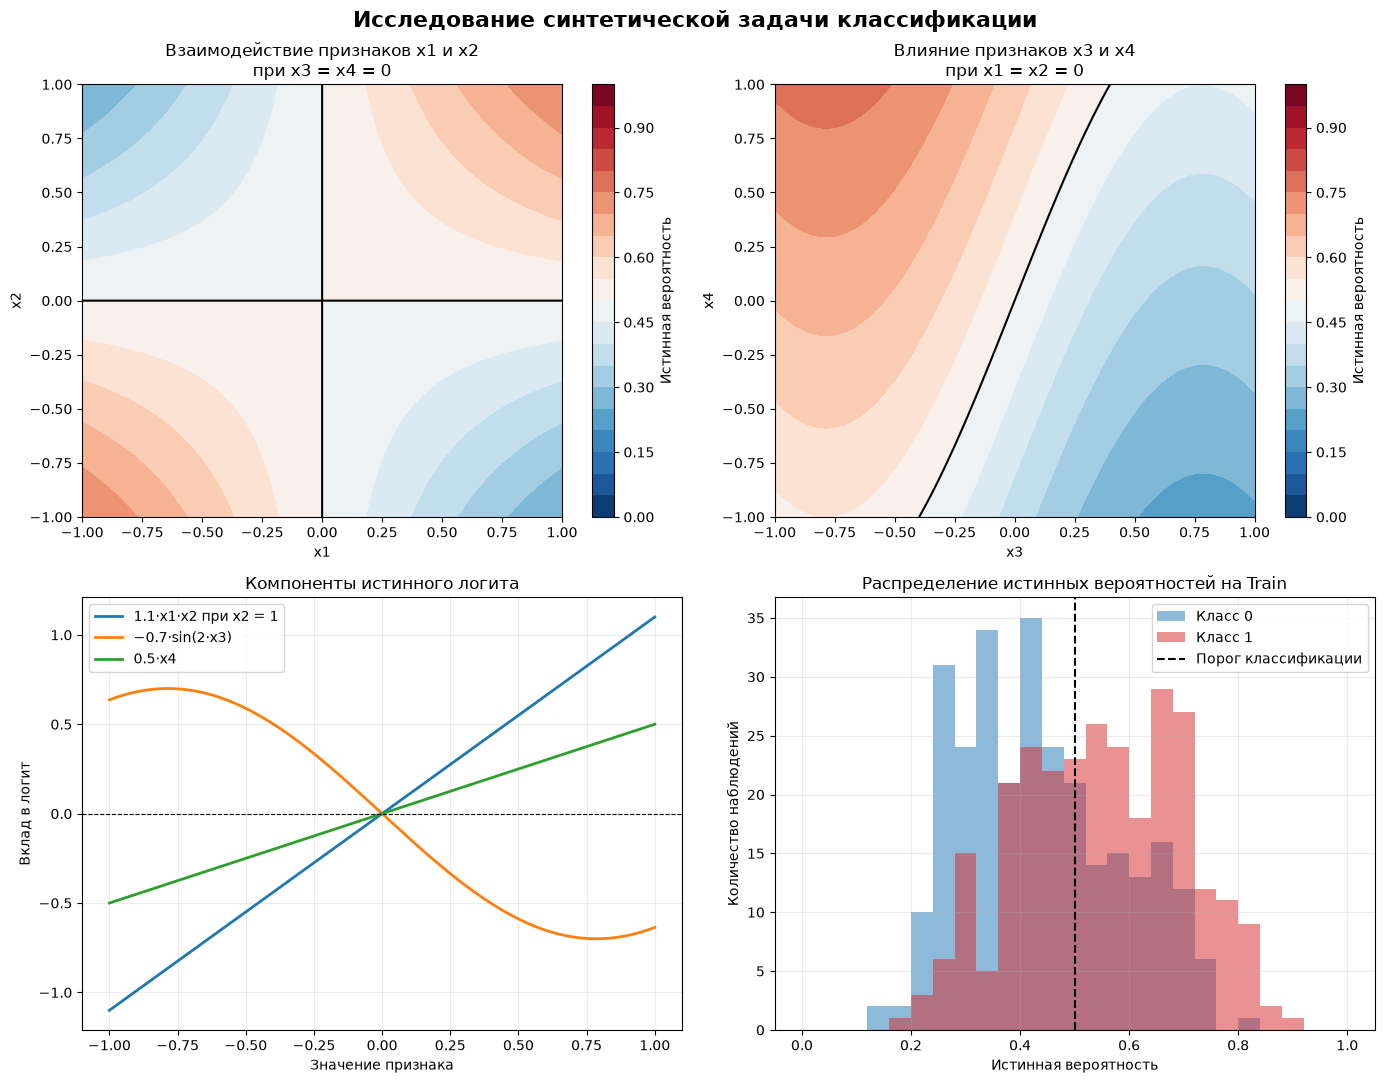


Характеристики неопределённости задачи:


Показатель,Значение
Средняя условная дисперсия Bernoulli,0.22483535
Максимально возможная дисперсия Bernoulli,0.25000000
Доля вероятностей от 0.4 до 0.6,0.40714286
"Доля вероятностей вне интервала (0.2, 0.8)",0.03214286
Ожидаемая байесовская ошибка,0.36571691
Ожидаемая байесовская accuracy,0.63428309
Минимальная ожидаемая BCE,0.64078458
Эмпирическая accuracy истинной функции,0.65178571
Эмпирическая F1-macro истинной функции,0.65109034
Эмпирическая ROC-AUC истинной функции,0.70248345



Все проверки истинной функции пройдены.
Исследование выполнено на обучающей выборке.
Тестовая выборка для оценки моделей не использовалась.


In [2]:
# =============================================
# Проверка численной константы Muon
# =============================================

assert muon_config["ns_eps"] == 1e-7

print(
    "Константа нормализации Muon:",
    f"{muon_config['ns_eps']:.1e}"
)


# =============================================
# Истинная функция вероятностей
# =============================================

def true_probability_function(x1, x2, x3, x4):

    logits = (
        1.1 * x1 * x2
        - 0.7 * np.sin(2 * x3)
        + 0.5 * x4
    )

    return expit(logits)


assert np.allclose(
    true_probability_function(
        X[:, 0],
        X[:, 1],
        X[:, 2],
        X[:, 3]
    ),
    p_true
)


# =============================================
# Вклад отдельных компонентов
# =============================================

X_train_numpy = X_train.numpy()

y_train_numpy = y_train.numpy().ravel()

interaction_component = (
    1.1 * X_train_numpy[:, 0]
    * X_train_numpy[:, 1]
)

nonlinear_component = (
    -0.7 * np.sin(2 * X_train_numpy[:, 2])
)

linear_component = (
    0.5 * X_train_numpy[:, 3]
)

components_df = pd.DataFrame({
    "Взаимодействие x1 и x2": interaction_component,
    "Нелинейный вклад x3": nonlinear_component,
    "Линейный вклад x4": linear_component
})

assert np.allclose(
    components_df.sum(axis=1).to_numpy(),
    true_logits[train_idx]
)

print("\nХарактеристики компонентов истинного логита:")

display(
    components_df.describe()
    .T.style.format(precision=6)
)


# =============================================
# Корреляционный анализ
# =============================================

correlation_data = pd.DataFrame(
    X_train_numpy,
    columns=["x1", "x2", "x3", "x4"]
)

correlation_data["x1*x2"] = (
    X_train_numpy[:, 0]
    * X_train_numpy[:, 1]
)

correlation_data["sin(2*x3)"] = np.sin(
    2 * X_train_numpy[:, 2]
)

correlation_data["p_true"] = p_train_true

correlation_data["y"] = y_train_numpy

correlation_df = correlation_data.corr()

print("\nКорреляции признаков с вероятностью и классом:")

display(
    correlation_df.loc[
        ["x1", "x2", "x3", "x4", "x1*x2", "sin(2*x3)"],
        ["p_true", "y"]
    ]
    .style
    .background_gradient(
        cmap="RdBu_r",
        vmin=-1,
        vmax=1
    )
    .format(precision=6)
)


# =============================================
# Сечения истинной функции вероятностей
# =============================================

grid_values = np.linspace(-1, 1, 200)

X1_grid, X2_grid = np.meshgrid(
    grid_values,
    grid_values
)

X3_grid, X4_grid = np.meshgrid(
    grid_values,
    grid_values
)

# Взаимодействие x1 и x2 при x3 = x4 = 0
probability_interaction = true_probability_function(
    X1_grid,
    X2_grid,
    0,
    0
)

# Влияние x3 и x4 при x1 = x2 = 0
probability_additive = true_probability_function(
    0,
    0,
    X3_grid,
    X4_grid
)


# =============================================
# Визуализация структуры данных
# =============================================

fig, axes = plt.subplots(
    2, 2,
    figsize=(14, 11)
)

levels = np.linspace(0, 1, 21)


# 1. Взаимодействие x1 и x2

contour_1 = axes[0, 0].contourf(
    X1_grid,
    X2_grid,
    probability_interaction,
    levels=levels,
    cmap="RdBu_r"
)

axes[0, 0].contour(
    X1_grid,
    X2_grid,
    probability_interaction,
    levels=[0.5],
    colors="black",
    linewidths=1.5
)

axes[0, 0].set_title(
    "Взаимодействие признаков x1 и x2\n"
    "при x3 = x4 = 0"
)

axes[0, 0].set_xlabel("x1")
axes[0, 0].set_ylabel("x2")

fig.colorbar(
    contour_1,
    ax=axes[0, 0],
    label="Истинная вероятность"
)


# 2. Нелинейное и линейное влияние x3 и x4

contour_2 = axes[0, 1].contourf(
    X3_grid,
    X4_grid,
    probability_additive,
    levels=levels,
    cmap="RdBu_r"
)

axes[0, 1].contour(
    X3_grid,
    X4_grid,
    probability_additive,
    levels=[0.5],
    colors="black",
    linewidths=1.5
)

axes[0, 1].set_title(
    "Влияние признаков x3 и x4\n"
    "при x1 = x2 = 0"
)

axes[0, 1].set_xlabel("x3")
axes[0, 1].set_ylabel("x4")

fig.colorbar(
    contour_2,
    ax=axes[0, 1],
    label="Истинная вероятность"
)


# 3. Сравнение компонентов истинного логита

axes[1, 0].plot(
    grid_values,
    1.1 * grid_values,
    linewidth=2,
    label="1.1·x1·x2 при x2 = 1"
)

axes[1, 0].plot(
    grid_values,
    -0.7 * np.sin(2 * grid_values),
    linewidth=2,
    label="−0.7·sin(2·x3)"
)

axes[1, 0].plot(
    grid_values,
    0.5 * grid_values,
    linewidth=2,
    label="0.5·x4"
)

axes[1, 0].axhline(
    0,
    color="black",
    linestyle="--",
    linewidth=0.8
)

axes[1, 0].set_title(
    "Компоненты истинного логита"
)

axes[1, 0].set_xlabel("Значение признака")
axes[1, 0].set_ylabel("Вклад в логит")

axes[1, 0].legend()
axes[1, 0].grid(alpha=0.25)


# 4. Распределение вероятностей по классам

histogram_bins = np.linspace(0, 1, 26)

axes[1, 1].hist(
    p_train_true[y_train_numpy == 0],
    bins=histogram_bins,
    color="#1f77b4",
    alpha=0.5,
    label="Класс 0"
)

axes[1, 1].hist(
    p_train_true[y_train_numpy == 1],
    bins=histogram_bins,
    color="#d62728",
    alpha=0.5,
    label="Класс 1"
)

axes[1, 1].axvline(
    classification_threshold,
    color="black",
    linestyle="--",
    label="Порог классификации"
)

axes[1, 1].set_title(
    "Распределение истинных вероятностей на Train"
)

axes[1, 1].set_xlabel("Истинная вероятность")
axes[1, 1].set_ylabel("Количество наблюдений")

axes[1, 1].legend()
axes[1, 1].grid(alpha=0.25)

fig.suptitle(
    "Исследование синтетической задачи классификации",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()
plt.show()


# =============================================
# Неопределённость целевой переменной
# =============================================

# Условная дисперсия Bernoulli
conditional_variance = (
    p_train_true * (1 - p_train_true)
)

# Минимальная ожидаемая вероятность ошибки
bayes_error = np.minimum(
    p_train_true,
    1 - p_train_true
)

# Наблюдения с вероятностью, близкой к 0.5
uncertain_mask = (
    (p_train_true >= 0.4)
    & (p_train_true <= 0.6)
)

strong_probability_mask = (
    (p_train_true <= 0.2)
    | (p_train_true >= 0.8)
)

# Предсказания истинного классификатора
true_predictions_train = (
    p_train_true >= classification_threshold
).astype(int)

# Эмпирические метрики истинной функции
true_train_accuracy = accuracy_score(
    y_train_numpy,
    true_predictions_train
)

true_train_f1 = f1_score(
    y_train_numpy,
    true_predictions_train,
    average="macro",
    zero_division=0
)

true_train_auc = roc_auc_score(
    y_train_numpy,
    p_train_true
)

true_train_loss = -np.mean(
    y_train_numpy * np.log(p_train_true)
    + (1 - y_train_numpy) * np.log(1 - p_train_true)
)


# =============================================
# Количественные характеристики задачи
# =============================================

uncertainty_df = pd.DataFrame({
    "Показатель": [
        "Средняя условная дисперсия Bernoulli",
        "Максимально возможная дисперсия Bernoulli",
        "Доля вероятностей от 0.4 до 0.6",
        "Доля вероятностей вне интервала (0.2, 0.8)",
        "Ожидаемая байесовская ошибка",
        "Ожидаемая байесовская accuracy",
        "Минимальная ожидаемая BCE",
        "Эмпирическая accuracy истинной функции",
        "Эмпирическая F1-macro истинной функции",
        "Эмпирическая ROC-AUC истинной функции",
        "Эмпирическая BCE истинной функции"
    ],

    "Значение": [
        conditional_variance.mean(),
        0.25,
        uncertain_mask.mean(),
        strong_probability_mask.mean(),
        bayes_error.mean(),
        expected_bayes_accuracy,
        expected_bayes_loss,
        true_train_accuracy,
        true_train_f1,
        true_train_auc,
        true_train_loss
    ]
})

print("\nХарактеристики неопределённости задачи:")

display(
    uncertainty_df.style
    .hide(axis="index")
    .format({
        "Значение": "{:.8f}"
    })
)


# =============================================
# Проверки свойств истинной функции
# =============================================

# При одинаковых знаках x1 и x2
# вероятность выше 0.5, если x3 = x4 = 0
assert true_probability_function(
    0.8, 0.8, 0, 0
) > 0.5

assert true_probability_function(
    -0.8, -0.8, 0, 0
) > 0.5

# При противоположных знаках вероятность ниже 0.5
assert true_probability_function(
    0.8, -0.8, 0, 0
) < 0.5

# При отсутствии вклада всех признаков
assert true_probability_function(
    0, 0, 0, 0
) == 0.5

# Условная дисперсия Bernoulli не превышает 0.25
assert np.all(conditional_variance <= 0.25)

assert np.isclose(
    bayes_error.mean() + expected_bayes_accuracy,
    1.0
)

print("\nВсе проверки истинной функции пройдены.")

print("Исследование выполнено на обучающей выборке.")

print("Тестовая выборка для оценки моделей не использовалась.")

Структура параметров сети:


Параметр,Размерность,Элементов,Индексы,Оптимизатор
W1,10 × 4,40,0–39,Muon
b1,10,10,40–49,AdamW
W2,1 × 10,10,50–59,AdamW
b2,1,1,60,AdamW



Начальные состояния сети:


Seed,Train loss,Validation loss,Train accuracy,Норма параметров,Норма W1,Норма W2,Доля активных ReLU,Полностью неактивных нейронов,Погрешность прямого прохода
1,0.73618835,0.74713834,49.46%,2.59801624,2.36606402,1.07304682,51.02%,0,0.00000000e+00
2,0.69738201,0.69279408,52.68%,2.33533925,2.00927243,1.19022422,50.43%,0,0.00000000e+00
3,0.70930422,0.69528730,48.75%,2.96466784,2.64414311,1.34080670,49.93%,0,0.00000000e+00
4,0.73511933,0.75028818,46.61%,2.81518484,2.44702594,1.39187992,49.39%,0,0.00000000e+00
5,0.70075348,0.70813064,50.00%,2.49966491,1.99929710,1.50037855,50.23%,0,0.00000000e+00



Границы Xavier Uniform:
W1: [-0.65465367, 0.65465367]
W2: [-0.73854895, 0.73854895]

Характеристики последовательностей мини-батчей:


Seed,Шагов,Завершённых эпох,Полных батчей,Неполных батчей,Обработано наблюдений,Воспроизводимость
1,150,8,142,8,4672,True
2,150,8,142,8,4672,True
3,150,8,142,8,4672,True
4,150,8,142,8,4672,True
5,150,8,142,8,4672,True



Переход между первой и второй эпохами:


Seed,Шаг,Эпоха,Батч в эпохе,Размер батча,Класс 0,Класс 1,Доля класса 1
1,16,1,16,32,13,19,59.38%
1,17,1,17,32,16,16,50.00%
1,18,1,18,16,9,7,43.75%
1,19,2,1,32,22,10,31.25%
1,20,2,2,32,20,12,37.50%
2,16,1,16,32,15,17,53.12%
2,17,1,17,32,15,17,53.12%
2,18,1,18,16,8,8,50.00%
2,19,2,1,32,21,11,34.38%
2,20,2,2,32,16,16,50.00%



Распределение долей положительного класса:


,count,mean,std,min,max
batch_size,,,,,
16,40,0.542188,0.131549,0.250000,0.812500
32,710,0.497579,0.086885,0.187500,0.750000


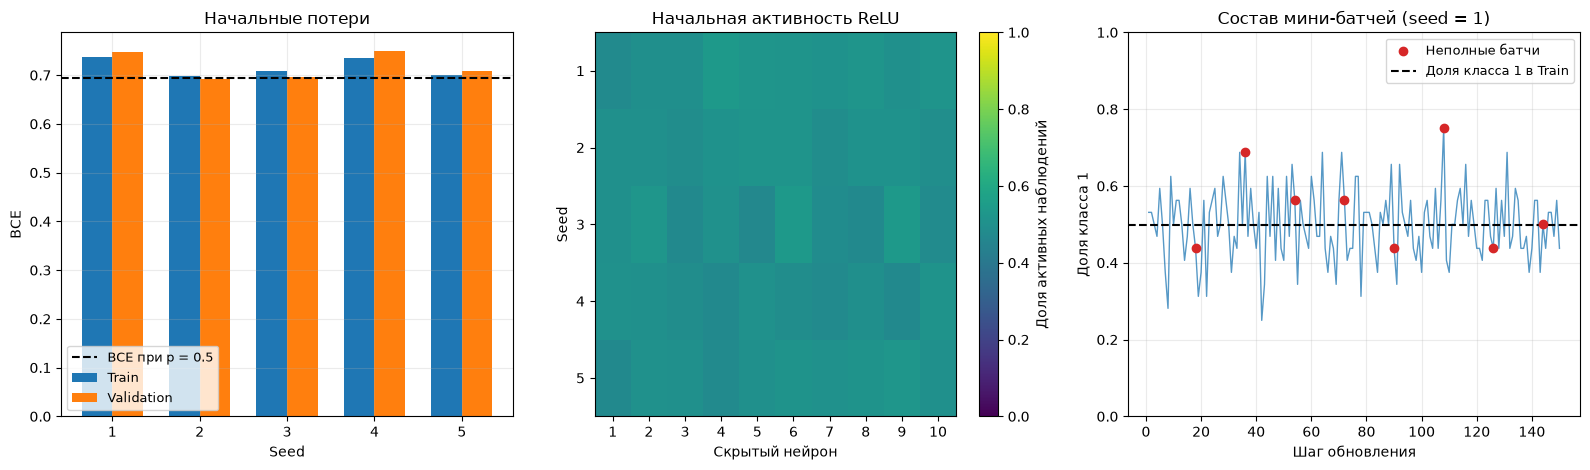


Все проверки пройдены.
Нейронная сеть содержит 61 параметр.
Muon будет обновлять только матрицу W1.
Остальные 21 параметр будут обновляться AdamW.
Подготовлены пять воспроизводимых инициализаций.
Подготовлены пять последовательностей по 150 мини-батчей.
Внутри каждого повтора все методы используют общие условия.
Обучение ещё не выполнялось.
Тестовая выборка для оценки моделей не использовалась.


In [3]:
# =============================================
# Архитектура нейронной сети
# =============================================

class ClassificationNetwork(nn.Module):

    def __init__(self):

        super().__init__()

        self.fc1 = nn.Linear(
            input_size,
            hidden_size
        )

        self.fc2 = nn.Linear(
            hidden_size,
            output_size
        )

    def forward(self, X_data):

        hidden = F.relu(self.fc1(X_data))

        logits = self.fc2(hidden)

        return logits


# =============================================
# Инициализация параметров
# =============================================

def initialize_network(network_seed):

    torch.manual_seed(network_seed)

    model = ClassificationNetwork().to(
        device=device,
        dtype=torch.float64
    )

    with torch.no_grad():

        nn.init.xavier_uniform_(model.fc1.weight)
        nn.init.xavier_uniform_(model.fc2.weight)

        nn.init.zeros_(model.fc1.bias)
        nn.init.zeros_(model.fc2.bias)

    return model


# =============================================
# Преобразование параметров в единый вектор
# =============================================

def get_parameters(model):

    return torch.cat([
        model.fc1.weight.detach().reshape(-1),
        model.fc1.bias.detach().reshape(-1),
        model.fc2.weight.detach().reshape(-1),
        model.fc2.bias.detach().reshape(-1)
    ]).clone()


# Границы отдельных блоков параметров

w1_end = input_size * hidden_size

b1_end = w1_end + hidden_size

w2_end = b1_end + hidden_size * output_size

b2_end = w2_end + output_size

assert b2_end == n_parameters


def unpack_parameters(theta):

    assert theta.numel() == n_parameters

    W1 = theta[:w1_end].reshape(
        hidden_size,
        input_size
    )

    b1 = theta[w1_end:b1_end]

    W2 = theta[b1_end:w2_end].reshape(
        output_size,
        hidden_size
    )

    b2 = theta[w2_end:b2_end]

    return W1, b1, W2, b2


def pack_parameters(W1, b1, W2, b2):

    return torch.cat([
        W1.reshape(-1),
        b1.reshape(-1),
        W2.reshape(-1),
        b2.reshape(-1)
    ])


# =============================================
# Разделение параметров между оптимизаторами
# =============================================

parameter_groups = {
    "W1": slice(0, w1_end),
    "b1": slice(w1_end, b1_end),
    "W2": slice(b1_end, w2_end),
    "b2": slice(w2_end, b2_end)
}

muon_slice = slice(0, w1_end)

adamw_slice = slice(w1_end, n_parameters)

parameter_layout_df = pd.DataFrame([
    {
        "Параметр": "W1",
        "Размерность": "10 × 4",
        "Элементов": 40,
        "Индексы": "0–39",
        "Оптимизатор": "Muon"
    },
    {
        "Параметр": "b1",
        "Размерность": "10",
        "Элементов": 10,
        "Индексы": "40–49",
        "Оптимизатор": "AdamW"
    },
    {
        "Параметр": "W2",
        "Размерность": "1 × 10",
        "Элементов": 10,
        "Индексы": "50–59",
        "Оптимизатор": "AdamW"
    },
    {
        "Параметр": "b2",
        "Размерность": "1",
        "Элементов": 1,
        "Индексы": "60",
        "Оптимизатор": "AdamW"
    }
])

print("Структура параметров сети:")

display(
    parameter_layout_df.style.hide(axis="index")
)


# =============================================
# Прямой проход через вектор параметров
# =============================================

def forward_logits(theta, X_data):

    W1, b1, W2, b2 = unpack_parameters(theta)

    hidden_pre_activation = X_data @ W1.T + b1

    hidden = F.relu(hidden_pre_activation)

    logits = hidden @ W2.T + b2

    return logits


def predict_proba(theta, X_data):

    return torch.sigmoid(
        forward_logits(theta, X_data)
    )


loss_function = nn.BCEWithLogitsLoss(
    reduction="mean"
)


def loss_value(theta, X_data, y_data):

    logits = forward_logits(theta, X_data)

    return loss_function(logits, y_data)


# =============================================
# Начальные параметры пяти повторений
# =============================================

initial_parameters = {}

initialization_records = []

xavier_bound_W1 = np.sqrt(
    6 / (input_size + hidden_size)
)

xavier_bound_W2 = np.sqrt(
    6 / (hidden_size + output_size)
)

for network_seed in network_seeds:

    model = initialize_network(network_seed)

    theta = get_parameters(model)

    W1, b1, W2, b2 = unpack_parameters(theta)

    assert theta.shape == (61,)

    assert theta.dtype == torch.float64

    assert W1.shape == (10, 4)
    assert b1.shape == (10,)
    assert W2.shape == (1, 10)
    assert b2.shape == (1,)

    assert torch.all(b1 == 0)
    assert torch.all(b2 == 0)

    assert torch.max(
        torch.abs(W1)
    ).item() <= xavier_bound_W1

    assert torch.max(
        torch.abs(W2)
    ).item() <= xavier_bound_W2

    # Проверка обратного преобразования параметров
    assert torch.equal(
        pack_parameters(W1, b1, W2, b2),
        theta
    )

    # Проверка воспроизводимости инициализации
    repeated_model = initialize_network(network_seed)

    repeated_theta = get_parameters(repeated_model)

    assert torch.equal(theta, repeated_theta)

    # Проверка распределения параметров
    assert theta[muon_slice].numel() == 40

    assert theta[adamw_slice].numel() == 21

    initial_parameters[network_seed] = theta.clone()

    with torch.no_grad():

        # Сравнение двух реализаций прямого прохода
        module_logits = model(X_train)

        vector_logits = forward_logits(
            theta,
            X_train
        )

        forward_error = torch.max(
            torch.abs(
                module_logits - vector_logits
            )
        ).item()

        assert torch.allclose(
            module_logits,
            vector_logits,
            atol=1e-12,
            rtol=1e-10
        )

        train_loss = loss_value(
            theta,
            X_train,
            y_train
        ).item()

        validation_loss = loss_value(
            theta,
            X_val,
            y_val
        ).item()

        probabilities = predict_proba(
            theta,
            X_train
        )

        predictions = (
            probabilities >= classification_threshold
        ).to(torch.float64)

        train_accuracy = (
            predictions == y_train
        ).double().mean().item()

        # Активность скрытых нейронов
        pre_activation = X_train @ W1.T + b1

        active_mask = pre_activation > 0

        active_share = (
            active_mask.double().mean().item()
        )

        active_share_by_neuron = (
            active_mask.double()
            .mean(dim=0)
            .numpy()
        )

        inactive_neurons = int(
            (active_share_by_neuron == 0).sum()
        )

        initialization_records.append({
            "Seed": network_seed,

            "Train loss": train_loss,

            "Validation loss": validation_loss,

            "Train accuracy": train_accuracy,

            "Норма параметров": (
                torch.linalg.vector_norm(theta).item()
            ),

            "Норма W1": (
                torch.linalg.matrix_norm(W1).item()
            ),

            "Норма W2": (
                torch.linalg.matrix_norm(W2).item()
            ),

            "Доля активных ReLU": active_share,

            "Полностью неактивных нейронов": (
                inactive_neurons
            ),

            "Погрешность прямого прохода": (
                forward_error
            )
        })


initialization_df = pd.DataFrame(
    initialization_records
)

print("\nНачальные состояния сети:")

display(
    initialization_df.style
    .hide(axis="index")
    .format({
        "Train loss": "{:.8f}",

        "Validation loss": "{:.8f}",

        "Train accuracy": "{:.2%}",

        "Норма параметров": "{:.8f}",

        "Норма W1": "{:.8f}",

        "Норма W2": "{:.8f}",

        "Доля активных ReLU": "{:.2%}",

        "Погрешность прямого прохода": "{:.8e}"
    })
)


# Проверка различий между инициализациями

for i, seed_i in enumerate(network_seeds):

    for seed_j in network_seeds[i + 1:]:

        assert not torch.equal(
            initial_parameters[seed_i],
            initial_parameters[seed_j]
        )

print("\nГраницы Xavier Uniform:")

print(
    f"W1: [{-xavier_bound_W1:.8f}, "
    f"{xavier_bound_W1:.8f}]"
)

print(
    f"W2: [{-xavier_bound_W2:.8f}, "
    f"{xavier_bound_W2:.8f}]"
)


# =============================================
# Генерация последовательности мини-батчей
# =============================================

def generate_batch_schedule(
    network_seed,
    n_steps=iterations
):

    batch_rng = np.random.default_rng(
        network_seed
    )

    schedule = []

    epoch = 0

    while len(schedule) < n_steps:

        epoch += 1

        permutation = batch_rng.permutation(
            n_train
        )

        batch_in_epoch = 0

        for start in range(
            0,
            n_train,
            batch_size
        ):

            if len(schedule) >= n_steps:

                break

            batch_in_epoch += 1

            local_indices = permutation[
                start:start + batch_size
            ].copy()

            schedule.append({
                "step": len(schedule) + 1,

                "epoch": epoch,

                "batch_in_epoch": batch_in_epoch,

                "batch_size": len(local_indices),

                "indices": torch.tensor(
                    local_indices,
                    dtype=torch.long,
                    device=device
                ),

                "original_indices": (
                    train_idx[local_indices].copy()
                )
            })

    return schedule


batch_schedules = {
    network_seed: generate_batch_schedule(
        network_seed
    )

    for network_seed in network_seeds
}


# =============================================
# Проверка последовательностей мини-батчей
# =============================================

schedule_records = []

for network_seed in network_seeds:

    schedule = batch_schedules[network_seed]

    assert len(schedule) == iterations

    # Повторная генерация должна дать
    # ту же последовательность
    repeated_schedule = generate_batch_schedule(
        network_seed
    )

    for record, repeated in zip(
        schedule,
        repeated_schedule
    ):

        assert torch.equal(
            record["indices"],
            repeated["indices"]
        )

        assert np.array_equal(
            record["original_indices"],
            repeated["original_indices"]
        )

        assert record["step"] == repeated["step"]

        assert record["epoch"] == repeated["epoch"]

        assert record["batch_size"] in (16, 32)

        assert len(
            np.unique(record["original_indices"])
        ) == record["batch_size"]

        assert np.all(
            np.isin(
                record["original_indices"],
                train_idx
            )
        )

        assert not np.isin(
            record["original_indices"],
            val_idx
        ).any()

        assert not np.isin(
            record["original_indices"],
            test_idx
        ).any()

    # Каждая завершённая эпоха содержит
    # все обучающие наблюдения ровно один раз

    for epoch in range(
        1,
        completed_epochs + 1
    ):

        epoch_indices = np.concatenate([
            record["original_indices"]

            for record in schedule

            if record["epoch"] == epoch
        ])

        assert len(epoch_indices) == n_train

        assert np.array_equal(
            np.sort(epoch_indices),
            np.sort(train_idx)
        )

    processed_samples = sum(
        record["batch_size"]
        for record in schedule
    )

    full_batches = sum(
        record["batch_size"] == batch_size
        for record in schedule
    )

    partial_batches = sum(
        record["batch_size"] < batch_size
        for record in schedule
    )

    assert processed_samples == expected_processed_samples

    assert full_batches == expected_full_batches

    assert partial_batches == expected_partial_batches

    schedule_records.append({
        "Seed": network_seed,

        "Шагов": len(schedule),

        "Завершённых эпох": completed_epochs,

        "Полных батчей": full_batches,

        "Неполных батчей": partial_batches,

        "Обработано наблюдений": processed_samples,

        "Воспроизводимость": True
    })


schedule_df = pd.DataFrame(schedule_records)

print("\nХарактеристики последовательностей мини-батчей:")

display(
    schedule_df.style.hide(axis="index")
)


# =============================================
# Проверка различий между повторами
# =============================================

for i, seed_i in enumerate(network_seeds):

    for seed_j in network_seeds[i + 1:]:

        same_schedule = all(
            torch.equal(
                record_i["indices"],
                record_j["indices"]
            )

            for record_i, record_j in zip(
                batch_schedules[seed_i],
                batch_schedules[seed_j]
            )
        )

        assert not same_schedule


# =============================================
# Проверка перехода между эпохами
# =============================================

transition_records = []

for network_seed in network_seeds:

    schedule = batch_schedules[network_seed]

    for record in schedule[15:20]:

        targets = y_train[record["indices"]]

        transition_records.append({
            "Seed": network_seed,

            "Шаг": record["step"],

            "Эпоха": record["epoch"],

            "Батч в эпохе": record["batch_in_epoch"],

            "Размер батча": record["batch_size"],

            "Класс 0": int((targets == 0).sum()),

            "Класс 1": int((targets == 1).sum()),

            "Доля класса 1": targets.mean().item()
        })


transition_df = pd.DataFrame(
    transition_records
)

print("\nПереход между первой и второй эпохами:")

display(
    transition_df.style
    .hide(axis="index")
    .format({
        "Доля класса 1": "{:.2%}"
    })
)


# =============================================
# Распределение классов по мини-батчам
# =============================================

batch_distribution_records = []

for network_seed in network_seeds:

    for record in batch_schedules[network_seed]:

        targets = y_train[record["indices"]]

        batch_distribution_records.append({
            "seed": network_seed,

            "iteration": record["step"],

            "epoch": record["epoch"],

            "batch_size": record["batch_size"],

            "positive_share": targets.mean().item()
        })


batch_distribution_df = pd.DataFrame(
    batch_distribution_records
)

batch_distribution_stats = (
    batch_distribution_df
    .groupby("batch_size")["positive_share"]
    .agg(["count", "mean", "std", "min", "max"])
)

print("\nРаспределение долей положительного класса:")

display(
    batch_distribution_stats.style.format(
        precision=6
    )
)


# =============================================
# Визуализация начальных условий
# =============================================

fig, axes = plt.subplots(
    1, 3,
    figsize=(16, 4.8)
)

# Начальные значения функции потерь

positions = np.arange(n_repeats)

width = 0.35

axes[0].bar(
    positions - width / 2,
    initialization_df["Train loss"],
    width=width,
    label="Train",
    color="#1f77b4"
)

axes[0].bar(
    positions + width / 2,
    initialization_df["Validation loss"],
    width=width,
    label="Validation",
    color="#ff7f0e"
)

axes[0].axhline(
    constant_loss,
    color="black",
    linestyle="--",
    label="BCE при p = 0.5"
)

axes[0].set_xticks(
    positions,
    network_seeds
)

axes[0].set_title("Начальные потери")

axes[0].set_xlabel("Seed")

axes[0].set_ylabel("BCE")

axes[0].legend(fontsize=9)


# Начальная активность скрытых нейронов

activation_matrix = []

for network_seed in network_seeds:

    W1, b1, _, _ = unpack_parameters(
        initial_parameters[network_seed]
    )

    active_fraction = (
        ((X_train @ W1.T + b1) > 0)
        .double()
        .mean(dim=0)
        .numpy()
    )

    activation_matrix.append(active_fraction)

activation_matrix = np.array(
    activation_matrix
)

heatmap = axes[1].imshow(
    activation_matrix,
    cmap="viridis",
    aspect="auto",
    vmin=0,
    vmax=1
)

axes[1].set_xticks(
    np.arange(hidden_size),
    np.arange(1, hidden_size + 1)
)

axes[1].set_yticks(
    np.arange(n_repeats),
    network_seeds
)

axes[1].set_title("Начальная активность ReLU")

axes[1].set_xlabel("Скрытый нейрон")

axes[1].set_ylabel("Seed")

fig.colorbar(
    heatmap,
    ax=axes[1],
    label="Доля активных наблюдений"
)


# Состав мини-батчей первого повтора

first_seed_batches = batch_distribution_df[
    batch_distribution_df["seed"] == 1
]

axes[2].plot(
    first_seed_batches["iteration"],
    first_seed_batches["positive_share"],
    color="#1f77b4",
    linewidth=1,
    alpha=0.75
)

partial_mask = (
    first_seed_batches["batch_size"] < batch_size
)

axes[2].scatter(
    first_seed_batches.loc[
        partial_mask,
        "iteration"
    ],

    first_seed_batches.loc[
        partial_mask,
        "positive_share"
    ],

    color="#d62728",
    label="Неполные батчи",
    zorder=5
)

axes[2].axhline(
    y_train.mean().item(),
    color="black",
    linestyle="--",
    label="Доля класса 1 в Train"
)

axes[2].set_title(
    "Состав мини-батчей (seed = 1)"
)

axes[2].set_xlabel("Шаг обновления")

axes[2].set_ylabel("Доля класса 1")

axes[2].set_ylim(0, 1)

axes[2].legend(fontsize=9)

for ax in [axes[0], axes[2]]:

    ax.grid(alpha=0.25)

plt.tight_layout()
plt.show()


# =============================================
# Итоговые проверки
# =============================================

assert len(initial_parameters) == 5

assert len(batch_schedules) == 5

assert len(batch_distribution_df) == 750

assert (
    initialization_df[
        "Погрешность прямого прохода"
    ].max() < 1e-10
)

print("\nВсе проверки пройдены.")

print("Нейронная сеть содержит 61 параметр.")

print("Muon будет обновлять только матрицу W1.")

print("Остальные 21 параметр будут обновляться AdamW.")

print("Подготовлены пять воспроизводимых инициализаций.")

print("Подготовлены пять последовательностей по 150 мини-батчей.")

print("Внутри каждого повтора все методы используют общие условия.")

print("Обучение ещё не выполнялось.")

print("Тестовая выборка для оценки моделей не использовалась.")

Проверка производной ReLU:


,Вход,ReLU,Производная
0,-1.0,0.0,0.0
1,0.0,0.0,0.0
2,1.0,1.0,1.0



Проверка градиентов:


Seed,Выборка,Наблюдений,Loss,Норма полного вектора градиента,Норма градиента W1,Ошибка аналитического градиента,Ошибка численного градиента,Параметров с пересечением излома,Численная ошибка вне изломов
1,Полная Train,560,0.73618835,0.16849902,0.07314232,0.00000000e+00,1.34670677e-11,0,1.34670677e-11
1,Батч 1,32,0.69612724,0.11414704,0.07975205,0.00000000e+00,9.74096173e-12,0,9.74096173e-12
1,Батч 18,16,0.77520176,0.30198577,0.13673291,0.00000000e+00,1.05109984e-11,0,1.05109984e-11
1,Батч 19,32,0.78291167,0.40615199,0.13312685,0.00000000e+00,1.08163253e-11,0,1.08163253e-11
2,Полная Train,560,0.69738201,0.07475472,0.05362643,0.00000000e+00,1.28863354e-11,0,1.28863354e-11
2,Батч 1,32,0.68368093,0.17451046,0.08079502,0.00000000e+00,1.36050195e-11,0,1.36050195e-11
2,Батч 18,16,0.67942438,0.26250208,0.19755357,0.00000000e+00,8.94328361e-12,0,8.94328361e-12
2,Батч 19,32,0.67997221,0.18968527,0.08096350,0.00000000e+00,1.10585048e-11,0,1.10585048e-11
3,Полная Train,560,0.70930422,0.12723431,0.07508685,0.00000000e+00,1.06386594e-11,0,1.06386594e-11
3,Батч 1,32,0.70007977,0.15100837,0.07209564,0.00000000e+00,9.05517154e-12,0,9.05517154e-12



Восстановление полного градиента:


Seed,Наблюдений,Полная Train BCE,Взвешенная BCE батчей,Ошибка функции потерь,Ошибка градиента
1,560,0.73618835,0.73618835,2.22044605e-16,2.42861287e-17
2,560,0.69738201,0.69738201,0.00000000e+00,1.38777878e-17
3,560,0.70930422,0.70930422,1.11022302e-16,2.08166817e-17
4,560,0.73511933,0.73511933,1.11022302e-16,2.08166817e-17
5,560,0.70075348,0.70075348,0.00000000e+00,1.38777878e-17



Характеристики стохастических градиентов W1:


,Количество батчей,Норма градиента,Отклонение от полного градиента,Косинусное сходство,Разность градиентов,Стабильный ранг,Отношение min/max сингулярных значений
batch_size,,,,,,,
16,40,0.14826212,0.13210992,0.44255726,0.17061701,1.31710542,0.11768515
32,710,0.11397593,0.09028078,0.60442576,0.13240985,1.28345460,0.11292082



Относительные сингулярные значения градиентов W1:


Размер батча,Сингулярная компонента,Среднее,Стандартное отклонение
16,1,1.00000000,0.00000000
16,2,0.45483827,0.16074161
16,3,0.24163936,0.09815379
16,4,0.11768515,0.05907803
32,1,1.00000000,0.00000000
32,2,0.42455843,0.16207977
32,3,0.22617012,0.09839469
32,4,0.11292082,0.05835044


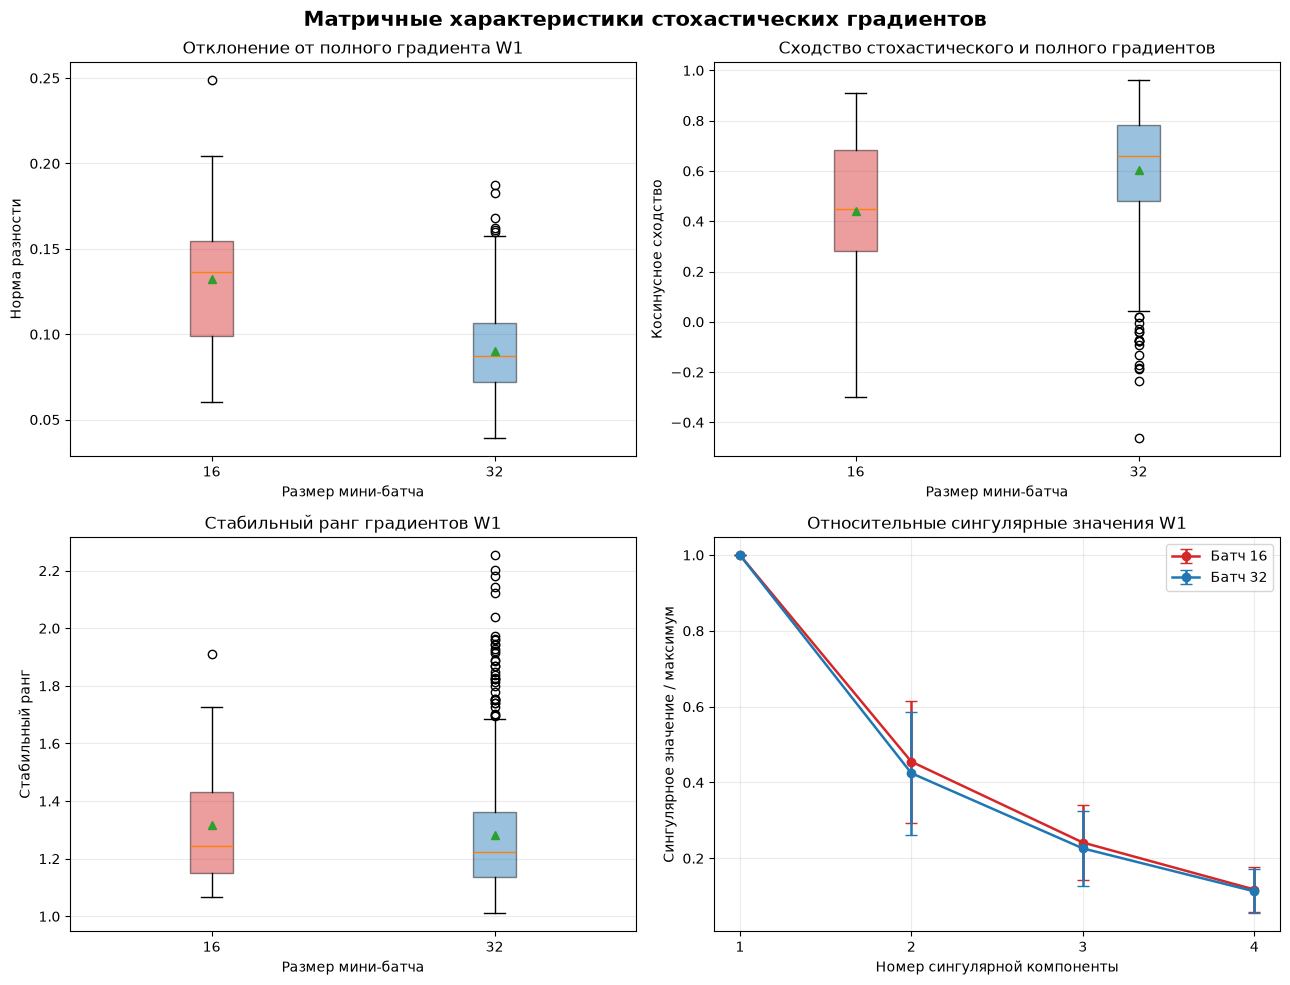


Максимальная ошибка аналитического градиента:
0.00000000e+00

Максимальная ошибка конечных разностей вне изломов:
1.36050195e-11

Максимальная ошибка восстановления полного градиента:
2.42861287e-17

Количество проверенных градиентов: 20
Количество исследованных матриц W1: 750
Количество исследованных сингулярных значений: 3000

Все проверки градиентов пройдены.
Параметры сети не обновлялись.
SVD использовалось только для диагностики.
Диагностические операции не входят в бюджет обучения.
Тестовая выборка для оценки моделей не использовалась.


In [4]:
# =============================================
# Вычисление функции потерь и градиента
# =============================================

def evaluate_loss(theta, X_data, y_data):

    with torch.no_grad():

        return loss_value(
            theta, X_data, y_data
        ).item()


def evaluate_loss_gradient(theta, X_data, y_data):

    theta_variable = (
        theta.detach()
        .clone()
        .requires_grad_(True)
    )

    loss = loss_value(
        theta_variable,
        X_data,
        y_data
    )

    gradient = torch.autograd.grad(
        loss,
        theta_variable
    )[0]

    return loss.item(), gradient.detach()


# =============================================
# Аналитическое вычисление градиента
# =============================================

@torch.no_grad()
def analytical_gradient(theta, X_data, y_data):

    W1, b1, W2, b2 = unpack_parameters(theta)

    sample_count = len(X_data)

    # Прямой проход
    pre_activation = X_data @ W1.T + b1

    hidden = torch.relu(pre_activation)

    logits = hidden @ W2.T + b2

    probabilities = torch.sigmoid(logits)

    # Производная BCEWithLogitsLoss
    delta2 = (
        probabilities - y_data
    ) / sample_count

    grad_W2 = delta2.T @ hidden

    grad_b2 = delta2.sum(dim=0)

    # Производная ReLU
    relu_derivative = (
        pre_activation > 0
    ).to(theta.dtype)

    # Обратное распространение
    delta1 = (
        delta2 @ W2
    ) * relu_derivative

    grad_W1 = delta1.T @ X_data

    grad_b1 = delta1.sum(dim=0)

    return pack_parameters(
        grad_W1,
        grad_b1,
        grad_W2,
        grad_b2
    )


# =============================================
# Численное вычисление градиента
# =============================================

def numerical_gradient(
    theta,
    X_data,
    y_data,
    epsilon=1e-5
):

    gradient = torch.zeros_like(theta)

    for j in range(theta.numel()):

        theta_plus = theta.clone()

        theta_minus = theta.clone()

        theta_plus[j] += epsilon

        theta_minus[j] -= epsilon

        loss_plus = evaluate_loss(
            theta_plus, X_data, y_data
        )

        loss_minus = evaluate_loss(
            theta_minus, X_data, y_data
        )

        gradient[j] = (
            loss_plus - loss_minus
        ) / (2 * epsilon)

    return gradient


# =============================================
# Проверка производной ReLU в нуле
# =============================================

relu_input = torch.tensor(
    [-1.0, 0.0, 1.0],
    requires_grad=True
)

relu_output = F.relu(relu_input)

relu_gradient = torch.autograd.grad(
    relu_output.sum(),
    relu_input
)[0]

assert torch.equal(
    relu_gradient,
    torch.tensor([0.0, 0.0, 1.0])
)

print("Проверка производной ReLU:")

display(pd.DataFrame({
    "Вход": relu_input.detach().numpy(),
    "ReLU": relu_output.detach().numpy(),
    "Производная": relu_gradient.numpy()
}))


# =============================================
# Проверка пересечения точек излома ReLU
# при вычислении конечных разностей
# =============================================

@torch.no_grad()
def detect_relu_crossings(
    theta,
    X_data,
    epsilon=1e-5
):

    crossing_parameters = []

    # Только W1 и b1 влияют на аргументы ReLU
    for j in range(b1_end):

        theta_plus = theta.clone()

        theta_minus = theta.clone()

        theta_plus[j] += epsilon

        theta_minus[j] -= epsilon

        W1_plus, b1_plus, _, _ = unpack_parameters(
            theta_plus
        )

        W1_minus, b1_minus, _, _ = unpack_parameters(
            theta_minus
        )

        activation_plus = (
            X_data @ W1_plus.T + b1_plus
        )

        activation_minus = (
            X_data @ W1_minus.T + b1_minus
        )

        crossing = (
            (activation_plus > 0)
            != (activation_minus > 0)
        )

        if crossing.any().item():

            crossing_parameters.append(j)

    return crossing_parameters


# =============================================
# Проверка градиентов для пяти инициализаций
# =============================================

gradient_check_records = []

finite_difference_eps = 1e-5

for network_seed in network_seeds:

    theta = initial_parameters[network_seed]

    schedule = batch_schedules[network_seed]

    check_samples = [
        (
            "Полная Train",
            X_train,
            y_train
        ),

        (
            "Батч 1",
            X_train[schedule[0]["indices"]],
            y_train[schedule[0]["indices"]]
        ),

        (
            "Батч 18",
            X_train[schedule[17]["indices"]],
            y_train[schedule[17]["indices"]]
        ),

        (
            "Батч 19",
            X_train[schedule[18]["indices"]],
            y_train[schedule[18]["indices"]]
        )
    ]

    for sample_name, X_data, y_data in check_samples:

        loss, gradient_auto = evaluate_loss_gradient(
            theta,
            X_data,
            y_data
        )

        gradient_analytical = analytical_gradient(
            theta,
            X_data,
            y_data
        )

        gradient_numerical = numerical_gradient(
            theta,
            X_data,
            y_data,
            epsilon=finite_difference_eps
        )

        # Проверка аналитического градиента
        analytical_error = torch.max(
            torch.abs(
                gradient_auto - gradient_analytical
            )
        ).item()

        assert torch.allclose(
            gradient_auto,
            gradient_analytical,
            atol=1e-12,
            rtol=1e-10
        )

        # Проверка конечных разностей
        numerical_error = torch.abs(
            gradient_auto - gradient_numerical
        )

        # Вблизи изломов ReLU центральные
        # конечные разности могут отличаться
        # от производной PyTorch

        crossing_indices = detect_relu_crossings(
            theta,
            X_data,
            epsilon=finite_difference_eps
        )

        smooth_mask = torch.ones(
            n_parameters,
            dtype=torch.bool
        )

        if crossing_indices:

            smooth_mask[crossing_indices] = False

        smooth_error = numerical_error[
            smooth_mask
        ].max().item()

        assert smooth_error < 1e-8

        assert torch.isfinite(gradient_auto).all()

        assert torch.isfinite(
            gradient_numerical
        ).all()

        assert gradient_auto.shape == (
            n_parameters,
        )

        grad_W1, grad_b1, grad_W2, grad_b2 = (
            unpack_parameters(gradient_auto)
        )

        assert grad_W1.shape == (10, 4)

        gradient_check_records.append({
            "Seed": network_seed,

            "Выборка": sample_name,

            "Наблюдений": len(X_data),

            "Loss": loss,

            "Норма полного вектора градиента": (
                torch.linalg.vector_norm(
                    gradient_auto
                ).item()
            ),

            "Норма градиента W1": (
                torch.linalg.matrix_norm(
                    grad_W1
                ).item()
            ),

            "Ошибка аналитического градиента": (
                analytical_error
            ),

            "Ошибка численного градиента": (
                numerical_error.max().item()
            ),

            "Параметров с пересечением излома": (
                len(crossing_indices)
            ),

            "Численная ошибка вне изломов": (
                smooth_error
            )
        })


gradient_check_df = pd.DataFrame(
    gradient_check_records
)

print("\nПроверка градиентов:")

display(
    gradient_check_df.style
    .hide(axis="index")
    .format({
        "Loss": "{:.8f}",

        "Норма полного вектора градиента": "{:.8f}",

        "Норма градиента W1": "{:.8f}",

        "Ошибка аналитического градиента": "{:.8e}",

        "Ошибка численного градиента": "{:.8e}",

        "Численная ошибка вне изломов": "{:.8e}"
    })
)

assert len(gradient_check_df) == 20


# =============================================
# Проверка восстановления полного градиента
# из взвешенных градиентов мини-батчей
# =============================================

epoch_gradient_records = []

for network_seed in network_seeds:

    theta = initial_parameters[network_seed]

    full_loss, full_gradient = evaluate_loss_gradient(
        theta,
        X_train,
        y_train
    )

    weighted_gradient = torch.zeros_like(theta)

    weighted_loss = 0.0

    total_samples = 0

    first_epoch_schedule = [
        record
        for record in batch_schedules[network_seed]
        if record["epoch"] == 1
    ]

    assert len(first_epoch_schedule) == 18

    for record in first_epoch_schedule:

        X_batch = X_train[record["indices"]]

        y_batch = y_train[record["indices"]]

        batch_loss, batch_gradient = (
            evaluate_loss_gradient(
                theta,
                X_batch,
                y_batch
            )
        )

        current_batch_size = record["batch_size"]

        weighted_gradient += (
            current_batch_size * batch_gradient
        )

        weighted_loss += (
            current_batch_size * batch_loss
        )

        total_samples += current_batch_size

    weighted_gradient /= total_samples

    weighted_loss /= total_samples

    gradient_error = torch.max(
        torch.abs(
            weighted_gradient - full_gradient
        )
    ).item()

    loss_error = abs(
        weighted_loss - full_loss
    )

    assert total_samples == n_train

    assert gradient_error < 1e-12

    assert loss_error < 1e-12

    epoch_gradient_records.append({
        "Seed": network_seed,

        "Наблюдений": total_samples,

        "Полная Train BCE": full_loss,

        "Взвешенная BCE батчей": weighted_loss,

        "Ошибка функции потерь": loss_error,

        "Ошибка градиента": gradient_error
    })


epoch_gradient_df = pd.DataFrame(
    epoch_gradient_records
)

print("\nВосстановление полного градиента:")

display(
    epoch_gradient_df.style
    .hide(axis="index")
    .format({
        "Полная Train BCE": "{:.8f}",

        "Взвешенная BCE батчей": "{:.8f}",

        "Ошибка функции потерь": "{:.8e}",

        "Ошибка градиента": "{:.8e}"
    })
)


# =============================================
# Вспомогательные матричные характеристики
# =============================================

@torch.no_grad()
def stable_rank(matrix):

    singular_values = torch.linalg.svdvals(
        matrix
    )

    max_value = singular_values.max()

    if max_value.item() == 0:

        return 0.0

    return (
        singular_values.square().sum()
        / max_value.square()
    ).item()


@torch.no_grad()
def matrix_cosine(matrix_a, matrix_b):

    norm_a = torch.linalg.matrix_norm(
        matrix_a
    ).item()

    norm_b = torch.linalg.matrix_norm(
        matrix_b
    ).item()

    if norm_a == 0 or norm_b == 0:

        return np.nan

    return (
        torch.sum(matrix_a * matrix_b).item()
        / (norm_a * norm_b)
    )


# =============================================
# Исследование стохастичности градиентов W1
# =============================================
# Параметры сети остаются неизменными.
# Изменяется только состав мини-батча.

matrix_gradient_records = []

spectral_gradient_records = []

for network_seed in network_seeds:

    theta = initial_parameters[network_seed]

    _, full_gradient = evaluate_loss_gradient(
        theta,
        X_train,
        y_train
    )

    full_G = unpack_parameters(
        full_gradient
    )[0]

    previous_G = None

    for record in batch_schedules[network_seed]:

        _, batch_gradient = evaluate_loss_gradient(
            theta,
            X_train[record["indices"]],
            y_train[record["indices"]]
        )

        G = unpack_parameters(
            batch_gradient
        )[0]

        singular_values = torch.linalg.svdvals(G)

        full_norm = torch.linalg.matrix_norm(
            full_G
        ).item()

        gradient_norm = torch.linalg.matrix_norm(
            G
        ).item()

        gradient_error = torch.linalg.matrix_norm(
            G - full_G
        ).item()

        difference_norm = (
            torch.linalg.matrix_norm(
                G - previous_G
            ).item()

            if previous_G is not None

            else np.nan
        )

        # Относительная величина самой слабой
        # сингулярной компоненты
        spectral_ratio = (
            singular_values[-1].item()
            / singular_values[0].item()

            if singular_values[0].item() > 0

            else np.nan
        )

        matrix_gradient_records.append({
            "seed": network_seed,

            "iteration": record["step"],

            "epoch": record["epoch"],

            "batch_size": record["batch_size"],

            "gradient_norm": gradient_norm,

            "full_gradient_norm": full_norm,

            "gradient_error_norm": gradient_error,

            "gradient_cosine": matrix_cosine(
                G, full_G
            ),

            "gradient_difference_norm": (
                difference_norm
            ),

            "stable_rank": stable_rank(G),

            "spectral_ratio": spectral_ratio
        })

        for j, singular_value in enumerate(
            singular_values,
            start=1
        ):

            spectral_gradient_records.append({
                "seed": network_seed,

                "iteration": record["step"],

                "batch_size": record["batch_size"],

                "component": j,

                "singular_value": (
                    singular_value.item()
                ),

                "relative_singular_value": (
                    singular_value.item()
                    / singular_values[0].item()

                    if singular_values[0].item() > 0

                    else np.nan
                )
            })

        previous_G = G.clone()


matrix_gradient_df = pd.DataFrame(
    matrix_gradient_records
)

spectral_gradient_df = pd.DataFrame(
    spectral_gradient_records
)

assert len(matrix_gradient_df) == 750

assert len(spectral_gradient_df) == 3000

assert matrix_gradient_df[
    "stable_rank"
].between(0, input_size + 1e-10).all()


# =============================================
# Сводные характеристики градиентов W1
# =============================================

matrix_gradient_stats = (
    matrix_gradient_df
    .groupby("batch_size")
    .agg(
        count=("iteration", "count"),

        gradient_norm=("gradient_norm", "mean"),

        gradient_error=(
            "gradient_error_norm", "mean"
        ),

        gradient_cosine=(
            "gradient_cosine", "mean"
        ),

        gradient_difference=(
            "gradient_difference_norm", "mean"
        ),

        stable_rank=("stable_rank", "mean"),

        spectral_ratio=("spectral_ratio", "mean")
    )
)

print("\nХарактеристики стохастических градиентов W1:")

display(
    matrix_gradient_stats
    .rename(columns={
        "count": "Количество батчей",

        "gradient_norm": "Норма градиента",

        "gradient_error": "Отклонение от полного градиента",

        "gradient_cosine": "Косинусное сходство",

        "gradient_difference": "Разность градиентов",

        "stable_rank": "Стабильный ранг",

        "spectral_ratio": "Отношение min/max сингулярных значений"
    })
    .style.format(precision=8)
)


# =============================================
# Спектральные характеристики
# =============================================

spectral_gradient_stats = (
    spectral_gradient_df
    .groupby(["batch_size", "component"])[
        "relative_singular_value"
    ]
    .agg(["mean", "std"])
    .reset_index()
)

print("\nОтносительные сингулярные значения градиентов W1:")

display(
    spectral_gradient_stats
    .rename(columns={
        "batch_size": "Размер батча",

        "component": "Сингулярная компонента",

        "mean": "Среднее",

        "std": "Стандартное отклонение"
    })
    .style.hide(axis="index")
    .format(precision=8)
)


# =============================================
# Визуализация градиентов
# =============================================

fig, axes = plt.subplots(
    2, 2,
    figsize=(13, 10)
)

batch_colors = {
    16: "#d62728",
    32: "#1f77b4"
}

batch_labels = {
    16: "Батч 16",
    32: "Батч 32"
}

boxplot_settings = [
    (
        axes[0, 0],
        "gradient_error_norm",
        "Отклонение от полного градиента W1",
        "Норма разности"
    ),

    (
        axes[0, 1],
        "gradient_cosine",
        "Сходство стохастического и полного градиентов",
        "Косинусное сходство"
    ),

    (
        axes[1, 0],
        "stable_rank",
        "Стабильный ранг градиентов W1",
        "Стабильный ранг"
    )
]

for ax, column, title, ylabel in boxplot_settings:

    values = [
        matrix_gradient_df.loc[
            matrix_gradient_df["batch_size"] == size,
            column
        ].dropna().to_numpy()

        for size in [16, 32]
    ]

    boxplot = ax.boxplot(
        values,
        tick_labels=["16", "32"],
        patch_artist=True,
        showmeans=True
    )

    for patch, size in zip(
        boxplot["boxes"],
        [16, 32]
    ):

        patch.set_facecolor(batch_colors[size])
        patch.set_alpha(0.45)

    ax.set_title(title)

    ax.set_xlabel("Размер мини-батча")

    ax.set_ylabel(ylabel)

    ax.grid(axis="y", alpha=0.25)


# Спектры градиентных матриц

for size in [16, 32]:

    subset = spectral_gradient_stats[
        spectral_gradient_stats["batch_size"] == size
    ]

    axes[1, 1].errorbar(
        subset["component"],
        subset["mean"],
        yerr=subset["std"],
        color=batch_colors[size],
        marker="o",
        linewidth=1.8,
        capsize=4,
        label=batch_labels[size]
    )

axes[1, 1].set_title(
    "Относительные сингулярные значения W1"
)

axes[1, 1].set_xlabel(
    "Номер сингулярной компоненты"
)

axes[1, 1].set_ylabel(
    "Сингулярное значение / максимум"
)

axes[1, 1].set_xticks(
    np.arange(1, input_size + 1)
)

axes[1, 1].legend()

axes[1, 1].grid(alpha=0.25)

fig.suptitle(
    "Матричные характеристики стохастических градиентов",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()
plt.show()


# =============================================
# Итоговые проверки
# =============================================

print("\nМаксимальная ошибка аналитического градиента:")

print(
    f"{gradient_check_df['Ошибка аналитического градиента'].max():.8e}"
)

print("\nМаксимальная ошибка конечных разностей вне изломов:")

print(
    f"{gradient_check_df['Численная ошибка вне изломов'].max():.8e}"
)

print("\nМаксимальная ошибка восстановления полного градиента:")

print(
    f"{epoch_gradient_df['Ошибка градиента'].max():.8e}"
)

print(
    "\nКоличество проверенных градиентов:",
    len(gradient_check_df)
)

print(
    "Количество исследованных матриц W1:",
    len(matrix_gradient_df)
)

print(
    "Количество исследованных сингулярных значений:",
    len(spectral_gradient_df)
)

print("\nВсе проверки градиентов пройдены.")

print("Параметры сети не обновлялись.")

print("SVD использовалось только для диагностики.")

print("Диагностические операции не входят в бюджет обучения.")

print("Тестовая выборка для оценки моделей не использовалась.")

Проверка матричной дуализации Muon:


Матрица,Размерность,Норма входа,Норма результата,Стабильный ранг входа,Стабильный ранг результата,Ошибка относительно спектральной формулы,Итераций NS,Матричных умножений
Случайная 10×4,10×4,5.18558231,1.89349244,1.75664022,3.26736147,1.77635684e-15,5,15
Случайная 4×10,4×10,7.41517291,1.88939005,1.98481083,2.78468253,1.11022302e-15,5,15
Ранг 1,10×4,45.00111110,0.69643641,1.00000000,1.00000000,5.55111512e-15,5,15
Плохо обусловленная,10×4,1.00005000,0.98787580,1.00010001,1.99793492,4.44089210e-16,5,15
Нулевая,10×4,0.00000000,0.00000000,0.00000000,0.00000000,0.00000000e+00,5,15
Полуортогональная,10×4,2.00000000,1.53087733,4.00000000,4.00000000,6.66133815e-16,5,15



Проверка свойств модификации:


Матрица,Alpha,Норма Muon,Норма Blend-Muon,Ошибка сохранения нормы,Косинус с Muon,Косинус с исходным направлением,Стабильный ранг,Статус
Случайная 10×4,0.00,1.89349244,1.89349244,0.00000000e+00,1.00000000,0.95497427,3.26736147,Disabled
Случайная 10×4,0.25,1.89349244,1.89349244,0.00000000e+00,0.99719808,0.97449271,2.69958269,Applied
Случайная 10×4,0.50,1.89349244,1.89349244,4.44089210e-16,0.98867949,0.98867949,2.28668414,Applied
Случайная 10×4,0.75,1.89349244,1.89349244,0.00000000e+00,0.97449271,0.99719808,1.98274942,Applied
Случайная 10×4,1.00,1.89349244,1.89349244,0.00000000e+00,0.95497427,1.00000000,1.75664022,Applied
Случайная 4×10,0.00,1.88939005,1.88939005,0.00000000e+00,1.00000000,0.94231945,2.78468253,Disabled
Случайная 4×10,0.25,1.88939005,1.88939005,4.44089210e-16,0.99641511,0.96725777,2.58457083,Applied
Случайная 4×10,0.50,1.88939005,1.88939005,0.00000000e+00,0.98547437,0.98547437,2.32158696,Applied
Случайная 4×10,0.75,1.88939005,1.88939005,2.22044605e-16,0.96725777,0.99641511,2.12652803,Applied
Случайная 4×10,1.00,1.88939005,1.88939005,2.22044605e-16,0.94231945,1.00000000,1.98481083,Applied



Проверки исключительных ситуаций пройдены.

Изменение спектра одного матричного направления:


Alpha,Норма Фробениуса,Стабильный ранг,Косинус с исходным направлением,Максимальное сингулярное значение,Минимальное сингулярное значение
0.00000000,1.79310288,2.52201134,0.86876467,1.12909814,0.70087791
0.25000000,1.79310288,2.53922131,0.92461211,1.12526531,0.58045056
0.50000000,1.79310288,1.93701874,0.96663454,1.28836316,0.44597722
0.75000000,1.79310288,1.57421341,0.99190656,1.42913549,0.30377572
1.00000000,1.79310288,1.35277254,1.00000000,1.54167496,0.16131606


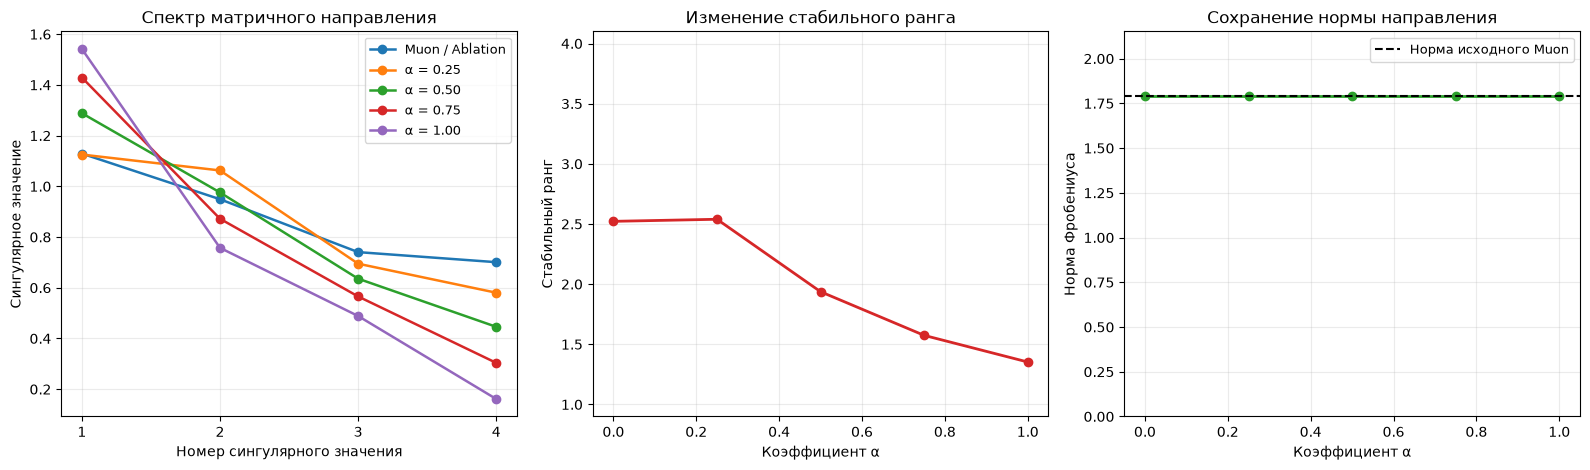


Проверка полных обновлений оптимизаторов:


Seed,Контрольных шагов,Ошибка Muon,Ошибка AdamW,Ошибка состояния,Ошибка Ablation,Ошибка нормы Blend-Muon,"Память состояния, байт"
1,30,5.55111512e-16,3.46944695e-18,6.93889390e-18,0.00000000e+00,7.63278329e-17,656
2,30,5.55111512e-16,8.67361738e-19,6.93889390e-18,0.00000000e+00,4.85722573e-17,656
3,30,7.21644966e-16,4.33680869e-19,6.93889390e-18,0.00000000e+00,7.63278329e-17,656
4,30,7.21644966e-16,1.73472348e-18,6.93889390e-18,0.00000000e+00,6.93889390e-17,656
5,30,3.60822483e-16,8.67361738e-19,6.93889390e-18,0.00000000e+00,6.24500451e-17,656



Вычислительная стоимость одного обновления:


Метод,Alpha,Вызовы дуализации,Итерации NS,Матричные умножения,Нормы NS,Смешивания,Дополнительные нормы,Масштабирования матриц,Сложения матриц,Резервные переходы,"Память состояния, байт"
Muon,0.000000,1,5,15,1,0,0,0,0,0,656
Blend-Muon,0.500000,1,5,15,1,1,3,4,1,0,656
Ablation,0.000000,1,5,15,1,0,0,0,0,0,656



Максимальная ошибка матричной дуализации:
5.55111512e-15

Максимальная ошибка обновлений Muon:
7.21644966e-16

Максимальная ошибка AdamW:
3.46944695e-18

Максимальная ошибка сохранения нормы:
7.63278329e-17

Все контрольные проверки пройдены.
Muon проверен независимой спектральной формулой.
AdamW проверен относительно torch.optim.AdamW.
Muon и Ablation полностью совпадают.
Blend-Muon сохраняет норму матричного обновления.
Дополнительное постоянное состояние отсутствует.
SVD используется только для контрольных проверок.
Основное обучение ещё не проводилось.
Тестовая выборка для оценки моделей не использовалась.


In [5]:
# =============================================
# Счётчики операций оптимизатора
# =============================================

def initialize_optimizer_counters():

    return {
        "ns_calls": 0,
        "ns_iterations": 0,
        "ns_matmuls": 0,
        "ns_norm_calls": 0,
        "blend_calls": 0,
        "blend_norm_calls": 0,
        "blend_matrix_scales": 0,
        "blend_matrix_additions": 0,
        "blend_fallbacks": 0
    }


# =============================================
# Матричная дуализация Muon
# =============================================

@torch.no_grad()
def newton_schulz_direction(
    matrix,
    settings,
    counters=None
):

    assert matrix.ndim == 2

    assert matrix.dtype == torch.float64

    if counters is None:

        counters = initialize_optimizer_counters()

    a = settings["ns_a"]
    b = settings["ns_b"]
    c = settings["ns_c"]

    eps = settings["ns_eps"]

    n_steps = settings["ns_steps"]

    counters["ns_calls"] += 1

    # Используем меньшую размерность
    # для промежуточных квадратных матриц
    transposed = (
        matrix.shape[0] > matrix.shape[1]
    )

    X_ns = (
        matrix.T
        if transposed
        else matrix
    )

    # Нормализация по норме Фробениуса
    X_ns = X_ns / (
        torch.linalg.matrix_norm(X_ns) + eps
    )

    counters["ns_norm_calls"] += 1

    # Полиномиальные итерации Ньютона — Шульца
    for _ in range(n_steps):

        A = X_ns @ X_ns.T

        A_squared = A @ A

        B = b * A + c * A_squared

        X_ns = a * X_ns + B @ X_ns

        counters["ns_iterations"] += 1

        counters["ns_matmuls"] += 3

    return (
        X_ns.T
        if transposed
        else X_ns
    )


# =============================================
# Собственная модификация Blend-Muon
# =============================================

@torch.no_grad()
def blend_direction(
    M,
    Q,
    alpha,
    counters=None
):

    if not 0 <= alpha <= 1:

        raise ValueError(
            "Коэффициент alpha должен быть в [0, 1]."
        )

    assert M.shape == Q.shape

    if counters is None:

        counters = initialize_optimizer_counters()

    # Ablation: отключение нового компонента
    if alpha == 0:

        return Q, "Disabled"

    counters["blend_calls"] += 1

    # Нормы исходного и дуализированного направлений
    norm_M = torch.linalg.matrix_norm(M)

    norm_Q = torch.linalg.matrix_norm(Q)

    counters["blend_norm_calls"] += 2

    # Проверка численной корректности
    if not (
        torch.isfinite(norm_M).item()
        and torch.isfinite(norm_Q).item()
    ):

        return (
            torch.full_like(Q, float("nan")),
            "Non-finite norm"
        )

    # Обработка нулевых направлений
    if norm_M.item() == 0:

        return torch.zeros_like(Q), "Zero input"

    if norm_Q.item() == 0:

        return torch.zeros_like(Q), "Zero dual direction"

    # Приведение исходного направления
    # к норме дуализированной матрицы
    R = (norm_Q / norm_M) * M

    counters["blend_matrix_scales"] += 1

    # Смешивание направлений
    H = (1 - alpha) * Q + alpha * R

    counters["blend_matrix_scales"] += 2

    counters["blend_matrix_additions"] += 1

    # Восстановление исходной нормы обновления
    norm_H = torch.linalg.matrix_norm(H)

    counters["blend_norm_calls"] += 1

    if not torch.isfinite(norm_H).item():

        return (
            torch.full_like(Q, float("nan")),
            "Non-finite blend norm"
        )

    if norm_H.item() == 0:

        counters["blend_fallbacks"] += 1

        return Q, "Zero blend fallback"

    Q_blend = (norm_Q / norm_H) * H

    counters["blend_matrix_scales"] += 1

    return Q_blend, "Applied"


# =============================================
# Инициализация состояния оптимизатора
# =============================================

def initialize_optimizer_state(theta):

    W1, _, _, _ = unpack_parameters(theta)

    auxiliary_parameters = theta[adamw_slice]

    return {
        "momentum_buffer": torch.zeros_like(W1),

        "m": torch.zeros_like(auxiliary_parameters),

        "v": torch.zeros_like(auxiliary_parameters),

        "step": 0
    }


def copy_optimizer_state(state):

    return {
        key: (
            value.detach().clone()
            if isinstance(value, torch.Tensor)
            else value
        )
        for key, value in state.items()
    }


def optimizer_state_bytes(state):

    return sum(
        value.numel() * value.element_size()

        for value in state.values()

        if isinstance(value, torch.Tensor)
    )


def is_finite_state(state):

    return all(
        torch.isfinite(value).all().item()

        for value in state.values()

        if isinstance(value, torch.Tensor)
    )


# =============================================
# Обновление вспомогательных параметров AdamW
# =============================================

@torch.no_grad()
def auxiliary_adamw_step(
    parameters,
    gradient,
    m_previous,
    v_previous,
    step,
    settings
):

    eta = settings["eta"]

    beta1 = settings["beta1"]

    beta2 = settings["beta2"]

    eps = settings["eps"]

    weight_decay = settings["weight_decay"]

    # Накопленные моменты
    m = torch.lerp(
        m_previous,
        gradient,
        1 - beta1
    )

    v = torch.lerp(
        v_previous,
        gradient.square(),
        1 - beta2
    )

    # Коррекция начального смещения
    m_hat = m / (1 - beta1 ** step)

    v_hat = v / (1 - beta2 ** step)

    update = (
        -eta * m_hat
        / (torch.sqrt(v_hat) + eps)
    )

    parameters_new = (
        (1 - eta * weight_decay)
        * parameters
        + update
    )

    return parameters_new, m, v


# =============================================
# Общий шаг оптимизации
# Muon / Blend-Muon / Ablation
# =============================================

@torch.no_grad()
def optimizer_step(
    method,
    theta,
    gradient,
    state,
    alpha=0.0,
    collect_diagnostics=True
):

    if method not in methods:

        raise ValueError(
            f"Неизвестный метод: {method}"
        )

    if method in ("Muon", "Ablation") and alpha != 0:

        raise ValueError(
            "Для Muon и Ablation alpha должен быть равен 0."
        )

    if method == "Blend-Muon" and not 0 < alpha <= 1:

        raise ValueError(
            "Для Blend-Muon необходимо 0 < alpha <= 1."
        )

    assert theta.shape == gradient.shape

    assert theta.numel() == n_parameters

    assert theta.dtype == torch.float64

    assert gradient.dtype == torch.float64

    counters = initialize_optimizer_counters()

    step = state["step"] + 1

    W1, _, _, _ = unpack_parameters(theta)

    G = gradient[muon_slice].reshape(
        hidden_size,
        input_size
    )

    mu = muon_config["momentum"]

    eta_muon = muon_config["eta"]

    weight_decay = muon_config["weight_decay"]

    # =========================================
    # Накопление импульса
    # =========================================

    momentum_buffer = torch.lerp(
        state["momentum_buffer"],
        G,
        1 - mu
    )

    # Направление Нестерова
    if muon_config["nesterov"]:

        M = torch.lerp(
            G,
            momentum_buffer,
            mu
        )

    else:

        M = momentum_buffer

    # =========================================
    # Исходная матричная дуализация
    # =========================================

    Q = newton_schulz_direction(
        M,
        muon_config,
        counters
    )

    # =========================================
    # Выбор итогового матричного направления
    # =========================================

    if method == "Muon":

        direction = Q

        blend_status = "Original Muon"

    else:

        # Blend-Muon и Ablation используют
        # одну реализацию нового механизма
        direction, blend_status = blend_direction(
            M,
            Q,
            alpha,
            counters
        )

    # =========================================
    # Обновление матрицы W1
    # =========================================

    W1_update = (
        -eta_muon
        * shape_scale
        * direction
    )

    W1_new = (
        (1 - eta_muon * weight_decay)
        * W1
        + W1_update
    )

    # =========================================
    # Обновление остальных параметров
    # =========================================

    auxiliary_new, m, v = auxiliary_adamw_step(
        parameters=theta[adamw_slice],

        gradient=gradient[adamw_slice],

        m_previous=state["m"],

        v_previous=state["v"],

        step=step,

        settings=adamw_config
    )

    # Объединение параметров
    theta_new = torch.cat([
        W1_new.reshape(-1),
        auxiliary_new
    ])

    state_new = {
        "momentum_buffer": momentum_buffer,
        "m": m,
        "v": v,
        "step": step
    }

    diagnostics = {
        "operation_counts": counters,

        "blend_status": blend_status
    }

    # Диагностика выполняется отдельно
    # от основных вычислений оптимизатора
    if collect_diagnostics:

        norm_M = torch.linalg.matrix_norm(
            M
        ).item()

        norm_Q = torch.linalg.matrix_norm(
            Q
        ).item()

        norm_direction = torch.linalg.matrix_norm(
            direction
        ).item()

        diagnostics.update({
            "momentum_direction": M.clone(),

            "dual_direction": Q.clone(),

            "used_direction": direction.clone(),

            "momentum_norm": (
                torch.linalg.matrix_norm(
                    momentum_buffer
                ).item()
            ),

            "matrix_direction_norm": norm_M,

            "dual_direction_norm": norm_Q,

            "used_direction_norm": norm_direction,

            "direction_norm_error": abs(
                norm_direction - norm_Q
            ),

            "direction_cosine": matrix_cosine(
                Q, direction
            ),

            "matrix_update_norm": (
                torch.linalg.matrix_norm(
                    W1_new - W1
                ).item()
            ),

            "auxiliary_update_norm": (
                torch.linalg.vector_norm(
                    auxiliary_new - theta[adamw_slice]
                ).item()
            ),

            "total_update_norm": (
                torch.linalg.vector_norm(
                    theta_new - theta
                ).item()
            )
        })

    return theta_new, state_new, diagnostics


# =============================================
# Независимая проверка матричной дуализации
# через сингулярное разложение
# =============================================

def spectral_reference_direction(matrix):

    matrix_np = (
        matrix.detach()
        .cpu()
        .numpy()
    )

    U, singular_values, Vt = np.linalg.svd(
        matrix_np,
        full_matrices=False
    )

    # Независимое применение полинома
    # к сингулярным значениям
    values = singular_values / (
        np.linalg.norm(matrix_np, ord="fro")
        + muon_config["ns_eps"]
    )

    a = muon_config["ns_a"]

    b = muon_config["ns_b"]

    c = muon_config["ns_c"]

    for _ in range(muon_config["ns_steps"]):

        values = (
            a * values
            + b * values ** 3
            + c * values ** 5
        )

    reference = (U * values) @ Vt

    return torch.tensor(
        reference,
        dtype=torch.float64,
        device=device
    )


# =============================================
# Контрольные матрицы
# =============================================

control_rng = np.random.default_rng(2026)

random_tall = torch.tensor(
    control_rng.normal(size=(10, 4)),
    dtype=torch.float64
)

random_wide = torch.tensor(
    control_rng.normal(size=(4, 10)),
    dtype=torch.float64
)

rank_one = torch.outer(
    torch.arange(1, 11, dtype=torch.float64),

    torch.tensor(
        [1.0, -2.0, 0.5, 0.1]
    )
)

ill_conditioned = torch.zeros(
    (10, 4),
    dtype=torch.float64
)

ill_conditioned[:4, :] = torch.diag(
    torch.tensor([
        1.0,
        1e-2,
        1e-4,
        1e-8
    ])
)

zero_matrix = torch.zeros(
    (10, 4),
    dtype=torch.float64
)

identity_like = torch.eye(
    10, 4,
    dtype=torch.float64
)

control_matrices = {
    "Случайная 10×4": random_tall,

    "Случайная 4×10": random_wide,

    "Ранг 1": rank_one,

    "Плохо обусловленная": ill_conditioned,

    "Нулевая": zero_matrix,

    "Полуортогональная": identity_like
}


# =============================================
# Проверка итераций Ньютона — Шульца
# =============================================

ns_check_records = []

for name, matrix in control_matrices.items():

    counters = initialize_optimizer_counters()

    Q = newton_schulz_direction(
        matrix,
        muon_config,
        counters
    )

    reference = spectral_reference_direction(
        matrix
    )

    error = torch.max(
        torch.abs(Q - reference)
    ).item()

    assert Q.shape == matrix.shape

    assert torch.isfinite(Q).all()

    assert error < 1e-10

    assert counters["ns_calls"] == 1

    assert counters["ns_iterations"] == 5

    assert counters["ns_matmuls"] == 15

    assert counters["ns_norm_calls"] == 1

    ns_check_records.append({
        "Матрица": name,

        "Размерность": (
            f"{matrix.shape[0]}×{matrix.shape[1]}"
        ),

        "Норма входа": (
            torch.linalg.matrix_norm(
                matrix
            ).item()
        ),

        "Норма результата": (
            torch.linalg.matrix_norm(
                Q
            ).item()
        ),

        "Стабильный ранг входа": stable_rank(
            matrix
        ),

        "Стабильный ранг результата": stable_rank(
            Q
        ),

        "Ошибка относительно спектральной формулы": (
            error
        ),

        "Итераций NS": counters["ns_iterations"],

        "Матричных умножений": counters["ns_matmuls"]
    })


ns_check_df = pd.DataFrame(ns_check_records)

print("Проверка матричной дуализации Muon:")

display(
    ns_check_df.style
    .hide(axis="index")
    .format({
        "Норма входа": "{:.8f}",

        "Норма результата": "{:.8f}",

        "Стабильный ранг входа": "{:.8f}",

        "Стабильный ранг результата": "{:.8f}",

        "Ошибка относительно спектральной формулы":
            "{:.8e}"
    })
)


# =============================================
# Проверка свойств Blend-Muon
# =============================================

blend_check_records = []

control_alphas = [0.0] + alpha_grid + [1.0]

for name, matrix in control_matrices.items():

    Q = newton_schulz_direction(
        matrix,
        muon_config
    )

    norm_Q = torch.linalg.matrix_norm(
        Q
    ).item()

    for alpha in control_alphas:

        counters = initialize_optimizer_counters()

        Q_blend, status = blend_direction(
            matrix,
            Q,
            alpha,
            counters
        )

        norm_blend = torch.linalg.matrix_norm(
            Q_blend
        ).item()

        norm_error = abs(
            norm_blend - norm_Q
        )

        assert Q_blend.shape == Q.shape

        assert torch.isfinite(Q_blend).all()

        assert norm_error < 1e-10

        if alpha == 0:

            # Полное совпадение с исходным Muon
            assert torch.equal(Q_blend, Q)

            assert counters["blend_calls"] == 0

            assert counters["blend_norm_calls"] == 0

        elif status == "Applied":

            assert counters["blend_calls"] == 1

            assert counters["blend_norm_calls"] == 3

            assert counters["blend_matrix_scales"] == 4

            assert counters["blend_matrix_additions"] == 1

        if alpha == 1 and norm_Q > 0:

            expected = (
                matrix
                * norm_Q
                / torch.linalg.matrix_norm(matrix)
            )

            assert torch.allclose(
                Q_blend,
                expected,
                atol=1e-12,
                rtol=1e-10
            )

        blend_check_records.append({
            "Матрица": name,

            "Alpha": alpha,

            "Норма Muon": norm_Q,

            "Норма Blend-Muon": norm_blend,

            "Ошибка сохранения нормы": norm_error,

            "Косинус с Muon": matrix_cosine(
                Q, Q_blend
            ),

            "Косинус с исходным направлением": (
                matrix_cosine(matrix, Q_blend)
            ),

            "Стабильный ранг": stable_rank(
                Q_blend
            ),

            "Статус": status
        })


blend_check_df = pd.DataFrame(
    blend_check_records
)

print("\nПроверка свойств модификации:")

display(
    blend_check_df.style
    .hide(axis="index")
    .format({
        "Alpha": "{:.2f}",

        "Норма Muon": "{:.8f}",

        "Норма Blend-Muon": "{:.8f}",

        "Ошибка сохранения нормы": "{:.8e}",

        "Косинус с Muon": "{:.8f}",

        "Косинус с исходным направлением": "{:.8f}",

        "Стабильный ранг": "{:.8f}"
    }, na_rep="—")
)


# =============================================
# Проверка исключительных ситуаций
# =============================================

# Нулевое направление
Q_zero = newton_schulz_direction(
    zero_matrix,
    muon_config
)

assert torch.equal(Q_zero, zero_matrix)

zero_result, zero_status = blend_direction(
    zero_matrix,
    Q_zero,
    alpha=0.5
)

assert torch.equal(
    zero_result,
    zero_matrix
)

assert zero_status == "Zero input"

# Искусственная проверка взаимного уничтожения
# направлений при смешивании
fallback_counters = initialize_optimizer_counters()

fallback_result, fallback_status = blend_direction(
    identity_like,
    -identity_like,
    alpha=0.5,
    counters=fallback_counters
)

assert fallback_status == "Zero blend fallback"

assert fallback_counters["blend_fallbacks"] == 1

assert torch.equal(
    fallback_result,
    -identity_like
)

# Проверка нечислового направления
nonfinite_matrix = identity_like.clone()

nonfinite_matrix[0, 0] = float("nan")

nonfinite_result, nonfinite_status = blend_direction(
    nonfinite_matrix,
    identity_like,
    alpha=0.5
)

assert not torch.isfinite(
    nonfinite_result
).all()

assert nonfinite_status == "Non-finite norm"

print("\nПроверки исключительных ситуаций пройдены.")


# =============================================
# Визуализация изменения спектра
# =============================================
# Используется один градиент W1
# из первого мини-батча первого повтора.

_, sample_gradient = evaluate_loss_gradient(
    initial_parameters[1],

    X_train[
        batch_schedules[1][0]["indices"]
    ],

    y_train[
        batch_schedules[1][0]["indices"]
    ]
)

sample_G = sample_gradient[
    muon_slice
].reshape(hidden_size, input_size)

mu = muon_config["momentum"]

# Начальное состояние импульса равно нулю
sample_buffer = (1 - mu) * sample_G

sample_M = (
    (1 - mu) * sample_G
    + mu * sample_buffer
)

sample_Q = newton_schulz_direction(
    sample_M,
    muon_config
)

spectral_comparison_records = []

spectral_plot_data = {}

for alpha in control_alphas:

    direction, _ = blend_direction(
        sample_M,
        sample_Q,
        alpha
    )

    singular_values = (
        torch.linalg.svdvals(direction)
        .numpy()
    )

    spectral_plot_data[alpha] = (
        singular_values
    )

    spectral_comparison_records.append({
        "Alpha": alpha,

        "Норма Фробениуса": (
            torch.linalg.matrix_norm(
                direction
            ).item()
        ),

        "Стабильный ранг": stable_rank(
            direction
        ),

        "Косинус с исходным направлением": (
            matrix_cosine(sample_M, direction)
        ),

        "Максимальное сингулярное значение": (
            singular_values.max()
        ),

        "Минимальное сингулярное значение": (
            singular_values.min()
        )
    })


spectral_comparison_df = pd.DataFrame(
    spectral_comparison_records
)

print("\nИзменение спектра одного матричного направления:")

display(
    spectral_comparison_df.style
    .hide(axis="index")
    .format(precision=8)
)


fig, axes = plt.subplots(
    1, 3,
    figsize=(16, 4.8)
)

# Сингулярные значения
for alpha in control_alphas:

    label = (
        "Muon / Ablation"
        if alpha == 0
        else f"α = {alpha:.2f}"
    )

    axes[0].plot(
        np.arange(1, input_size + 1),

        spectral_plot_data[alpha],

        marker="o",

        linewidth=1.8,

        label=label
    )

axes[0].set_title(
    "Спектр матричного направления"
)

axes[0].set_xlabel(
    "Номер сингулярного значения"
)

axes[0].set_ylabel(
    "Сингулярное значение"
)

axes[0].set_xticks(
    np.arange(1, input_size + 1)
)

axes[0].legend(fontsize=9)


# Стабильный ранг
axes[1].plot(
    spectral_comparison_df["Alpha"],

    spectral_comparison_df["Стабильный ранг"],

    marker="o",

    linewidth=2,

    color="#d62728"
)

axes[1].set_title(
    "Изменение стабильного ранга"
)

axes[1].set_xlabel("Коэффициент α")

axes[1].set_ylabel("Стабильный ранг")

axes[1].set_ylim(0.9, input_size + 0.1)


# Сохранение нормы
axes[2].plot(
    spectral_comparison_df["Alpha"],

    spectral_comparison_df["Норма Фробениуса"],

    marker="o",

    linewidth=2,

    color="#2ca02c"
)

reference_norm = torch.linalg.matrix_norm(
    sample_Q
).item()

axes[2].axhline(
    reference_norm,

    color="black",

    linestyle="--",

    label="Норма исходного Muon"
)

axes[2].set_title(
    "Сохранение нормы направления"
)

axes[2].set_xlabel("Коэффициент α")

axes[2].set_ylabel("Норма Фробениуса")

axes[2].set_ylim(
    0,
    reference_norm * 1.2
)

axes[2].legend(fontsize=9)

for ax in axes:

    ax.grid(alpha=0.25)

plt.tight_layout()
plt.show()


# =============================================
# Независимая проверка полных обновлений
# =============================================
# Используем одинаковую последовательность
# заранее вычисленных градиентов.
# Основное обучение ещё не проводится.

control_steps = 30

optimizer_check_records = []

for network_seed in network_seeds:

    theta_initial = initial_parameters[
        network_seed
    ]

    theta_muon = theta_initial.clone()

    theta_ablation = theta_initial.clone()

    state_muon = initialize_optimizer_state(
        theta_initial
    )

    state_ablation = initialize_optimizer_state(
        theta_initial
    )

    # Независимая реализация матричного блока
    reference_W1 = (
        theta_initial[muon_slice]
        .reshape(hidden_size, input_size)
        .numpy()
        .copy()
    )

    reference_buffer = np.zeros_like(
        reference_W1
    )

    # Библиотечный AdamW для проверки
    # вспомогательных параметров
    reference_aux = nn.Parameter(
        theta_initial[adamw_slice].clone()
    )

    reference_adamw = torch.optim.AdamW(
        [reference_aux],

        lr=adamw_config["eta"],

        betas=(
            adamw_config["beta1"],
            adamw_config["beta2"]
        ),

        eps=adamw_config["eps"],

        weight_decay=adamw_config["weight_decay"],

        foreach=False,

        fused=False
    )

    max_muon_error = 0.0

    max_adamw_error = 0.0

    max_ablation_error = 0.0

    max_state_error = 0.0

    max_blend_norm_error = 0.0

    for batch_record in batch_schedules[
        network_seed
    ][:control_steps]:

        # Один и тот же градиент для всех проверок
        _, gradient = evaluate_loss_gradient(
            theta_initial,

            X_train[batch_record["indices"]],

            y_train[batch_record["indices"]]
        )

        # Сохраняем состояние до обновления
        theta_previous = theta_muon.clone()

        state_previous = copy_optimizer_state(
            state_muon
        )

        # =====================================
        # Собственная реализация Muon
        # =====================================

        theta_muon, state_muon, diag_muon = (
            optimizer_step(
                "Muon",

                theta_muon,

                gradient,

                state_muon
            )
        )

        # =====================================
        # Ablation
        # =====================================

        theta_ablation, state_ablation, diag_ablation = (
            optimizer_step(
                "Ablation",

                theta_ablation,

                gradient,

                state_ablation,

                alpha=0.0
            )
        )

        assert torch.equal(
            theta_muon,
            theta_ablation
        )

        assert (
            diag_muon["operation_counts"]
            == diag_ablation["operation_counts"]
        )

        for key in state_muon:

            if isinstance(
                state_muon[key],
                torch.Tensor
            ):

                assert torch.equal(
                    state_muon[key],
                    state_ablation[key]
                )

            else:

                assert (
                    state_muon[key]
                    == state_ablation[key]
                )

        # =====================================
        # Независимый расчёт Muon через спектр
        # =====================================

        G_np = (
            gradient[muon_slice]
            .reshape(hidden_size, input_size)
            .numpy()
        )

        reference_buffer = (
            mu * reference_buffer
            + (1 - mu) * G_np
        )

        reference_M = (
            (1 - mu) * G_np
            + mu * reference_buffer
        )

        reference_Q = spectral_reference_direction(
            torch.tensor(
                reference_M,
                dtype=torch.float64
            )
        ).numpy()

        reference_W1 = (
            (1 - muon_config["eta"]
             * muon_config["weight_decay"])
            * reference_W1

            - muon_config["eta"]
            * shape_scale
            * reference_Q
        )

        W1_actual = (
            theta_muon[muon_slice]
            .reshape(hidden_size, input_size)
            .numpy()
        )

        muon_error = np.max(
            np.abs(
                W1_actual - reference_W1
            )
        )

        assert muon_error < 1e-10

        # =====================================
        # Проверка AdamW
        # =====================================

        reference_aux.grad = (
            gradient[adamw_slice].clone()
        )

        reference_adamw.step()

        reference_adamw.zero_grad(
            set_to_none=True
        )

        adamw_error = torch.max(
            torch.abs(
                theta_muon[adamw_slice]
                - reference_aux.detach()
            )
        ).item()

        assert adamw_error < 1e-10

        # Проверка накопленных моментов
        adamw_reference_state = (
            reference_adamw.state[reference_aux]
        )

        state_error = max(
            np.max(
                np.abs(
                    state_muon["momentum_buffer"].numpy()
                    - reference_buffer
                )
            ),

            torch.max(
                torch.abs(
                    state_muon["m"]
                    - adamw_reference_state["exp_avg"]
                )
            ).item(),

            torch.max(
                torch.abs(
                    state_muon["v"]
                    - adamw_reference_state["exp_avg_sq"]
                )
            ).item()
        )

        assert state_error < 1e-10

        # =====================================
        # Проверка Blend-Muon при общем входе
        # =====================================

        for alpha in alpha_grid:

            theta_blend, state_blend, diag_blend = (
                optimizer_step(
                    "Blend-Muon",

                    theta_previous,

                    gradient,

                    state_previous,

                    alpha=alpha
                )
            )

            assert torch.isfinite(
                theta_blend
            ).all()

            assert is_finite_state(
                state_blend
            )

            # При общем входе состояния
            # накопленных моментов совпадают
            for key in [
                "momentum_buffer",
                "m",
                "v"
            ]:

                assert torch.equal(
                    state_muon[key],
                    state_blend[key]
                )

            # Вспомогательные параметры
            # не зависят от смешивания
            assert torch.equal(
                theta_muon[adamw_slice],

                theta_blend[adamw_slice]
            )

            # Проверка нормы обновления W1
            norm_error = abs(
                diag_muon["matrix_update_norm"]
                - diag_blend["matrix_update_norm"]
            )

            assert norm_error < 1e-10

            # Проверка общего численного состояния
            assert (
                optimizer_state_bytes(state_blend)
                == expected_state_bytes
            )

            # Проверка дополнительных операций
            assert (
                diag_blend["operation_counts"]["ns_matmuls"]
                == 15
            )

            assert (
                diag_blend["operation_counts"]["blend_norm_calls"]
                == 3
            )

            max_blend_norm_error = max(
                max_blend_norm_error,
                norm_error
            )

        max_muon_error = max(
            max_muon_error,
            muon_error
        )

        max_adamw_error = max(
            max_adamw_error,
            adamw_error
        )

        max_state_error = max(
            max_state_error,
            state_error
        )

        max_ablation_error = max(
            max_ablation_error,

            torch.max(
                torch.abs(
                    theta_muon - theta_ablation
                )
            ).item()
        )

    assert state_muon["step"] == control_steps

    assert state_ablation["step"] == control_steps

    assert (
        optimizer_state_bytes(state_muon)
        == expected_state_bytes
    )

    assert (
        optimizer_state_bytes(state_ablation)
        == expected_state_bytes
    )

    optimizer_check_records.append({
        "Seed": network_seed,

        "Контрольных шагов": control_steps,

        "Ошибка Muon": max_muon_error,

        "Ошибка AdamW": max_adamw_error,

        "Ошибка состояния": max_state_error,

        "Ошибка Ablation": max_ablation_error,

        "Ошибка нормы Blend-Muon": (
            max_blend_norm_error
        ),

        "Память состояния, байт": (
            optimizer_state_bytes(state_muon)
        )
    })


optimizer_check_df = pd.DataFrame(
    optimizer_check_records
)

print("\nПроверка полных обновлений оптимизаторов:")

display(
    optimizer_check_df.style
    .hide(axis="index")
    .format({
        "Ошибка Muon": "{:.8e}",

        "Ошибка AdamW": "{:.8e}",

        "Ошибка состояния": "{:.8e}",

        "Ошибка Ablation": "{:.8e}",

        "Ошибка нормы Blend-Muon": "{:.8e}"
    })
)


# =============================================
# Стоимость одного обновления
# =============================================

operation_cost_records = []

for method in methods:

    alpha = (
        0.5 if method == "Blend-Muon" else 0.0
    )

    theta = initial_parameters[1].clone()

    state = initialize_optimizer_state(theta)

    _, _, diagnostics = optimizer_step(
        method,

        theta,

        sample_gradient,

        state,

        alpha=alpha
    )

    operation_cost_records.append({
        "Метод": method,

        "Alpha": alpha,

        **diagnostics["operation_counts"],

        "Память состояния, байт": (
            optimizer_state_bytes(state)
        )
    })


operation_cost_df = pd.DataFrame(
    operation_cost_records
)

print("\nВычислительная стоимость одного обновления:")

display(
    operation_cost_df.rename(columns={
        "ns_calls": "Вызовы дуализации",

        "ns_iterations": "Итерации NS",

        "ns_matmuls": "Матричные умножения",

        "ns_norm_calls": "Нормы NS",

        "blend_calls": "Смешивания",

        "blend_norm_calls": "Дополнительные нормы",

        "blend_matrix_scales": "Масштабирования матриц",

        "blend_matrix_additions": "Сложения матриц",

        "blend_fallbacks": "Резервные переходы"
    })
    .style.hide(axis="index")
)


# =============================================
# Итоговые проверки
# =============================================

assert len(ns_check_df) == 6

assert len(blend_check_df) == 30

assert len(optimizer_check_df) == 5

assert (
    optimizer_check_df["Ошибка Ablation"] == 0
).all()

print("\nМаксимальная ошибка матричной дуализации:")

print(
    f"{ns_check_df['Ошибка относительно спектральной формулы'].max():.8e}"
)

print("\nМаксимальная ошибка обновлений Muon:")

print(
    f"{optimizer_check_df['Ошибка Muon'].max():.8e}"
)

print("\nМаксимальная ошибка AdamW:")

print(
    f"{optimizer_check_df['Ошибка AdamW'].max():.8e}"
)

print("\nМаксимальная ошибка сохранения нормы:")

print(
    f"{optimizer_check_df['Ошибка нормы Blend-Muon'].max():.8e}"
)

print("\nВсе контрольные проверки пройдены.")

print("Muon проверен независимой спектральной формулой.")

print("AdamW проверен относительно torch.optim.AdamW.")

print("Muon и Ablation полностью совпадают.")

print("Blend-Muon сохраняет норму матричного обновления.")

print("Дополнительное постоянное состояние отсутствует.")

print("SVD используется только для контрольных проверок.")

print("Основное обучение ещё не проводилось.")

print("Тестовая выборка для оценки моделей не использовалась.")

Результаты контрольного обучения:


Метод,Alpha,Начальный train loss,Конечный train loss,Начальный validation loss,Конечный validation loss,Конечная норма градиента,Минимальный validation loss,Лучшая итерация,Принято шагов,Отклонено шагов,Основные обратные проходы,Диагностические обратные проходы,Итерации NS,Матричные умножения NS,Дополнительные нормы,"Память состояния, байт"
Muon,0.00,0.73618835,0.69293301,0.74713834,0.69777313,9.32438999e-02,0.69777313,20,20,0,20,21,100,300,0,656
Blend-Muon,0.50,0.73618835,0.68235069,0.74713834,0.68351331,8.15737330e-02,0.68351331,20,20,0,20,21,100,300,60,656
Ablation,0.00,0.73618835,0.69293301,0.74713834,0.69777313,9.32438999e-02,0.69777313,20,20,0,20,21,100,300,0,656



Максимальное различие Muon и Ablation:
0.00000000e+00

Различие первого обновления Muon и Blend-Muon:
1.46476771e-02

Переход между первой и второй эпохами:


Метод,Шаг,Эпоха,Размер батча,Шаг состояния,Норма импульса,Норма исходной дуализации,Норма используемого направления,Норма обновления W1,Train loss,Validation loss
Muon,16,1,32,16,0.03663161,1.62561496,1.62561496,0.05140646,0.69944233,0.70601507
Muon,17,1,32,17,0.03973426,1.62201108,1.62201108,0.05129249,0.69766941,0.70388547
Muon,18,1,16,18,0.04217215,1.59889045,1.59889045,0.05056136,0.69612860,0.70182605
Muon,19,2,32,19,0.04337702,1.71628357,1.71628357,0.05427365,0.69455058,0.69978352
Muon,20,2,32,20,0.04601099,1.73653393,1.73653393,0.05491402,0.69293301,0.69777313
Blend-Muon,16,1,32,16,0.03396807,1.71178280,1.71178280,0.05413132,0.69030224,0.69474275
Blend-Muon,17,1,32,17,0.03587077,1.95748203,1.95748203,0.06190102,0.68792431,0.69168118
Blend-Muon,18,1,16,18,0.03681480,1.73244921,1.73244921,0.05478485,0.68591571,0.68883514
Blend-Muon,19,2,32,19,0.03644029,1.68709974,1.68709974,0.05335078,0.68415205,0.68610613
Blend-Muon,20,2,32,20,0.03846076,1.75194288,1.75194288,0.05540130,0.68235069,0.68351331


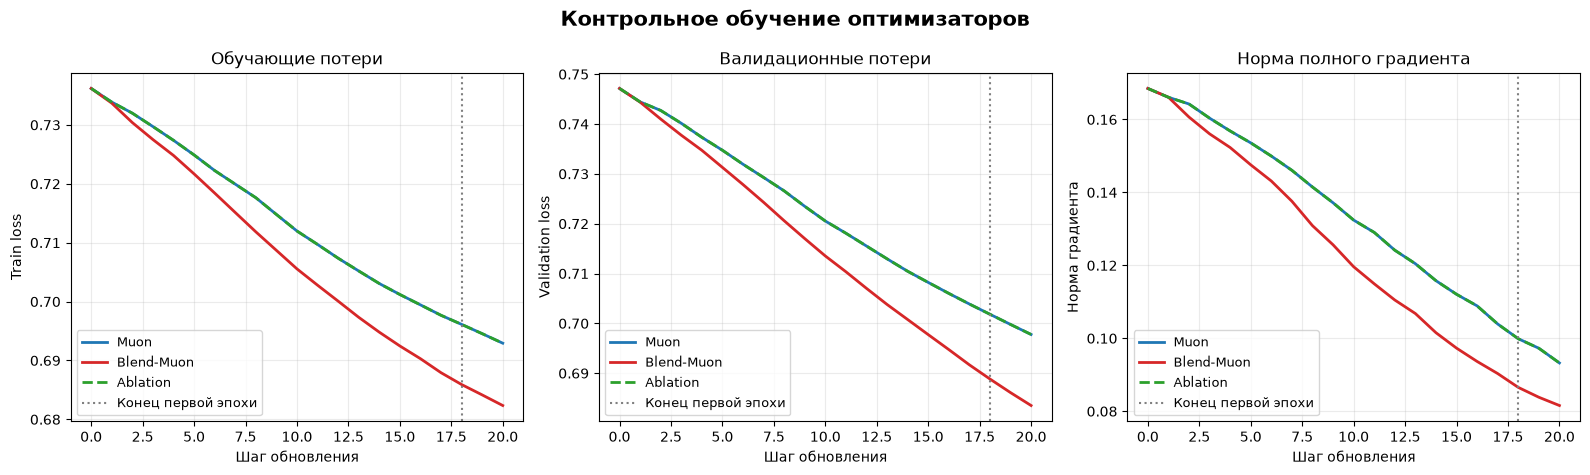


Все проверки контрольного обучения пройдены.
Muon и Ablation имеют идентичные траектории.
Blend-Muon изменяет матричное направление.
Норма обновления при общем входе сохраняется.
Накопление импульса между эпохами не сбрасывается.
Вычислительные счётчики работают корректно.
Операции вычисления кривизны отсутствуют.
Сингулярные разложения при обучении не используются.
Коэффициент alpha = 0.5 использован только для проверки.
Подбор коэффициента смешивания ещё не проводился.
Тестовая выборка для оценки моделей не использовалась.


In [6]:
# =============================================
# Вычислительные счётчики
# =============================================

def initialize_counters():

    return {
        "batch_loss_calls": 0,
        "batch_gradient_calls": 0,
        "full_train_loss_calls": 0,
        "full_gradient_calls": 0,
        "validation_loss_calls": 0,

        "processed_samples": 0,
        "diagnostic_train_samples": 0,
        "diagnostic_validation_samples": 0,

        "optimizer_step_calls": 0,

        "hessian_calls": 0,
        "jacobian_calls": 0,
        "curvature_builds": 0,
        "factorizations": 0,
        "linear_system_solves": 0,
        "svd_calls": 0,

        **initialize_optimizer_counters()
    }


# =============================================
# Вычисление стохастического градиента
# =============================================

def counted_batch_gradient(theta, batch_indices, counters):

    X_batch = X_train[batch_indices]
    y_batch = y_train[batch_indices]

    loss, gradient = evaluate_loss_gradient(
        theta,
        X_batch,
        y_batch
    )

    counters["batch_loss_calls"] += 1
    counters["batch_gradient_calls"] += 1

    counters["processed_samples"] += len(batch_indices)

    return loss, gradient


# =============================================
# Диагностические вычисления
# =============================================

def evaluate_diagnostics(theta, counters):

    train_loss, full_gradient = evaluate_loss_gradient(
        theta,
        X_train,
        y_train
    )

    counters["full_train_loss_calls"] += 1
    counters["full_gradient_calls"] += 1

    counters["diagnostic_train_samples"] += len(X_train)

    validation_loss = evaluate_loss(
        theta,
        X_val,
        y_val
    )

    counters["validation_loss_calls"] += 1

    counters["diagnostic_validation_samples"] += len(X_val)

    gradient_norm = torch.linalg.vector_norm(
        full_gradient
    ).item()

    matrix_gradient_norm = torch.linalg.matrix_norm(
        full_gradient[muon_slice].reshape(
            hidden_size,
            input_size
        )
    ).item()

    return {
        "train_loss": train_loss,

        "validation_loss": validation_loss,

        "full_gradient": full_gradient,

        "gradient_norm": gradient_norm,

        "matrix_gradient_norm": matrix_gradient_norm
    }


def finite_diagnostics(diagnostics):

    return (
        np.isfinite(diagnostics["train_loss"])
        and np.isfinite(diagnostics["validation_loss"])
        and np.isfinite(diagnostics["gradient_norm"])
        and np.isfinite(diagnostics["matrix_gradient_norm"])
        and torch.isfinite(
            diagnostics["full_gradient"]
        ).all().item()
    )


# =============================================
# Формирование записи истории
# =============================================

def make_history_record(
    method,
    network_seed,
    alpha,
    iteration,
    theta,
    state,
    diagnostics,
    counters
):

    return {
        "method": method,

        "seed": network_seed,

        "alpha": alpha,

        "iteration": iteration,

        "train_loss": diagnostics["train_loss"],

        "validation_loss": diagnostics["validation_loss"],

        "gradient_norm": diagnostics["gradient_norm"],

        "matrix_gradient_norm": (
            diagnostics["matrix_gradient_norm"]
        ),

        "full_gradient": (
            diagnostics["full_gradient"].clone()
        ),

        "parameter_norm": (
            torch.linalg.vector_norm(theta).item()
        ),

        "theta": theta.clone(),

        "optimizer_state": copy_optimizer_state(state),

        "state_bytes": optimizer_state_bytes(state),

        "diagnostics_finite": finite_diagnostics(
            diagnostics
        ),

        **counters,

        "total_loss_calls": (
            counters["batch_loss_calls"]
            + counters["full_train_loss_calls"]
            + counters["validation_loss_calls"]
        ),

        "total_backward_calls": (
            counters["batch_gradient_calls"]
            + counters["full_gradient_calls"]
        ),

        "total_processed_samples": (
            counters["processed_samples"]
            + counters["diagnostic_train_samples"]
            + counters["diagnostic_validation_samples"]
        )
    }


# =============================================
# Общий механизм оптимизации
# =============================================

def optimize(
    method,
    network_seed,
    alpha=0.0,
    n_iterations=iterations,
    record_history=True,
    save_path=False
):

    if method not in methods:
        raise ValueError("Неизвестный метод.")

    if method in ("Muon", "Ablation") and alpha != 0:
        raise ValueError("Для Muon и Ablation alpha = 0.")

    if method == "Blend-Muon" and not 0 < alpha <= 1:
        raise ValueError("Некорректный коэффициент смешивания.")

    if not 0 <= n_iterations <= iterations:
        raise ValueError("Некорректное количество итераций.")

    run_start = perf_counter()

    core_start = perf_counter()

    theta = initial_parameters[network_seed].clone()

    initial_theta = theta.clone()

    state = initialize_optimizer_state(theta)

    counters = initialize_counters()

    schedule = batch_schedules[network_seed][:n_iterations]

    core_time = perf_counter() - core_start

    core_time_history_ms = [core_time * 1000]

    history = []

    accepted_history = []

    status_history = []

    parameter_history = (
        [theta.clone()] if save_path else []
    )

    # =========================================
    # Начальное состояние
    # =========================================

    if record_history:

        diagnostics = evaluate_diagnostics(
            theta,
            counters
        )

        initial_record = make_history_record(
            method,
            network_seed,
            alpha,
            0,
            theta,
            state,
            diagnostics,
            counters
        )

        initial_record.update({
            "epoch": 0,
            "batch_in_epoch": 0,
            "batch_size": 0,
            "batch_indices": None,

            "batch_loss": np.nan,

            "stochastic_gradient": None,
            "stochastic_gradient_norm": np.nan,

            "step_norm": 0.0,
            "matrix_update_norm": 0.0,
            "auxiliary_update_norm": 0.0,

            "momentum_direction": None,
            "dual_direction": None,
            "used_direction": None,

            "direction_norm_error": np.nan,
            "direction_cosine": np.nan,

            "blend_status": "Not started",

            "accepted": None,
            "status": "Initial state",

            "candidate_theta": None,
            "candidate_optimizer_state": None,

            "core_elapsed_time_ms": core_time * 1000,

            "elapsed_time_ms": (
                (perf_counter() - run_start) * 1000
            ),

            "iteration_time_ms": 0.0
        })

        history.append(initial_record)

    # =========================================
    # Основной цикл
    # =========================================

    for batch_record in schedule:

        iteration_start = perf_counter()

        core_start = perf_counter()

        theta_previous = theta

        candidate_theta = None
        candidate_state = None

        step_diagnostics = {}

        accepted = False

        status = "Accepted"

        # Стохастический градиент
        batch_loss, gradient = counted_batch_gradient(
            theta,
            batch_record["indices"],
            counters
        )

        input_finite = (
            np.isfinite(batch_loss)
            and torch.isfinite(gradient).all().item()
        )

        if input_finite:

            counters["optimizer_step_calls"] += 1

            (
                candidate_theta,
                candidate_state,
                step_diagnostics
            ) = optimizer_step(
                method=method,

                theta=theta,

                gradient=gradient,

                state=state,

                alpha=alpha,

                collect_diagnostics=record_history
            )

            # Учёт операций независимо от принятия шага
            for key, value in step_diagnostics[
                "operation_counts"
            ].items():

                counters[key] += value

            candidate_finite = (
                torch.isfinite(
                    candidate_theta
                ).all().item()

                and is_finite_state(
                    candidate_state
                )
            )

            if candidate_finite:

                theta = candidate_theta

                state = candidate_state

                accepted = True

            else:

                status = "Non-finite candidate"

        else:

            status = "Non-finite batch loss or gradient"

        # При отклонении сохраняются старые
        # параметры и накопленные состояния.
        # Повторных попыток шага нет.

        core_time += perf_counter() - core_start

        core_time_history_ms.append(
            core_time * 1000
        )

        # =====================================
        # Диагностика после обновления
        # =====================================

        if record_history:

            diagnostics = evaluate_diagnostics(
                theta,
                counters
            )

            if not finite_diagnostics(diagnostics):

                status += " | Non-finite diagnostics"

            record = make_history_record(
                method,

                network_seed,

                alpha,

                batch_record["step"],

                theta,

                state,

                diagnostics,

                counters
            )

            # Сохраняем диагностические характеристики
            # предложенного обновления
            for key, value in step_diagnostics.items():

                if key != "operation_counts":

                    record[key] = value

            # Сохраняем фактическое изменение параметров
            actual_update = theta - theta_previous

            actual_matrix_update = actual_update[
                muon_slice
            ].reshape(hidden_size, input_size)

            record.update({
                "epoch": batch_record["epoch"],

                "batch_in_epoch": (
                    batch_record["batch_in_epoch"]
                ),

                "batch_size": batch_record["batch_size"],

                "batch_indices": (
                    batch_record["original_indices"].copy()
                ),

                "batch_loss": batch_loss,

                "stochastic_gradient": gradient.clone(),

                "stochastic_gradient_norm": (
                    torch.linalg.vector_norm(
                        gradient
                    ).item()
                ),

                "step_norm": (
                    torch.linalg.vector_norm(
                        actual_update
                    ).item()
                ),

                "matrix_update_norm": (
                    torch.linalg.matrix_norm(
                        actual_matrix_update
                    ).item()
                ),

                "auxiliary_update_norm": (
                    torch.linalg.vector_norm(
                        actual_update[adamw_slice]
                    ).item()
                ),

                "accepted": accepted,

                "status": status,

                "candidate_theta": (
                    candidate_theta.clone()

                    if candidate_theta is not None

                    else None
                ),

                "candidate_optimizer_state": (
                    copy_optimizer_state(candidate_state)

                    if candidate_state is not None

                    else None
                ),

                "step_operation_counts": (
                    step_diagnostics.get(
                        "operation_counts",
                        initialize_optimizer_counters()
                    ).copy()
                ),

                "core_elapsed_time_ms": (
                    core_time * 1000
                ),

                "elapsed_time_ms": (
                    (perf_counter() - run_start) * 1000
                ),

                "iteration_time_ms": (
                    (perf_counter() - iteration_start) * 1000
                )
            })

            history.append(record)

        accepted_history.append(accepted)

        status_history.append(status)

        if save_path:

            parameter_history.append(
                theta.clone()
            )

    # =========================================
    # Выбор лучшего состояния по Validation
    # =========================================

    valid_records = [
        record for record in history

        if record["diagnostics_finite"]
    ]

    best_record = (
        min(
            valid_records,

            key=lambda record: record[
                "validation_loss"
            ]
        )

        if valid_records

        else None
    )

    accepted_steps = sum(accepted_history)

    rejected_steps = (
        n_iterations - accepted_steps
    )

    # =========================================
    # Проверки сохранённых результатов
    # =========================================

    assert state["step"] == accepted_steps

    assert counters["batch_gradient_calls"] == n_iterations

    assert optimizer_state_bytes(state) == expected_state_bytes

    assert torch.equal(
        initial_theta,
        initial_parameters[network_seed]
    )

    if record_history:

        assert len(history) == n_iterations + 1

        assert (
            counters["full_gradient_calls"]
            == n_iterations + 1
        )

    else:

        assert len(history) == 0

        assert counters["full_gradient_calls"] == 0

        assert counters["validation_loss_calls"] == 0

    return {
        "method": method,

        "seed": network_seed,

        "alpha": alpha,

        "settings": {
            "muon": muon_config.copy(),
            "adamw": adamw_config.copy(),
            "alpha": alpha
        },

        "initial_theta": initial_theta,

        "final_theta": theta.clone(),

        "final_state": copy_optimizer_state(state),

        "best_theta": (
            best_record["theta"].clone()

            if best_record is not None

            else None
        ),

        "best_record": best_record,

        "iteration_history": history,

        "parameter_history": parameter_history,

        "accepted_history": accepted_history,

        "status_history": status_history,

        "accepted_steps": accepted_steps,

        "rejected_steps": rejected_steps,

        "counters": counters,

        "core_time_ms": core_time * 1000,

        "core_time_history_ms": core_time_history_ms,

        "elapsed_time_ms": (
            (perf_counter() - run_start) * 1000
        )
    }


# =============================================
# Контрольное обучение
# =============================================

smoke_test_iterations = 20

smoke_test_seed = 1

smoke_test_alpha = 0.5

smoke_test_results = {}

smoke_test_records = []

for method in methods:

    alpha = (
        smoke_test_alpha

        if method == "Blend-Muon"

        else 0.0
    )

    result = optimize(
        method=method,

        network_seed=smoke_test_seed,

        alpha=alpha,

        n_iterations=smoke_test_iterations,

        record_history=True
    )

    history = result["iteration_history"]

    counters = result["counters"]

    assert len(history) == 21

    assert result["accepted_steps"] == 20

    assert result["rejected_steps"] == 0

    assert counters["batch_loss_calls"] == 20

    assert counters["batch_gradient_calls"] == 20

    assert counters["full_gradient_calls"] == 21

    assert counters["full_train_loss_calls"] == 21

    assert counters["validation_loss_calls"] == 21

    assert counters["processed_samples"] == 624

    assert counters["optimizer_step_calls"] == 20

    assert counters["ns_calls"] == 20

    assert counters["ns_iterations"] == 100

    assert counters["ns_matmuls"] == 300

    assert counters["ns_norm_calls"] == 20

    assert history[-1]["total_backward_calls"] == 41

    assert history[-1]["total_loss_calls"] == 62

    if method == "Blend-Muon":

        assert counters["blend_calls"] == 20

        assert counters["blend_norm_calls"] == 60

        assert counters["blend_matrix_scales"] == 80

        assert counters["blend_matrix_additions"] == 20

        assert counters["blend_fallbacks"] == 0

    else:

        assert counters["blend_calls"] == 0

        assert counters["blend_norm_calls"] == 0

    # Отсутствие операций с кривизной
    for key in [
        "hessian_calls",
        "jacobian_calls",
        "curvature_builds",
        "factorizations",
        "linear_system_solves",
        "svd_calls"
    ]:

        assert counters[key] == 0

    # Проверка накопленных счётчиков
    for key in initialize_counters():

        values = [
            record[key]
            for record in history
        ]

        assert np.all(
            np.diff(values) >= 0
        )

    # Проверка накопленного времени
    for key in [
        "elapsed_time_ms",
        "core_elapsed_time_ms"
    ]:

        assert np.all(
            np.diff([
                record[key]
                for record in history
            ]) >= 0
        )

    # Проверка соответствия батчей
    for record, expected_batch in zip(
        history[1:],

        batch_schedules[
            smoke_test_seed
        ][:smoke_test_iterations]
    ):

        assert np.array_equal(
            record["batch_indices"],

            expected_batch["original_indices"]
        )

        assert record["diagnostics_finite"]

    # Проверка перехода между эпохами
    assert history[18]["batch_size"] == 16

    assert history[18]["epoch"] == 1

    assert history[19]["batch_size"] == 32

    assert history[19]["epoch"] == 2

    assert history[18]["optimizer_state"]["step"] == 18

    assert history[19]["optimizer_state"]["step"] == 19

    # Проверка непрерывного накопления импульса
    # и длины матричных обновлений
    for previous, current in zip(
        history[:-1],
        history[1:]
    ):

        previous_buffer = previous[
            "optimizer_state"
        ]["momentum_buffer"]

        current_gradient = current[
            "stochastic_gradient"
        ][muon_slice].reshape(
            hidden_size,
            input_size
        )

        expected_buffer = torch.lerp(
            previous_buffer,

            current_gradient,

            1 - muon_config["momentum"]
        )

        actual_buffer = current[
            "optimizer_state"
        ]["momentum_buffer"]

        assert torch.equal(
            expected_buffer,
            actual_buffer
        )

        assert current["direction_norm_error"] < 1e-10

        expected_update_norm = (
            muon_config["eta"]

            * shape_scale

            * current["dual_direction_norm"]
        )

        assert np.isclose(
            current["matrix_update_norm"],

            expected_update_norm,

            atol=1e-12,

            rtol=1e-10
        )

    smoke_test_results[method] = result

    smoke_test_records.append({
        "Метод": method,

        "Alpha": alpha,

        "Начальный train loss": (
            history[0]["train_loss"]
        ),

        "Конечный train loss": (
            history[-1]["train_loss"]
        ),

        "Начальный validation loss": (
            history[0]["validation_loss"]
        ),

        "Конечный validation loss": (
            history[-1]["validation_loss"]
        ),

        "Конечная норма градиента": (
            history[-1]["gradient_norm"]
        ),

        "Минимальный validation loss": (
            result["best_record"]["validation_loss"]
        ),

        "Лучшая итерация": (
            result["best_record"]["iteration"]
        ),

        "Принято шагов": result["accepted_steps"],

        "Отклонено шагов": result["rejected_steps"],

        "Основные обратные проходы": (
            counters["batch_gradient_calls"]
        ),

        "Диагностические обратные проходы": (
            counters["full_gradient_calls"]
        ),

        "Итерации NS": counters["ns_iterations"],

        "Матричные умножения NS": counters["ns_matmuls"],

        "Дополнительные нормы": counters["blend_norm_calls"],

        "Память состояния, байт": (
            optimizer_state_bytes(
                result["final_state"]
            )
        )
    })


# =============================================
# Результаты контрольного обучения
# =============================================

smoke_test_df = pd.DataFrame(
    smoke_test_records
)

print("Результаты контрольного обучения:")

display(
    smoke_test_df.style
    .hide(axis="index")
    .format({
        "Alpha": "{:.2f}",

        "Начальный train loss": "{:.8f}",

        "Конечный train loss": "{:.8f}",

        "Начальный validation loss": "{:.8f}",

        "Конечный validation loss": "{:.8f}",

        "Конечная норма градиента": "{:.8e}",

        "Минимальный validation loss": "{:.8f}"
    })
)


# =============================================
# Проверка совпадения Muon и Ablation
# =============================================

muon_history = smoke_test_results[
    "Muon"
]["iteration_history"]

ablation_history = smoke_test_results[
    "Ablation"
]["iteration_history"]

ablation_errors = []

for muon_record, ablation_record in zip(
    muon_history,
    ablation_history
):

    error = torch.max(
        torch.abs(
            muon_record["theta"]
            - ablation_record["theta"]
        )
    ).item()

    ablation_errors.append(error)

    assert torch.equal(
        muon_record["theta"],
        ablation_record["theta"]
    )

    assert torch.equal(
        muon_record["full_gradient"],
        ablation_record["full_gradient"]
    )

    assert (
        muon_record["train_loss"]
        == ablation_record["train_loss"]
    )

    assert (
        muon_record["validation_loss"]
        == ablation_record["validation_loss"]
    )

    for key, value in muon_record[
        "optimizer_state"
    ].items():

        other_value = ablation_record[
            "optimizer_state"
        ][key]

        if isinstance(value, torch.Tensor):

            assert torch.equal(
                value,
                other_value
            )

        else:

            assert value == other_value

assert (
    smoke_test_results["Muon"]["counters"]
    == smoke_test_results["Ablation"]["counters"]
)

print("\nМаксимальное различие Muon и Ablation:")

print(f"{max(ablation_errors):.8e}")


# =============================================
# Проверка первого обновления Blend-Muon
# =============================================

blend_history = smoke_test_results[
    "Blend-Muon"
]["iteration_history"]

# На первом шаге входное направление одинаковое
assert torch.equal(
    muon_history[1]["momentum_direction"],

    blend_history[1]["momentum_direction"]
)

assert torch.equal(
    muon_history[1]["dual_direction"],

    blend_history[1]["dual_direction"]
)

assert torch.equal(
    muon_history[1]["theta"][adamw_slice],

    blend_history[1]["theta"][adamw_slice]
)

assert np.isclose(
    muon_history[1]["matrix_update_norm"],

    blend_history[1]["matrix_update_norm"],

    atol=1e-12,

    rtol=1e-10
)

first_step_difference = torch.linalg.vector_norm(
    muon_history[1]["theta"]
    - blend_history[1]["theta"]
).item()

assert first_step_difference > 0

print("\nРазличие первого обновления Muon и Blend-Muon:")

print(f"{first_step_difference:.8e}")


# =============================================
# Проверка перехода между эпохами
# =============================================

epoch_transition_records = []

for method in methods:

    history = smoke_test_results[
        method
    ]["iteration_history"]

    for record in history[16:21]:

        epoch_transition_records.append({
            "Метод": method,

            "Шаг": record["iteration"],

            "Эпоха": record["epoch"],

            "Размер батча": record["batch_size"],

            "Шаг состояния": (
                record["optimizer_state"]["step"]
            ),

            "Норма импульса": record["momentum_norm"],

            "Норма исходной дуализации": (
                record["dual_direction_norm"]
            ),

            "Норма используемого направления": (
                record["used_direction_norm"]
            ),

            "Норма обновления W1": (
                record["matrix_update_norm"]
            ),

            "Train loss": record["train_loss"],

            "Validation loss": record["validation_loss"]
        })


epoch_transition_df = pd.DataFrame(
    epoch_transition_records
)

print("\nПереход между первой и второй эпохами:")

display(
    epoch_transition_df.style
    .hide(axis="index")
    .format(precision=8)
)


# =============================================
# Графики контрольного обучения
# =============================================

method_colors = {
    "Muon": "#1f77b4",

    "Blend-Muon": "#d62728",

    "Ablation": "#2ca02c"
}

fig, axes = plt.subplots(
    1, 3,
    figsize=(16, 4.8)
)

plot_settings = [
    (
        "train_loss",
        "Обучающие потери",
        "Train loss"
    ),

    (
        "validation_loss",
        "Валидационные потери",
        "Validation loss"
    ),

    (
        "gradient_norm",
        "Норма полного градиента",
        "Норма градиента"
    )
]

for ax, (metric, title, ylabel) in zip(
    axes,
    plot_settings
):

    for method in methods:

        history = smoke_test_results[
            method
        ]["iteration_history"]

        ax.plot(
            [record["iteration"] for record in history],

            [record[metric] for record in history],

            color=method_colors[method],

            linestyle=(
                "--" if method == "Ablation" else "-"
            ),

            linewidth=2,

            label=method
        )

    ax.axvline(
        18,

        color="gray",

        linestyle=":",

        label="Конец первой эпохи"
    )

    ax.set_title(title)

    ax.set_xlabel("Шаг обновления")

    ax.set_ylabel(ylabel)

    ax.grid(alpha=0.25)

    ax.legend(fontsize=9)

fig.suptitle(
    "Контрольное обучение оптимизаторов",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()
plt.show()


# =============================================
# Итоговые проверки
# =============================================

print("\nВсе проверки контрольного обучения пройдены.")

print("Muon и Ablation имеют идентичные траектории.")

print("Blend-Muon изменяет матричное направление.")

print("Норма обновления при общем входе сохраняется.")

print("Накопление импульса между эпохами не сбрасывается.")

print("Вычислительные счётчики работают корректно.")

print("Операции вычисления кривизны отсутствуют.")

print("Сингулярные разложения при обучении не используются.")

print("Коэффициент alpha = 0.5 использован только для проверки.")

print("Подбор коэффициента смешивания ещё не проводился.")

print("Тестовая выборка для оценки моделей не использовалась.")

Проверка измерений: Muon
Проверка измерений: Blend-Muon
Проверка измерений: Ablation

Результаты проверки измерений:


Метод,Alpha,Шагов,Ошибка воспроизведения траектории,"Медианное время оптимизации, мс","Среднее время, мс","Std времени, мс","Полное время без диагностики, мс","Время запуска с диагностикой, мс","Пиковая память PyTorch, КиБ","Пиковая память Python, КиБ",Выделений памяти PyTorch,Событий памяти,"Постоянное состояние, байт"
Muon,0.00,20,0.00000000e+00,11.480500,11.109133,1.466841,11.527600,24.027400,11.398438,11.100586,2829,5653,656
Blend-Muon,0.50,20,0.00000000e+00,12.758200,12.609600,0.649477,12.804400,21.260700,11.398438,11.631836,3369,6733,656
Ablation,0.00,20,0.00000000e+00,11.619400,11.199366,0.975695,11.660200,22.695900,11.398438,11.273438,2829,5653,656



Повторные измерения времени:


Метод,Измерение,"Время оптимизации, мс","Полное время без диагностики, мс"
Muon,1,9.492300,9.538200
Muon,2,12.354599,12.396000
Muon,3,11.480500,11.527600
Blend-Muon,1,12.758200,12.804400
Blend-Muon,2,11.898700,11.939700
Blend-Muon,3,13.171900,13.218600
Ablation,1,11.894700,11.940400
Ablation,2,10.083999,10.160500
Ablation,3,11.619400,11.660200


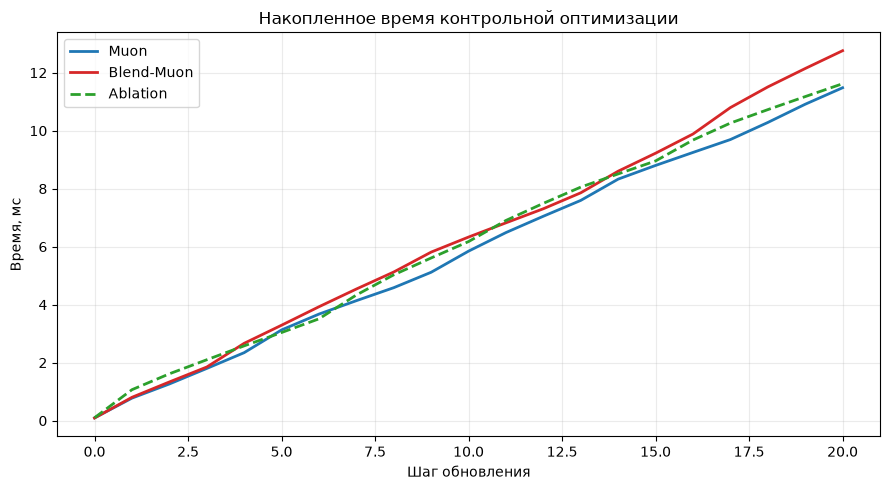


Все проверки измерительных функций пройдены.
Отключение диагностики не изменяет траектории.
Время измеряется без профилировщика памяти.
Для времени используется медиана трёх измерений.
Память PyTorch и Python измеряется отдельно.
Измерения памяти не характеризуют полный RSS процесса.
Постоянное числовое состояние: 656 байт у всех методов.
Контрольные измерения не входят в основной эксперимент.
Тестовая выборка для оценки моделей не использовалась.


In [7]:
# =============================================
# Проверка совпадения состояний оптимизаторов
# =============================================

def states_equal(state_a, state_b):

    if state_a.keys() != state_b.keys():
        return False

    for key in state_a:

        value_a = state_a[key]
        value_b = state_b[key]

        if isinstance(value_a, torch.Tensor):

            if not torch.equal(value_a, value_b):
                return False

        elif value_a != value_b:

            return False

    return True


# =============================================
# Проверка воспроизводимости запуска
# без диагностических вычислений
# =============================================

def validate_core_replay(reference, replay):

    assert reference["method"] == replay["method"]

    assert reference["seed"] == replay["seed"]

    assert reference["alpha"] == replay["alpha"]

    assert torch.equal(
        reference["initial_theta"],
        replay["initial_theta"]
    )

    assert torch.equal(
        reference["final_theta"],
        replay["final_theta"]
    )

    assert states_equal(
        reference["final_state"],
        replay["final_state"]
    )

    assert (
        reference["accepted_history"]
        == replay["accepted_history"]
    )

    assert (
        reference["accepted_steps"]
        == replay["accepted_steps"]
    )

    assert (
        reference["rejected_steps"]
        == replay["rejected_steps"]
    )

    diagnostic_keys = {
        "full_train_loss_calls",
        "full_gradient_calls",
        "validation_loss_calls",
        "diagnostic_train_samples",
        "diagnostic_validation_samples"
    }

    # Основные вычислительные затраты
    # должны полностью совпадать

    for key in reference["counters"]:

        if key not in diagnostic_keys:

            assert (
                reference["counters"][key]
                == replay["counters"][key]
            )

        else:

            assert replay["counters"][key] == 0

    assert len(replay["iteration_history"]) == 0

    return True


# =============================================
# Проверка всей траектории параметров
# =============================================

def validate_parameter_path(reference):

    n_steps = len(
        reference["iteration_history"]
    ) - 1

    replay = optimize(
        method=reference["method"],
        network_seed=reference["seed"],
        alpha=reference["alpha"],
        n_iterations=n_steps,
        record_history=False,
        save_path=True
    )

    validate_core_replay(
        reference,
        replay
    )

    reference_path = reference[
        "iteration_history"
    ]

    replay_path = replay[
        "parameter_history"
    ]

    assert len(reference_path) == len(replay_path)

    maximum_error = 0.0

    for record, theta in zip(
        reference_path,
        replay_path
    ):

        error = torch.max(
            torch.abs(record["theta"] - theta)
        ).item()

        maximum_error = max(
            maximum_error,
            error
        )

        assert torch.equal(
            record["theta"],
            theta
        )

    return maximum_error


# =============================================
# Измерение времени оптимизации
# =============================================

timing_repeats = 3


def measure_core_time(
    reference,
    n_measurements=timing_repeats
):

    n_steps = len(
        reference["iteration_history"]
    ) - 1

    measurements = []

    for measurement in range(n_measurements):

        gc.collect()

        replay = optimize(
            method=reference["method"],
            network_seed=reference["seed"],
            alpha=reference["alpha"],
            n_iterations=n_steps,
            record_history=False,
            save_path=False
        )

        validate_core_replay(
            reference,
            replay
        )

        measurements.append({
            "measurement": measurement + 1,

            "core_time_ms": replay["core_time_ms"],

            "elapsed_time_ms": (
                replay["elapsed_time_ms"]
            ),

            "core_time_history_ms": (
                replay["core_time_history_ms"].copy()
            )
        })

    # Выбираем фактически выполненный запуск
    # с медианным временем оптимизации

    sorted_measurements = sorted(
        measurements,
        key=lambda record: record["core_time_ms"]
    )

    median_measurement = sorted_measurements[
        len(sorted_measurements) // 2
    ]

    times = np.array([
        record["core_time_ms"]
        for record in measurements
    ])

    assert np.isfinite(times).all()

    assert np.all(times > 0)

    assert np.all(
        np.diff(
            median_measurement["core_time_history_ms"]
        ) >= 0
    )

    return {
        "core_time_ms": (
            median_measurement["core_time_ms"]
        ),

        "elapsed_time_ms": (
            median_measurement["elapsed_time_ms"]
        ),

        "core_time_history_ms": (
            median_measurement[
                "core_time_history_ms"
            ]
        ),

        "mean_time_ms": times.mean(),

        "std_time_ms": (
            times.std(ddof=1)
            if len(times) > 1
            else 0.0
        ),

        "min_time_ms": times.min(),

        "max_time_ms": times.max(),

        "measurements": measurements
    }


# =============================================
# Обработка событий выделения памяти PyTorch
# =============================================

def analyze_memory_trace(trace_path):

    with open(
        trace_path,
        "r",
        encoding="utf-8",
        errors="replace"
    ) as file:

        trace_data = json.load(file)

    memory_events = []

    for event in trace_data.get(
        "traceEvents", []
    ):

        if event.get("name") != "[memory]":
            continue

        args = event.get("args", {})

        # Device Type = 0 соответствует CPU
        if args.get("Device Type") != 0:
            continue

        if (
            "Bytes" not in args
            or "Addr" not in args
        ):
            continue

        memory_events.append({
            "timestamp": event.get("ts", 0),

            "address": args["Addr"],

            "bytes": int(args["Bytes"])
        })

    memory_events.sort(
        key=lambda event: event["timestamp"]
    )

    active_allocations = {}

    current_memory = 0

    peak_memory = 0

    total_allocated = 0

    allocation_count = 0

    deallocation_count = 0

    ignored_deallocations = 0

    for event in memory_events:

        size = event["bytes"]

        address = event["address"]

        if size > 0:

            # Выделение памяти
            allocation_count += 1

            total_allocated += size

            if address in active_allocations:

                current_memory -= active_allocations[
                    address
                ]

            active_allocations[address] = size

            current_memory += size

            peak_memory = max(
                peak_memory,
                current_memory
            )

        elif size < 0:

            deallocation_count += 1

            if address in active_allocations:

                current_memory -= (
                    active_allocations.pop(address)
                )

            else:

                # Не учитываем освобождение памяти,
                # выделенной до начала профилирования

                ignored_deallocations += 1

    return {
        "peak_memory_bytes": peak_memory,

        "peak_memory_kib": peak_memory / 1024,

        "total_allocated_bytes": total_allocated,

        "allocation_count": allocation_count,

        "deallocation_count": deallocation_count,

        "ignored_deallocations": ignored_deallocations,

        "remaining_memory_bytes": current_memory,

        "memory_events": len(memory_events)
    }


# =============================================
# Измерение дополнительной памяти PyTorch
# =============================================

def measure_torch_peak_memory(reference):

    n_steps = len(
        reference["iteration_history"]
    ) - 1

    gc.collect()

    with tempfile.TemporaryDirectory() as temp_dir:

        trace_path = (
            Path(temp_dir) / "memory_trace.json"
        )

        with profile(
            activities=[ProfilerActivity.CPU],
            profile_memory=True,
            record_shapes=False,
            with_stack=False
        ) as profiler:

            replay = optimize(
                method=reference["method"],

                network_seed=reference["seed"],

                alpha=reference["alpha"],

                n_iterations=n_steps,

                record_history=False,

                save_path=False
            )

        validate_core_replay(
            reference,
            replay
        )

        profiler.export_chrome_trace(
            str(trace_path)
        )

        memory_result = analyze_memory_trace(
            trace_path
        )

    assert memory_result["memory_events"] > 0

    assert memory_result["allocation_count"] > 0

    assert memory_result["peak_memory_bytes"] > 0

    return memory_result


# =============================================
# Измерение дополнительной памяти Python
# =============================================

def measure_python_peak_memory(reference):

    n_steps = len(
        reference["iteration_history"]
    ) - 1

    gc.collect()

    tracemalloc.start()

    try:

        initial_memory, _ = (
            tracemalloc.get_traced_memory()
        )

        tracemalloc.reset_peak()

        replay = optimize(
            method=reference["method"],

            network_seed=reference["seed"],

            alpha=reference["alpha"],

            n_iterations=n_steps,

            record_history=False,

            save_path=False
        )

        current_memory, peak_memory = (
            tracemalloc.get_traced_memory()
        )

    finally:

        tracemalloc.stop()

    validate_core_replay(
        reference,
        replay
    )

    additional_peak = max(
        0,
        peak_memory - initial_memory
    )

    additional_current = (
        current_memory - initial_memory
    )

    return {
        "peak_memory_bytes": additional_peak,

        "peak_memory_kib": additional_peak / 1024,

        "remaining_memory_bytes": additional_current
    }


# =============================================
# Проверка измерительных функций
# =============================================

measurement_check_results = {}

measurement_check_records = []

for method in methods:

    reference = smoke_test_results[method]

    print(f"Проверка измерений: {method}")

    # Проверка всей траектории без диагностики
    path_error = validate_parameter_path(
        reference
    )

    # Измерение времени без профилирования
    timing_result = measure_core_time(
        reference
    )

    # Отдельное измерение памяти PyTorch
    torch_memory_result = (
        measure_torch_peak_memory(reference)
    )

    # Отдельное измерение памяти Python
    python_memory_result = (
        measure_python_peak_memory(reference)
    )

    measurement_check_results[method] = {
        "path_error": path_error,

        "timing": timing_result,

        "torch_memory": torch_memory_result,

        "python_memory": python_memory_result
    }

    measurement_check_records.append({
        "Метод": method,

        "Alpha": reference["alpha"],

        "Шагов": len(
            reference["accepted_history"]
        ),

        "Ошибка воспроизведения траектории": (
            path_error
        ),

        "Медианное время оптимизации, мс": (
            timing_result["core_time_ms"]
        ),

        "Среднее время, мс": (
            timing_result["mean_time_ms"]
        ),

        "Std времени, мс": (
            timing_result["std_time_ms"]
        ),

        "Полное время без диагностики, мс": (
            timing_result["elapsed_time_ms"]
        ),

        "Время запуска с диагностикой, мс": (
            reference["elapsed_time_ms"]
        ),

        "Пиковая память PyTorch, КиБ": (
            torch_memory_result[
                "peak_memory_kib"
            ]
        ),

        "Пиковая память Python, КиБ": (
            python_memory_result[
                "peak_memory_kib"
            ]
        ),

        "Выделений памяти PyTorch": (
            torch_memory_result[
                "allocation_count"
            ]
        ),

        "Событий памяти": (
            torch_memory_result[
                "memory_events"
            ]
        ),

        "Постоянное состояние, байт": (
            optimizer_state_bytes(
                reference["final_state"]
            )
        )
    })


measurement_check_df = pd.DataFrame(
    measurement_check_records
)

print("\nРезультаты проверки измерений:")

display(
    measurement_check_df.style
    .hide(axis="index")
    .format({
        "Alpha": "{:.2f}",

        "Ошибка воспроизведения траектории":
            "{:.8e}",

        "Медианное время оптимизации, мс":
            "{:.6f}",

        "Среднее время, мс":
            "{:.6f}",

        "Std времени, мс":
            "{:.6f}",

        "Полное время без диагностики, мс":
            "{:.6f}",

        "Время запуска с диагностикой, мс":
            "{:.6f}",

        "Пиковая память PyTorch, КиБ":
            "{:.6f}",

        "Пиковая память Python, КиБ":
            "{:.6f}"
    })
)


# =============================================
# Отдельные измерения времени
# =============================================

timing_check_records = []

for method in methods:

    measurements = (
        measurement_check_results[method]
        ["timing"]["measurements"]
    )

    for measurement in measurements:

        timing_check_records.append({
            "Метод": method,

            "Измерение": (
                measurement["measurement"]
            ),

            "Время оптимизации, мс": (
                measurement["core_time_ms"]
            ),

            "Полное время без диагностики, мс": (
                measurement["elapsed_time_ms"]
            )
        })


timing_check_df = pd.DataFrame(
    timing_check_records
)

print("\nПовторные измерения времени:")

display(
    timing_check_df.style
    .hide(axis="index")
    .format({
        "Время оптимизации, мс": "{:.6f}",

        "Полное время без диагностики, мс":
            "{:.6f}"
    })
)


# =============================================
# Проверка накопленного времени
# =============================================

fig, ax = plt.subplots(figsize=(9, 5))

for method in methods:

    time_history = (
        measurement_check_results[method]
        ["timing"]["core_time_history_ms"]
    )

    assert len(time_history) == (
        smoke_test_iterations + 1
    )

    ax.plot(
        np.arange(len(time_history)),

        time_history,

        color=method_colors[method],

        linestyle=(
            "--" if method == "Ablation" else "-"
        ),

        linewidth=2,

        label=method
    )

ax.set_title(
    "Накопленное время контрольной оптимизации"
)

ax.set_xlabel("Шаг обновления")

ax.set_ylabel("Время, мс")

ax.grid(alpha=0.25)

ax.legend()

plt.tight_layout()
plt.show()


# =============================================
# Итоговые проверки
# =============================================

assert len(measurement_check_df) == 3

assert len(timing_check_df) == 9

assert (
    measurement_check_df[
        "Ошибка воспроизведения траектории"
    ] == 0
).all()

assert (
    measurement_check_df[
        "Постоянное состояние, байт"
    ] == expected_state_bytes
).all()

assert (
    measurement_check_df[
        "Пиковая память PyTorch, КиБ"
    ] > 0
).all()

assert (
    measurement_check_df[
        "Пиковая память Python, КиБ"
    ] > 0
).all()

print("\nВсе проверки измерительных функций пройдены.")

print("Отключение диагностики не изменяет траектории.")

print("Время измеряется без профилировщика памяти.")

print("Для времени используется медиана трёх измерений.")

print("Память PyTorch и Python измеряется отдельно.")

print("Измерения памяти не характеризуют полный RSS процесса.")

print("Постоянное числовое состояние: 656 байт у всех методов.")

print("Контрольные измерения не входят в основной эксперимент.")

print("Тестовая выборка для оценки моделей не использовалась.")


Подбор alpha = 0.25
  Seed 1: best validation loss = 0.62913093; принято 150/150
  Seed 2: best validation loss = 0.63534217; принято 150/150
  Seed 3: best validation loss = 0.63099347; принято 150/150
  Seed 4: best validation loss = 0.60877627; принято 150/150
  Seed 5: best validation loss = 0.62038405; принято 150/150

Подбор alpha = 0.50
  Seed 1: best validation loss = 0.63016033; принято 150/150
  Seed 2: best validation loss = 0.63783610; принято 150/150
  Seed 3: best validation loss = 0.63272305; принято 150/150
  Seed 4: best validation loss = 0.60860407; принято 150/150
  Seed 5: best validation loss = 0.61847355; принято 150/150

Подбор alpha = 0.75
  Seed 1: best validation loss = 0.63167812; принято 150/150
  Seed 2: best validation loss = 0.63801493; принято 150/150
  Seed 3: best validation loss = 0.63131319; принято 150/150
  Seed 4: best validation loss = 0.61206471; принято 150/150
  Seed 5: best validation loss = 0.62339115; принято 150/150

Результаты всех запус

Alpha,Seed,Конечный Train loss,Конечный Validation loss,Минимальный Validation loss,Лучшая итерация,Норма полного градиента,Принято шагов,Отклонено шагов,Нечисловая диагностика
0.25000000,1,0.62782868,0.62913093,0.62913093,150,0.07511998,150,0,0
0.25000000,2,0.62365256,0.64907674,0.63534217,95,0.05900878,150,0,0
0.25000000,3,0.61608797,0.63929707,0.63099347,59,0.02270314,150,0,0
0.25000000,4,0.61985114,0.63986613,0.60877627,70,0.02896440,150,0,0
0.25000000,5,0.62267307,0.64190356,0.62038405,103,0.04951444,150,0,0
0.50000000,1,0.62728206,0.63068703,0.63016033,145,0.07778223,150,0,0
0.50000000,2,0.62399744,0.64988781,0.63783610,92,0.06009944,150,0,0
0.50000000,3,0.61699267,0.64288612,0.63272305,53,0.02518806,150,0,0
0.50000000,4,0.61834431,0.64988910,0.60860407,56,0.02619632,150,0,0
0.50000000,5,0.62156489,0.63640775,0.61847355,103,0.04692282,150,0,0



Средние результаты подбора:


Alpha,Повторов,Минимальный Validation loss,Конечный Train loss,Конечный Validation loss,Лучшая итерация,Отклонено шагов,Выбран
0.25,5,0.62492538 ± 0.01054082,0.62201869 ± 0.00437965,0.63985489 ± 0.00715112,95.40 ± 35.39,0,True
0.50,5,0.62555942 ± 0.01184162,0.62163627 ± 0.00417897,0.64195156 ± 0.00843335,89.80 ± 37.82,0,False
0.75,5,0.62729242 ± 0.00996840,0.62186174 ± 0.00436223,0.64137167 ± 0.00708559,87.40 ± 42.91,0,False



Минимальный Validation loss по общим seed:


Alpha,0.250000,0.500000,0.750000
seed,,,
1,0.62913093,0.63016033,0.63167812
2,0.63534217,0.63783610,0.63801493
3,0.63099347,0.63272305,0.63131319
4,0.60877627,0.60860407,0.61206471
5,0.62038405,0.61847355,0.62339115



Парные различия относительно выбранного Alpha:


Выбранный Alpha,Сравниваемый Alpha,Средняя разность,Std разности,Выбранный лучше,Выбранный хуже,Совпадений
0.25,0.50,-0.00063404,0.00172774,3,2,0
0.25,0.75,-0.00236704,0.00118069,5,0,0


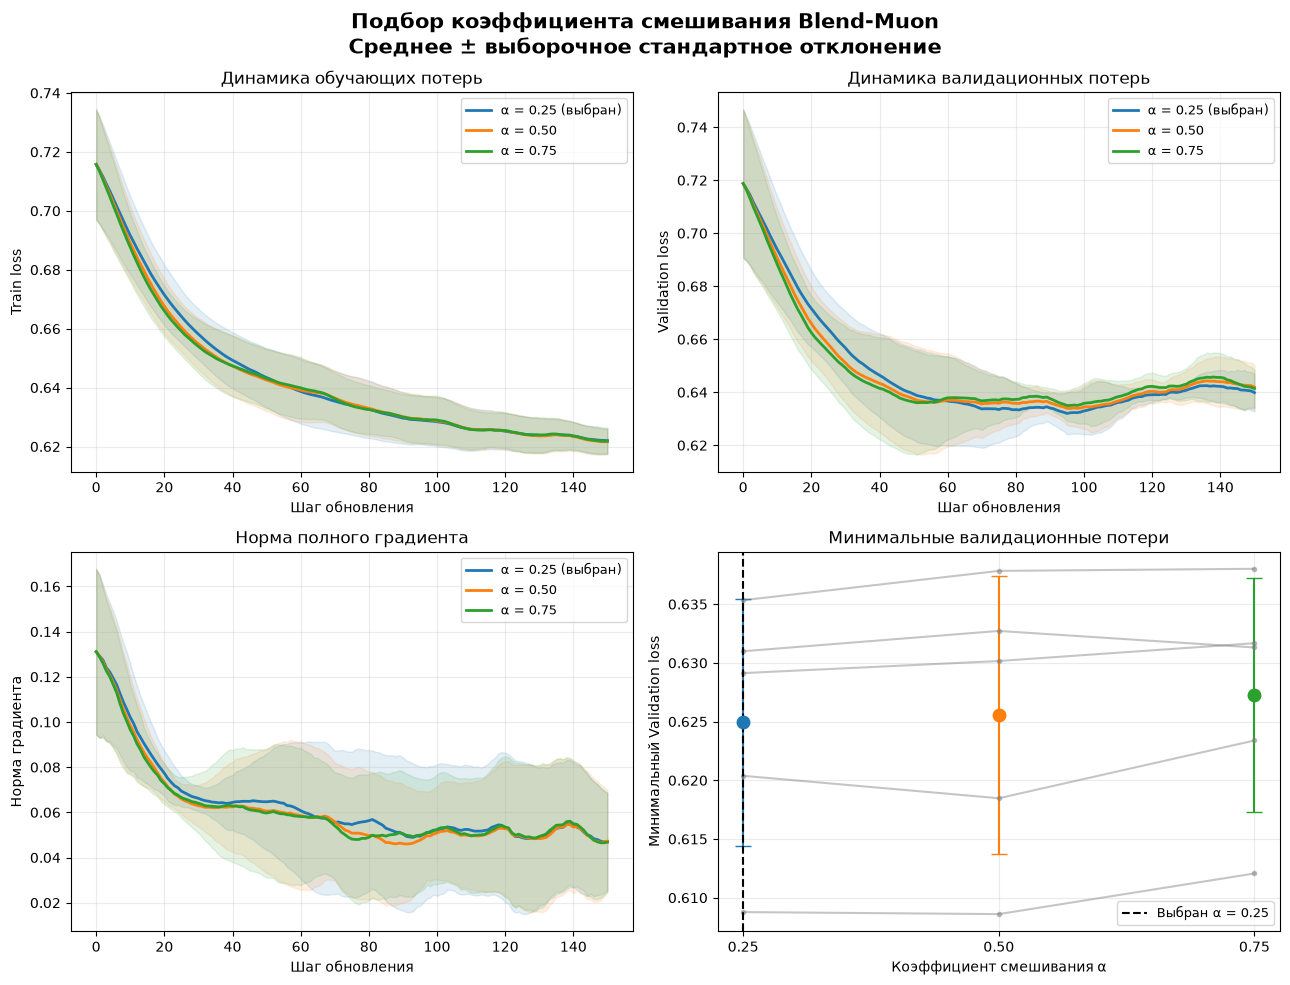


Вычислительные затраты предварительного подбора:


Показатель,Значение
Количество запусков,15
Попытки обновления,2250
Принятые обновления,2250
Отклонённые обновления,0
Основные обратные проходы,2250
Диагностические обратные проходы,2265
Всего обратных проходов,4515
Всего вычислений функции потерь,6780
Обработано наблюдений при обучении,70080
Вызовы матричной дуализации,2250



Ранжирование коэффициентов:


alpha,best_val_mean,best_val_std,rejected_steps
0.25000000,0.62492538,0.01054082,0
0.50000000,0.62555942,0.01184162,0
0.75000000,0.62729242,0.00996840,0



Выбранный коэффициент alpha: 0.25
Средний минимальный validation loss: 0.62492538
Полное время подбора с диагностикой, сек: 2.756534
Всего выполнено запусков: 15
Попыток обновления: 2250
Отклонённых шагов: 0
Коэффициент выбран исключительно по Validation.
Настройки исходного Muon и AdamW не изменялись.
Затраты подбора учитываются отдельно.
Тестовая выборка для оценки моделей не использовалась.


In [8]:
# =============================================
# Подбор коэффициента смешивания
# =============================================

tuning_results = {}

tuning_records = []

tuning_start = perf_counter()

for alpha in alpha_grid:

    print(f"\nПодбор alpha = {alpha:.2f}")

    for network_seed in network_seeds:

        result = optimize(
            method="Blend-Muon",
            network_seed=network_seed,
            alpha=alpha,
            n_iterations=iterations,
            record_history=True
        )

        history = result["iteration_history"]

        best = result["best_record"]

        counters = result["counters"]

        assert len(history) == iterations + 1

        assert counters["batch_gradient_calls"] == iterations

        assert counters["full_gradient_calls"] == iterations + 1

        assert (
            counters["processed_samples"]
            == expected_processed_samples
        )

        assert (
            result["accepted_steps"]
            + result["rejected_steps"]
            == iterations
        )

        assert torch.equal(
            result["initial_theta"],
            initial_parameters[network_seed]
        )

        # Проверка последовательности мини-батчей
        for record, expected in zip(
            history[1:],
            batch_schedules[network_seed]
        ):

            assert np.array_equal(
                record["batch_indices"],
                expected["original_indices"]
            )

        tuning_results[
            (alpha, network_seed)
        ] = result

        best_validation_loss = (
            best["validation_loss"]
            if best is not None
            else np.inf
        )

        tuning_records.append({
            "alpha": alpha,

            "seed": network_seed,

            "initial_train_loss": (
                history[0]["train_loss"]
            ),

            "initial_validation_loss": (
                history[0]["validation_loss"]
            ),

            "final_train_loss": (
                history[-1]["train_loss"]
            ),

            "final_validation_loss": (
                history[-1]["validation_loss"]
            ),

            "best_validation_loss": best_validation_loss,

            "best_iteration": (
                best["iteration"]
                if best is not None
                else np.nan
            ),

            "final_gradient_norm": (
                history[-1]["gradient_norm"]
            ),

            "accepted_steps": result["accepted_steps"],

            "rejected_steps": result["rejected_steps"],

            "nonfinite_diagnostics": sum(
                not record["diagnostics_finite"]
                for record in history
            ),

            "train_loss_increases": int(
                np.sum(
                    np.diff([
                        record["train_loss"]
                        for record in history
                    ]) > 0
                )
            ),

            "validation_loss_increases": int(
                np.sum(
                    np.diff([
                        record["validation_loss"]
                        for record in history
                    ]) > 0
                )
            ),

            "mean_matrix_update_norm": np.mean([
                record["matrix_update_norm"]
                for record in history[1:]
            ]),

            "elapsed_time_ms": result["elapsed_time_ms"],

            "state_bytes": optimizer_state_bytes(
                result["final_state"]
            ),

            **counters
        })

        print(
            f"  Seed {network_seed}: "
            f"best validation loss = "
            f"{best_validation_loss:.8f}; "
            f"принято {result['accepted_steps']}/150"
        )


tuning_elapsed_time = (
    perf_counter() - tuning_start
)

tuning_df = pd.DataFrame(tuning_records)

assert len(tuning_results) == tuning_runs

assert len(tuning_df) == tuning_runs


# =============================================
# Результаты отдельных запусков
# =============================================

tuning_display_columns = {
    "alpha": "Alpha",
    "seed": "Seed",
    "final_train_loss": "Конечный Train loss",
    "final_validation_loss": "Конечный Validation loss",
    "best_validation_loss": "Минимальный Validation loss",
    "best_iteration": "Лучшая итерация",
    "final_gradient_norm": "Норма полного градиента",
    "accepted_steps": "Принято шагов",
    "rejected_steps": "Отклонено шагов",
    "nonfinite_diagnostics": "Нечисловая диагностика"
}

print("\nРезультаты всех запусков подбора:")

display(
    tuning_df[
        list(tuning_display_columns)
    ]
    .rename(columns=tuning_display_columns)
    .style.hide(axis="index")
    .format(precision=8)
)


# =============================================
# Средние результаты и стандартные отклонения
# =============================================

tuning_summary = (
    tuning_df
    .groupby("alpha")
    .agg(
        repeats=("seed", "count"),

        best_val_mean=(
            "best_validation_loss", "mean"
        ),

        best_val_std=(
            "best_validation_loss", "std"
        ),

        final_train_mean=(
            "final_train_loss", "mean"
        ),

        final_train_std=(
            "final_train_loss", "std"
        ),

        final_val_mean=(
            "final_validation_loss", "mean"
        ),

        final_val_std=(
            "final_validation_loss", "std"
        ),

        best_iteration_mean=(
            "best_iteration", "mean"
        ),

        best_iteration_std=(
            "best_iteration", "std"
        ),

        final_gradient_mean=(
            "final_gradient_norm", "mean"
        ),

        final_gradient_std=(
            "final_gradient_norm", "std"
        ),

        rejected_steps=(
            "rejected_steps", "sum"
        ),

        nonfinite_diagnostics=(
            "nonfinite_diagnostics", "sum"
        )
    )
    .reset_index()
)

assert (
    tuning_summary["repeats"] == n_repeats
).all()


# =============================================
# Выбор итогового коэффициента
# =============================================

# При равенстве минимальных потерь
# выбирается меньший коэффициент alpha.

valid_candidates = tuning_summary[
    np.isfinite(tuning_summary["best_val_mean"])
].copy()

if valid_candidates.empty:

    raise RuntimeError(
        "Нет коэффициентов с конечным критерием "
        "валидационного качества."
    )

ranked_candidates = valid_candidates.sort_values(
    ["best_val_mean", "alpha"],
    ascending=[True, True]
)

selected_alpha = float(
    ranked_candidates.iloc[0]["alpha"]
)

alpha_star = selected_alpha

selected_validation_loss = float(
    ranked_candidates.iloc[0]["best_val_mean"]
)

assert selected_alpha in alpha_grid

tuning_summary["selected"] = (
    tuning_summary["alpha"] == selected_alpha
)


# =============================================
# Сводная таблица качества
# =============================================

tuning_quality_df = pd.DataFrame({

    "Alpha": tuning_summary["alpha"],

    "Повторов": tuning_summary["repeats"],

    "Минимальный Validation loss": [
        f"{mean:.8f} ± {std:.8f}"
        for mean, std in zip(
            tuning_summary["best_val_mean"],
            tuning_summary["best_val_std"]
        )
    ],

    "Конечный Train loss": [
        f"{mean:.8f} ± {std:.8f}"
        for mean, std in zip(
            tuning_summary["final_train_mean"],
            tuning_summary["final_train_std"]
        )
    ],

    "Конечный Validation loss": [
        f"{mean:.8f} ± {std:.8f}"
        for mean, std in zip(
            tuning_summary["final_val_mean"],
            tuning_summary["final_val_std"]
        )
    ],

    "Лучшая итерация": [
        f"{mean:.2f} ± {std:.2f}"
        for mean, std in zip(
            tuning_summary["best_iteration_mean"],
            tuning_summary["best_iteration_std"]
        )
    ],

    "Отклонено шагов": (
        tuning_summary["rejected_steps"]
    ),

    "Выбран": tuning_summary["selected"]
})

print("\nСредние результаты подбора:")

display(
    tuning_quality_df.style
    .hide(axis="index")
    .format({"Alpha": "{:.2f}"})
)


# =============================================
# Парное сравнение коэффициентов
# =============================================

paired_tuning_df = tuning_df.pivot(
    index="seed",
    columns="alpha",
    values="best_validation_loss"
)

paired_tuning_df.columns.name = "Alpha"

print("\nМинимальный Validation loss по общим seed:")

display(
    paired_tuning_df.style
    .format("{:.8f}")
    .highlight_min(
        axis=1,
        color="#d4edda"
    )
)

paired_comparison_records = []

for alpha in alpha_grid:

    if alpha == selected_alpha:

        continue

    differences = (
        paired_tuning_df[selected_alpha]
        - paired_tuning_df[alpha]
    )

    paired_comparison_records.append({
        "Выбранный Alpha": selected_alpha,

        "Сравниваемый Alpha": alpha,

        "Средняя разность": differences.mean(),

        "Std разности": differences.std(ddof=1),

        "Выбранный лучше": int(
            (differences < 0).sum()
        ),

        "Выбранный хуже": int(
            (differences > 0).sum()
        ),

        "Совпадений": int(
            (differences == 0).sum()
        )
    })


paired_tuning_comparison_df = pd.DataFrame(
    paired_comparison_records
)

print("\nПарные различия относительно выбранного Alpha:")

display(
    paired_tuning_comparison_df.style
    .hide(axis="index")
    .format({
        "Выбранный Alpha": "{:.2f}",

        "Сравниваемый Alpha": "{:.2f}",

        "Средняя разность": "{:.8f}",

        "Std разности": "{:.8f}"
    })
)


# =============================================
# Истории обучения при подборе
# =============================================

tuning_history_records = []

for (alpha, network_seed), result in (
    tuning_results.items()
):

    for record in result["iteration_history"]:

        tuning_history_records.append({
            "alpha": alpha,

            "seed": network_seed,

            "iteration": record["iteration"],

            "train_loss": record["train_loss"],

            "validation_loss": record["validation_loss"],

            "gradient_norm": record["gradient_norm"],

            "matrix_update_norm": (
                record["matrix_update_norm"]
            )
        })


tuning_history_df = pd.DataFrame(
    tuning_history_records
)

assert len(tuning_history_df) == (
    tuning_runs * (iterations + 1)
)

tuning_trajectory_stats = (
    tuning_history_df
    .groupby(["alpha", "iteration"])[
        [
            "train_loss",
            "validation_loss",
            "gradient_norm",
            "matrix_update_norm"
        ]
    ]
    .agg(["mean", "std"])
)


# =============================================
# Визуализация результатов подбора
# =============================================

alpha_colors = {
    0.25: "#1f77b4",
    0.50: "#ff7f0e",
    0.75: "#2ca02c"
}

fig, axes = plt.subplots(
    2, 2,
    figsize=(13, 10)
)

plot_metrics = [
    (
        axes[0, 0],
        "train_loss",
        "Динамика обучающих потерь",
        "Train loss"
    ),

    (
        axes[0, 1],
        "validation_loss",
        "Динамика валидационных потерь",
        "Validation loss"
    ),

    (
        axes[1, 0],
        "gradient_norm",
        "Норма полного градиента",
        "Норма градиента"
    )
]

for ax, metric, title, ylabel in plot_metrics:

    for alpha in alpha_grid:

        stats = tuning_trajectory_stats.loc[alpha]

        steps = stats.index.to_numpy()

        mean_values = stats[
            (metric, "mean")
        ].to_numpy()

        std_values = stats[
            (metric, "std")
        ].to_numpy()

        color = alpha_colors[alpha]

        label = f"α = {alpha:.2f}"

        if alpha == selected_alpha:

            label += " (выбран)"

        ax.plot(
            steps,
            mean_values,
            color=color,
            linewidth=2,
            label=label
        )

        ax.fill_between(
            steps,
            mean_values - std_values,
            mean_values + std_values,
            color=color,
            alpha=0.12
        )

    ax.set_title(title)

    ax.set_xlabel("Шаг обновления")

    ax.set_ylabel(ylabel)

    ax.legend(fontsize=9)

    ax.grid(alpha=0.25)


# Сравнение критерия выбора коэффициента

for _, row in tuning_summary.iterrows():

    alpha = row["alpha"]

    axes[1, 1].errorbar(
        alpha,

        row["best_val_mean"],

        yerr=row["best_val_std"],

        fmt="o",

        markersize=9,

        capsize=6,

        color=alpha_colors[alpha]
    )

# Соединяем результаты одинаковых seed
for network_seed in network_seeds:

    axes[1, 1].plot(
        alpha_grid,

        paired_tuning_df.loc[
            network_seed,
            alpha_grid
        ],

        color="gray",

        alpha=0.45,

        marker="."
    )

axes[1, 1].axvline(
    selected_alpha,

    color="black",

    linestyle="--",

    label=f"Выбран α = {selected_alpha:.2f}"
)

axes[1, 1].set_title(
    "Минимальные валидационные потери"
)

axes[1, 1].set_xlabel("Коэффициент смешивания α")

axes[1, 1].set_ylabel("Минимальный Validation loss")

axes[1, 1].set_xticks(alpha_grid)

axes[1, 1].legend(fontsize=9)

axes[1, 1].grid(alpha=0.25)

fig.suptitle(
    "Подбор коэффициента смешивания Blend-Muon\n"
    "Среднее ± выборочное стандартное отклонение",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()
plt.show()


# =============================================
# Вычислительные затраты подбора
# =============================================

tuning_total_counters = {
    key: sum(
        result["counters"][key]
        for result in tuning_results.values()
    )

    for key in initialize_counters()
}

tuning_cost_df = pd.DataFrame({
    "Показатель": [
        "Количество запусков",

        "Попытки обновления",

        "Принятые обновления",

        "Отклонённые обновления",

        "Основные обратные проходы",

        "Диагностические обратные проходы",

        "Всего обратных проходов",

        "Всего вычислений функции потерь",

        "Обработано наблюдений при обучении",

        "Вызовы матричной дуализации",

        "Итерации Ньютона — Шульца",

        "Матричные умножения NS",

        "Вызовы смешивания",

        "Дополнительные нормы",

        "Дополнительные масштабирования",

        "Дополнительные сложения",

        "Резервные переходы",

        "Вычисления матриц кривизны",

        "Сингулярные разложения при обучении"
    ],

    "Значение": [
        len(tuning_results),

        tuning_updates,

        tuning_df["accepted_steps"].sum(),

        tuning_df["rejected_steps"].sum(),

        tuning_total_counters["batch_gradient_calls"],

        tuning_total_counters["full_gradient_calls"],

        (
            tuning_total_counters["batch_gradient_calls"]
            + tuning_total_counters["full_gradient_calls"]
        ),

        (
            tuning_total_counters["batch_loss_calls"]
            + tuning_total_counters["full_train_loss_calls"]
            + tuning_total_counters["validation_loss_calls"]
        ),

        tuning_total_counters["processed_samples"],

        tuning_total_counters["ns_calls"],

        tuning_total_counters["ns_iterations"],

        tuning_total_counters["ns_matmuls"],

        tuning_total_counters["blend_calls"],

        tuning_total_counters["blend_norm_calls"],

        tuning_total_counters["blend_matrix_scales"],

        tuning_total_counters["blend_matrix_additions"],

        tuning_total_counters["blend_fallbacks"],

        tuning_total_counters["curvature_builds"],

        tuning_total_counters["svd_calls"]
    ]
})

print("\nВычислительные затраты предварительного подбора:")

display(
    tuning_cost_df.style.hide(axis="index")
)

assert (
    tuning_total_counters["batch_gradient_calls"]
    == tuning_updates
)

assert (
    tuning_total_counters["full_gradient_calls"]
    == tuning_runs * (iterations + 1)
)

assert (
    tuning_total_counters["processed_samples"]
    == tuning_runs * expected_processed_samples
)

assert tuning_total_counters["curvature_builds"] == 0

assert tuning_total_counters["svd_calls"] == 0


# =============================================
# Итог подбора
# =============================================

print("\nРанжирование коэффициентов:")

display(
    ranked_candidates[
        [
            "alpha",
            "best_val_mean",
            "best_val_std",
            "rejected_steps"
        ]
    ]
    .style.hide(axis="index")
    .format(precision=8)
)

print(f"\nВыбранный коэффициент alpha: {selected_alpha:.2f}")

print(
    "Средний минимальный validation loss:",
    f"{selected_validation_loss:.8f}"
)

print(
    "Полное время подбора с диагностикой, сек:",
    f"{tuning_elapsed_time:.6f}"
)

print("Всего выполнено запусков:", len(tuning_results))

print("Попыток обновления:", tuning_updates)

print(
    "Отклонённых шагов:",
    tuning_df["rejected_steps"].sum()
)

print("Коэффициент выбран исключительно по Validation.")

print("Настройки исходного Muon и AdamW не изменялись.")

print("Затраты подбора учитываются отдельно.")

print("Тестовая выборка для оценки моделей не использовалась.")

In [9]:
# =============================================
# Основной эксперимент
# =============================================

experiment_results = {}

measurement_results = {}

experiment_records = []

experiment_start = perf_counter()

for repeat_index, network_seed in enumerate(network_seeds):

    print(f"\nПовторение: seed = {network_seed}")

    # Циклическое изменение порядка методов
    offset = repeat_index % len(methods)

    run_order = (
        methods[offset:] + methods[:offset]
    )

    for method in run_order:

        alpha = (
            selected_alpha
            if method == "Blend-Muon"
            else 0.0
        )

        print(f"  {method}, alpha = {alpha:.2f}")

        # =====================================
        # Обучение с полной историей
        # =====================================

        result = optimize(
            method=method,
            network_seed=network_seed,
            alpha=alpha,
            n_iterations=iterations,
            record_history=True
        )

        history = result["iteration_history"]

        counters = result["counters"]

        initial = history[0]

        final = history[-1]

        best = result["best_record"]

        experiment_results[
            (method, network_seed)
        ] = result

        # =====================================
        # Проверка условий эксперимента
        # =====================================

        assert len(history) == iterations + 1

        assert torch.equal(
            result["initial_theta"],
            initial_parameters[network_seed]
        )

        assert (
            result["accepted_steps"]
            + result["rejected_steps"]
            == iterations
        )

        assert counters["batch_gradient_calls"] == iterations

        assert counters["full_gradient_calls"] == iterations + 1

        assert counters["validation_loss_calls"] == iterations + 1

        assert (
            counters["processed_samples"]
            == expected_processed_samples
        )

        assert final["total_loss_calls"] == 452

        assert final["total_backward_calls"] == 301

        assert counters["curvature_builds"] == 0

        assert counters["hessian_calls"] == 0

        assert counters["jacobian_calls"] == 0

        assert counters["svd_calls"] == 0

        assert (
            optimizer_state_bytes(result["final_state"])
            == expected_state_bytes
        )

        for record, expected_batch in zip(
            history[1:],
            batch_schedules[network_seed]
        ):

            assert np.array_equal(
                record["batch_indices"],
                expected_batch["original_indices"]
            )

        # Проверка накопленных счётчиков
        for key in initialize_counters():

            assert np.all(
                np.diff([
                    record[key] for record in history
                ]) >= 0
            )

        # Проверка сохранения нормы направления
        norm_errors = [
            record["direction_norm_error"]

            for record in history[1:]

            if record["accepted"]
        ]

        max_norm_error = (
            max(norm_errors)
            if norm_errors
            else np.nan
        )

        if norm_errors:

            assert max_norm_error < 1e-10

        # =====================================
        # Проверка повторного запуска
        # выбранной модификации
        # =====================================

        tuning_replay_error = np.nan

        if method == "Blend-Muon":

            tuning_reference = tuning_results[
                (selected_alpha, network_seed)
            ]

            reference_history = tuning_reference[
                "iteration_history"
            ]

            tuning_replay_error = max(
                torch.max(
                    torch.abs(
                        current["theta"]
                        - reference["theta"]
                    )
                ).item()

                for current, reference in zip(
                    history,
                    reference_history
                )
            )

            assert tuning_replay_error == 0

            assert states_equal(
                result["final_state"],
                tuning_reference["final_state"]
            )

        # =====================================
        # Независимые измерения стоимости
        # =====================================

        path_error = validate_parameter_path(
            result
        )

        timing = measure_core_time(
            result
        )

        torch_memory = measure_torch_peak_memory(
            result
        )

        python_memory = measure_python_peak_memory(
            result
        )

        measurement_results[
            (method, network_seed)
        ] = {
            "path_error": path_error,
            "timing": timing,
            "torch_memory": torch_memory,
            "python_memory": python_memory
        }

        # =====================================
        # Характеристики траектории
        # =====================================

        train_losses = np.array([
            record["train_loss"]
            for record in history
        ])

        validation_losses = np.array([
            record["validation_loss"]
            for record in history
        ])

        gradient_norms = np.array([
            record["gradient_norm"]
            for record in history
        ])

        matrix_update_norms = np.array([
            record["matrix_update_norm"]
            for record in history[1:]
        ])

        step_norms = np.array([
            record["step_norm"]
            for record in history[1:]
        ])

        # =====================================
        # Сохранение результатов запуска
        # =====================================

        experiment_records.append({
            "method": method,

            "seed": network_seed,

            "alpha": alpha,

            "initial_train_loss": initial["train_loss"],

            "initial_validation_loss": (
                initial["validation_loss"]
            ),

            "final_train_loss": final["train_loss"],

            "final_validation_loss": (
                final["validation_loss"]
            ),

            "min_train_loss": np.min(train_losses),

            "best_validation_loss": (
                best["validation_loss"]
                if best is not None
                else np.nan
            ),

            "best_iteration": (
                best["iteration"]
                if best is not None
                else np.nan
            ),

            "train_loss_at_best": (
                best["train_loss"]
                if best is not None
                else np.nan
            ),

            "initial_gradient_norm": (
                initial["gradient_norm"]
            ),

            "final_gradient_norm": (
                final["gradient_norm"]
            ),

            "min_gradient_norm": np.min(
                gradient_norms
            ),

            "train_loss_reduction": (
                1 - final["train_loss"]
                / initial["train_loss"]
            ),

            "validation_loss_reduction": (
                1 - final["validation_loss"]
                / initial["validation_loss"]
            ),

            "generalization_gap": (
                final["validation_loss"]
                - final["train_loss"]
            ),

            "train_loss_increases": int(
                np.sum(np.diff(train_losses) > 0)
            ),

            "validation_loss_increases": int(
                np.sum(np.diff(validation_losses) > 0)
            ),

            "mean_step_norm": step_norms.mean(),

            "std_step_norm": step_norms.std(ddof=1),

            "mean_matrix_update_norm": (
                matrix_update_norms.mean()
            ),

            "std_matrix_update_norm": (
                matrix_update_norms.std(ddof=1)
            ),

            "max_direction_norm_error": max_norm_error,

            "accepted_steps": result["accepted_steps"],

            "rejected_steps": result["rejected_steps"],

            "nonfinite_diagnostics": sum(
                not record["diagnostics_finite"]
                for record in history
            ),

            "core_time_ms": timing["core_time_ms"],

            "timing_std_ms": timing["std_time_ms"],

            "elapsed_without_diagnostics_ms": (
                timing["elapsed_time_ms"]
            ),

            "total_time_ms": result["elapsed_time_ms"],

            "torch_peak_memory_kib": (
                torch_memory["peak_memory_kib"]
            ),

            "python_peak_memory_kib": (
                python_memory["peak_memory_kib"]
            ),

            "torch_allocations": (
                torch_memory["allocation_count"]
            ),

            "torch_total_allocated_bytes": (
                torch_memory["total_allocated_bytes"]
            ),

            "state_bytes": optimizer_state_bytes(
                result["final_state"]
            ),

            "path_replay_error": path_error,

            "tuning_replay_error": tuning_replay_error,

            **counters,

            "total_backward_calls": (
                final["total_backward_calls"]
            ),

            "total_loss_calls": (
                final["total_loss_calls"]
            ),

            "total_processed_samples": (
                final["total_processed_samples"]
            )
        })

        best_loss = (
            best["validation_loss"]
            if best is not None
            else np.nan
        )

        print(
            f"    Train = {final['train_loss']:.8f}; "
            f"Best Val = {best_loss:.8f}; "
            f"Time = {timing['core_time_ms']:.3f} ms; "
            f"Accepted = {result['accepted_steps']}/150"
        )


experiment_elapsed_time = (
    perf_counter() - experiment_start
)

experiment_df = pd.DataFrame(
    experiment_records
)

experiment_df["method"] = pd.Categorical(
    experiment_df["method"],
    categories=methods,
    ordered=True
)

experiment_df = experiment_df.sort_values(
    ["method", "seed"]
).reset_index(drop=True)

assert len(experiment_results) == 15

assert len(measurement_results) == 15

assert len(experiment_df) == 15


# =============================================
# Проверка парных условий эксперимента
# =============================================

pair_check_records = []

for network_seed in network_seeds:

    muon_result = experiment_results[
        ("Muon", network_seed)
    ]

    ablation_result = experiment_results[
        ("Ablation", network_seed)
    ]

    blend_result = experiment_results[
        ("Blend-Muon", network_seed)
    ]

    muon_history = muon_result["iteration_history"]

    ablation_history = ablation_result["iteration_history"]

    blend_history = blend_result["iteration_history"]

    maximum_ablation_error = 0.0

    for record_m, record_a, record_b in zip(
        muon_history,
        ablation_history,
        blend_history
    ):

        # Muon и Ablation должны совпадать
        error = torch.max(
            torch.abs(
                record_m["theta"] - record_a["theta"]
            )
        ).item()

        maximum_ablation_error = max(
            maximum_ablation_error,
            error
        )

        assert torch.equal(
            record_m["theta"],
            record_a["theta"]
        )

        assert torch.equal(
            record_m["full_gradient"],
            record_a["full_gradient"]
        )

        assert states_equal(
            record_m["optimizer_state"],
            record_a["optimizer_state"]
        )

        assert (
            record_m["train_loss"]
            == record_a["train_loss"]
        )

        assert (
            record_m["validation_loss"]
            == record_a["validation_loss"]
        )

        # Общие мини-батчи всех методов
        if record_m["iteration"] > 0:

            assert np.array_equal(
                record_m["batch_indices"],
                record_a["batch_indices"]
            )

            assert np.array_equal(
                record_m["batch_indices"],
                record_b["batch_indices"]
            )

    assert torch.equal(
        muon_result["initial_theta"],
        blend_result["initial_theta"]
    )

    assert (
        muon_result["counters"]
        == ablation_result["counters"]
    )

    assert (
        muon_result["accepted_history"]
        == ablation_result["accepted_history"]
    )

    final_blend_difference = torch.linalg.vector_norm(
        muon_result["final_theta"]
        - blend_result["final_theta"]
    ).item()

    pair_check_records.append({
        "Seed": network_seed,

        "Общие начальные параметры": True,

        "Общие мини-батчи": True,

        "Ошибка Muon/Ablation": (
            maximum_ablation_error
        ),

        "Различие конечных параметров Muon/Blend": (
            final_blend_difference
        )
    })


pair_check_df = pd.DataFrame(
    pair_check_records
)

print("\nПроверка парных условий:")

display(
    pair_check_df.style
    .hide(axis="index")
    .format({
        "Ошибка Muon/Ablation": "{:.8e}",

        "Различие конечных параметров Muon/Blend":
            "{:.8e}"
    })
)


# =============================================
# Результаты отдельных повторений
# =============================================

quality_columns = {
    "method": "Метод",

    "seed": "Seed",

    "final_train_loss": "Конечный Train loss",

    "final_validation_loss": "Конечный Validation loss",

    "best_validation_loss": "Минимальный Validation loss",

    "best_iteration": "Лучшая итерация",

    "final_gradient_norm": "Норма полного градиента",

    "accepted_steps": "Принято шагов",

    "rejected_steps": "Отклонено шагов"
}

print("\nРезультаты основного эксперимента:")

display(
    experiment_df[
        list(quality_columns)
    ]
    .rename(columns=quality_columns)
    .style.hide(axis="index")
    .format(precision=8)
)


# =============================================
# Результаты измерений стоимости
# =============================================

cost_columns = {
    "method": "Метод",

    "seed": "Seed",

    "core_time_ms": "Время оптимизации, мс",

    "total_time_ms": "Время с диагностикой, мс",

    "torch_peak_memory_kib": "Память PyTorch, КиБ",

    "python_peak_memory_kib": "Память Python, КиБ",

    "torch_allocations": "Выделений памяти",

    "state_bytes": "Постоянное состояние, байт"
}

print("\nВычислительные затраты отдельных запусков:")

display(
    experiment_df[
        list(cost_columns)
    ]
    .rename(columns=cost_columns)
    .style.hide(axis="index")
    .format(precision=6)
)


# =============================================
# Средние результаты по пяти повторениям
# =============================================

summary_metrics = [
    "initial_train_loss",

    "initial_validation_loss",

    "final_train_loss",

    "final_validation_loss",

    "min_train_loss",

    "best_validation_loss",

    "best_iteration",

    "train_loss_at_best",

    "final_gradient_norm",

    "min_gradient_norm",

    "train_loss_reduction",

    "validation_loss_reduction",

    "generalization_gap",

    "train_loss_increases",

    "validation_loss_increases",

    "mean_matrix_update_norm",

    "std_matrix_update_norm",

    "core_time_ms",

    "total_time_ms",

    "torch_peak_memory_kib",

    "python_peak_memory_kib",

    "torch_allocations",

    "state_bytes"
]

experiment_summary = (
    experiment_df
    .groupby("method", observed=True)[
        summary_metrics
    ]
    .agg(["mean", "std"])
    .reindex(methods)
)

summary_display_records = []

for metric in summary_metrics:

    row = {"Показатель": metric}

    for method in methods:

        mean = experiment_summary.loc[
            method, (metric, "mean")
        ]

        std = experiment_summary.loc[
            method, (metric, "std")
        ]

        row[method] = (
            f"{mean:.8f} ± {std:.8f}"
        )

    summary_display_records.append(row)


experiment_summary_df = pd.DataFrame(
    summary_display_records
)

print("\nСреднее ± выборочное стандартное отклонение:")

display(
    experiment_summary_df.style.hide(axis="index")
)


# =============================================
# Парные различия качества
# =============================================

paired_metrics = [
    "final_train_loss",

    "final_validation_loss",

    "best_validation_loss",

    "final_gradient_norm",

    "core_time_ms"
]

paired_difference_records = []

for metric in paired_metrics:

    paired_values = experiment_df.pivot(
        index="seed",
        columns="method",
        values=metric
    )

    differences = (
        paired_values["Blend-Muon"]
        - paired_values["Muon"]
    )

    paired_difference_records.append({
        "Показатель": metric,

        "Среднее Blend - Muon": differences.mean(),

        "Std разности": differences.std(ddof=1),

        "Blend меньше": int((differences < 0).sum()),

        "Blend больше": int((differences > 0).sum()),

        "Совпадений": int((differences == 0).sum())
    })


paired_difference_df = pd.DataFrame(
    paired_difference_records
)

print("\nПарные различия Blend-Muon относительно Muon:")

display(
    paired_difference_df.style
    .hide(axis="index")
    .format(precision=8)
)


# =============================================
# Сводный бюджет основного эксперимента
# =============================================

main_total_counters = {
    key: sum(
        result["counters"][key]

        for result in experiment_results.values()
    )

    for key in initialize_counters()
}

total_accepted = int(
    experiment_df["accepted_steps"].sum()
)

total_rejected = int(
    experiment_df["rejected_steps"].sum()
)

main_cost_df = pd.DataFrame({
    "Показатель": [
        "Запусков",

        "Попыток обновления",

        "Принятых обновлений",

        "Отклонённых обновлений",

        "Нечисловая диагностика",

        "Сохранённых состояний",

        "Основных обратных проходов",

        "Диагностических обратных проходов",

        "Всего обратных проходов",

        "Всего вычислений функции потерь",

        "Обработано наблюдений при обучении",

        "Итераций Ньютона — Шульца",

        "Матричных умножений NS",

        "Дополнительных смешиваний",

        "Дополнительных норм",

        "Дополнительных масштабирований",

        "Дополнительных сложений",

        "Резервных переходов",

        "Вычислений матриц кривизны",

        "Сингулярных разложений при обучении"
    ],

    "Значение": [
        len(experiment_results),

        main_updates,

        total_accepted,

        total_rejected,

        experiment_df["nonfinite_diagnostics"].sum(),

        sum(
            len(result["iteration_history"])
            for result in experiment_results.values()
        ),

        main_total_counters["batch_gradient_calls"],

        main_total_counters["full_gradient_calls"],

        experiment_df["total_backward_calls"].sum(),

        experiment_df["total_loss_calls"].sum(),

        main_total_counters["processed_samples"],

        main_total_counters["ns_iterations"],

        main_total_counters["ns_matmuls"],

        main_total_counters["blend_calls"],

        main_total_counters["blend_norm_calls"],

        main_total_counters["blend_matrix_scales"],

        main_total_counters["blend_matrix_additions"],

        main_total_counters["blend_fallbacks"],

        main_total_counters["curvature_builds"],

        main_total_counters["svd_calls"]
    ]
})

print("\nБюджет основного эксперимента:")

display(
    main_cost_df.style.hide(axis="index")
)


# =============================================
# Дополнительные измерительные запуски
# =============================================

measurement_replays_per_run = (
    1                  # Проверка полной траектории
    + timing_repeats    # Измерения времени
    + 1                # Профилирование PyTorch
    + 1                # Измерение памяти Python
)

measurement_runs = (
    main_runs * measurement_replays_per_run
)

measurement_updates = (
    measurement_runs * iterations
)

total_budget_df = pd.DataFrame({
    "Этап": [
        "Подбор alpha",

        "Основной эксперимент",

        "Измерительные воспроизведения",

        "Всего без предварительных проверок"
    ],

    "Запусков": [
        tuning_runs,

        main_runs,

        measurement_runs,

        tuning_runs + main_runs + measurement_runs
    ],

    "Попыток обновления": [
        tuning_updates,

        main_updates,

        measurement_updates,

        tuning_updates + main_updates + measurement_updates
    ]
})

print("\nПолный бюджет исследования:")

display(
    total_budget_df.style.hide(axis="index")
)


# =============================================
# Предварительная проверка гипотезы
# =============================================

muon_mean_best = experiment_summary.loc[
    "Muon",
    ("best_validation_loss", "mean")
]

blend_mean_best = experiment_summary.loc[
    "Blend-Muon",
    ("best_validation_loss", "mean")
]

ablation_mean_best = experiment_summary.loc[
    "Ablation",
    ("best_validation_loss", "mean")
]

validation_difference = (
    blend_mean_best - muon_mean_best
)

relative_validation_improvement = (
    (muon_mean_best - blend_mean_best)
    / muon_mean_best
    * 100
)

print("\nОсновной критерий исследования:")

print(
    f"Muon:       {muon_mean_best:.8f}"
)

print(
    f"Blend-Muon: {blend_mean_best:.8f}"
)

print(
    f"Ablation:   {ablation_mean_best:.8f}"
)

print(
    f"Разность Blend - Muon: "
    f"{validation_difference:+.8f}"
)

print(
    f"Относительное улучшение Validation loss: "
    f"{relative_validation_improvement:+.4f}%"
)

if validation_difference < 0:

    print(
        "Основной валидационный критерий "
        "предварительно поддерживает гипотезу."
    )

elif validation_difference > 0:

    print(
        "Основной валидационный критерий "
        "не поддерживает гипотезу."
    )

else:

    print(
        "Различий по основному критерию не обнаружено."
    )


# =============================================
# Итоговые проверки
# =============================================

assert total_accepted + total_rejected == main_updates

assert main_total_counters["batch_gradient_calls"] == 2250

assert main_total_counters["full_gradient_calls"] == 2265

assert experiment_df["total_backward_calls"].sum() == 4515

assert experiment_df["total_loss_calls"].sum() == 6780

assert main_total_counters["processed_samples"] == 70080

assert (
    experiment_df["path_replay_error"] == 0
).all()

assert (
    experiment_df.loc[
        experiment_df["method"] == "Blend-Muon",
        "tuning_replay_error"
    ] == 0
).all()

assert (
    pair_check_df["Ошибка Muon/Ablation"] == 0
).all()

assert (
    experiment_df["state_bytes"]
    == expected_state_bytes
).all()

assert main_total_counters["curvature_builds"] == 0

assert main_total_counters["svd_calls"] == 0

print("\nОсновной эксперимент завершён.")

print("Выбранный alpha:", selected_alpha)

print("Основных запусков:", len(experiment_results))

print("Принятых шагов:", total_accepted)

print("Отклонённых шагов:", total_rejected)

print(
    "Полное время эксперимента с измерениями, сек:",
    f"{experiment_elapsed_time:.6f}"
)

print("Muon и Ablation совпадают во всех пяти повторениях.")

print("Все траектории воспроизведены без погрешности.")

print("Результаты подбора Blend-Muon воспроизведены.")

print("Измерительные запуски учтены отдельно.")

print("Тестовая выборка для оценки моделей не использовалась.")


Повторение: seed = 1
  Muon, alpha = 0.00
    Train = 0.62892759; Best Val = 0.63712094; Time = 88.006 ms; Accepted = 150/150
  Blend-Muon, alpha = 0.25
    Train = 0.62782868; Best Val = 0.62913093; Time = 84.586 ms; Accepted = 150/150
  Ablation, alpha = 0.00
    Train = 0.62892759; Best Val = 0.63712094; Time = 72.145 ms; Accepted = 150/150

Повторение: seed = 2
  Blend-Muon, alpha = 0.25
    Train = 0.62365256; Best Val = 0.63534217; Time = 79.574 ms; Accepted = 150/150
  Ablation, alpha = 0.00
    Train = 0.62506077; Best Val = 0.64357781; Time = 79.049 ms; Accepted = 150/150
  Muon, alpha = 0.00
    Train = 0.62506077; Best Val = 0.64357781; Time = 76.178 ms; Accepted = 150/150

Повторение: seed = 3
  Ablation, alpha = 0.00
    Train = 0.61512261; Best Val = 0.62783953; Time = 75.854 ms; Accepted = 150/150
  Muon, alpha = 0.00
    Train = 0.61512261; Best Val = 0.62783953; Time = 70.881 ms; Accepted = 150/150
  Blend-Muon, alpha = 0.25
    Train = 0.61608797; Best Val = 0.630993

Seed,Общие начальные параметры,Общие мини-батчи,Ошибка Muon/Ablation,Различие конечных параметров Muon/Blend
1,True,True,0.00000000e+00,2.10096120e+00
2,True,True,0.00000000e+00,1.67370979e+00
3,True,True,0.00000000e+00,1.99917338e+00
4,True,True,0.00000000e+00,1.97676933e+00
5,True,True,0.00000000e+00,1.51685053e+00



Результаты основного эксперимента:


Метод,Seed,Конечный Train loss,Конечный Validation loss,Минимальный Validation loss,Лучшая итерация,Норма полного градиента,Принято шагов,Отклонено шагов
Muon,1,0.62892759,0.63712094,0.63712094,150,0.07952388,150,0
Muon,2,0.62506077,0.64721512,0.64357781,98,0.05973796,150,0
Muon,3,0.61512261,0.63735227,0.62783953,71,0.02533206,150,0
Muon,4,0.61796936,0.64792310,0.62109611,95,0.02378941,150,0
Muon,5,0.62016435,0.63643217,0.62531313,103,0.04594318,150,0
Blend-Muon,1,0.62782868,0.62913093,0.62913093,150,0.07511998,150,0
Blend-Muon,2,0.62365256,0.64907674,0.63534217,95,0.05900878,150,0
Blend-Muon,3,0.61608797,0.63929707,0.63099347,59,0.02270314,150,0
Blend-Muon,4,0.61985114,0.63986613,0.60877627,70,0.02896440,150,0
Blend-Muon,5,0.62267307,0.64190356,0.62038405,103,0.04951444,150,0



Вычислительные затраты отдельных запусков:


Метод,Seed,"Время оптимизации, мс","Время с диагностикой, мс","Память PyTorch, КиБ","Память Python, КиБ",Выделений памяти,"Постоянное состояние, байт"
Muon,1,88.006300,166.397800,11.398438,37.822266,21159,656
Muon,2,76.178000,147.546700,11.398438,37.995117,21159,656
Muon,3,70.880599,146.090000,11.398438,37.995117,21159,656
Muon,4,74.062399,150.931000,11.398438,37.879883,21159,656
Muon,5,72.781100,148.046900,11.398438,37.822266,21159,656
Blend-Muon,1,84.585700,171.964300,11.398438,37.897461,25209,656
Blend-Muon,2,79.573900,179.525600,11.398438,37.782227,25209,656
Blend-Muon,3,82.494099,162.527900,11.398438,37.839844,25209,656
Blend-Muon,4,78.721201,165.331700,11.398438,37.782227,25209,656
Blend-Muon,5,81.381300,162.121900,11.398438,37.897461,25209,656


... (5 outputs left out)

Показатель,Значение
Запусков,15
Попыток обновления,2250
Принятых обновлений,2250
Отклонённых обновлений,0
Нечисловая диагностика,0
Сохранённых состояний,2265
Основных обратных проходов,2250
Диагностических обратных проходов,2265
Всего обратных проходов,4515
Всего вычислений функции потерь,6780



Полный бюджет исследования:


Этап,Запусков,Попыток обновления
Подбор alpha,15,2250
Основной эксперимент,15,2250
Измерительные воспроизведения,90,13500
Всего без предварительных проверок,120,18000



Основной критерий исследования:
Muon:       0.63098950
Blend-Muon: 0.62492538
Ablation:   0.63098950
Разность Blend - Muon: -0.00606413
Относительное улучшение Validation loss: +0.9611%
Основной валидационный критерий предварительно поддерживает гипотезу.

Основной эксперимент завершён.
Выбранный alpha: 0.25
Основных запусков: 15
Принятых шагов: 2250
Отклонённых шагов: 0
Полное время эксперимента с измерениями, сек: 34.567230
Muon и Ablation совпадают во всех пяти повторениях.
Все траектории воспроизведены без погрешности.
Результаты подбора Blend-Muon воспроизведены.
Измерительные запуски учтены отдельно.
Тестовая выборка для оценки моделей не использовалась.


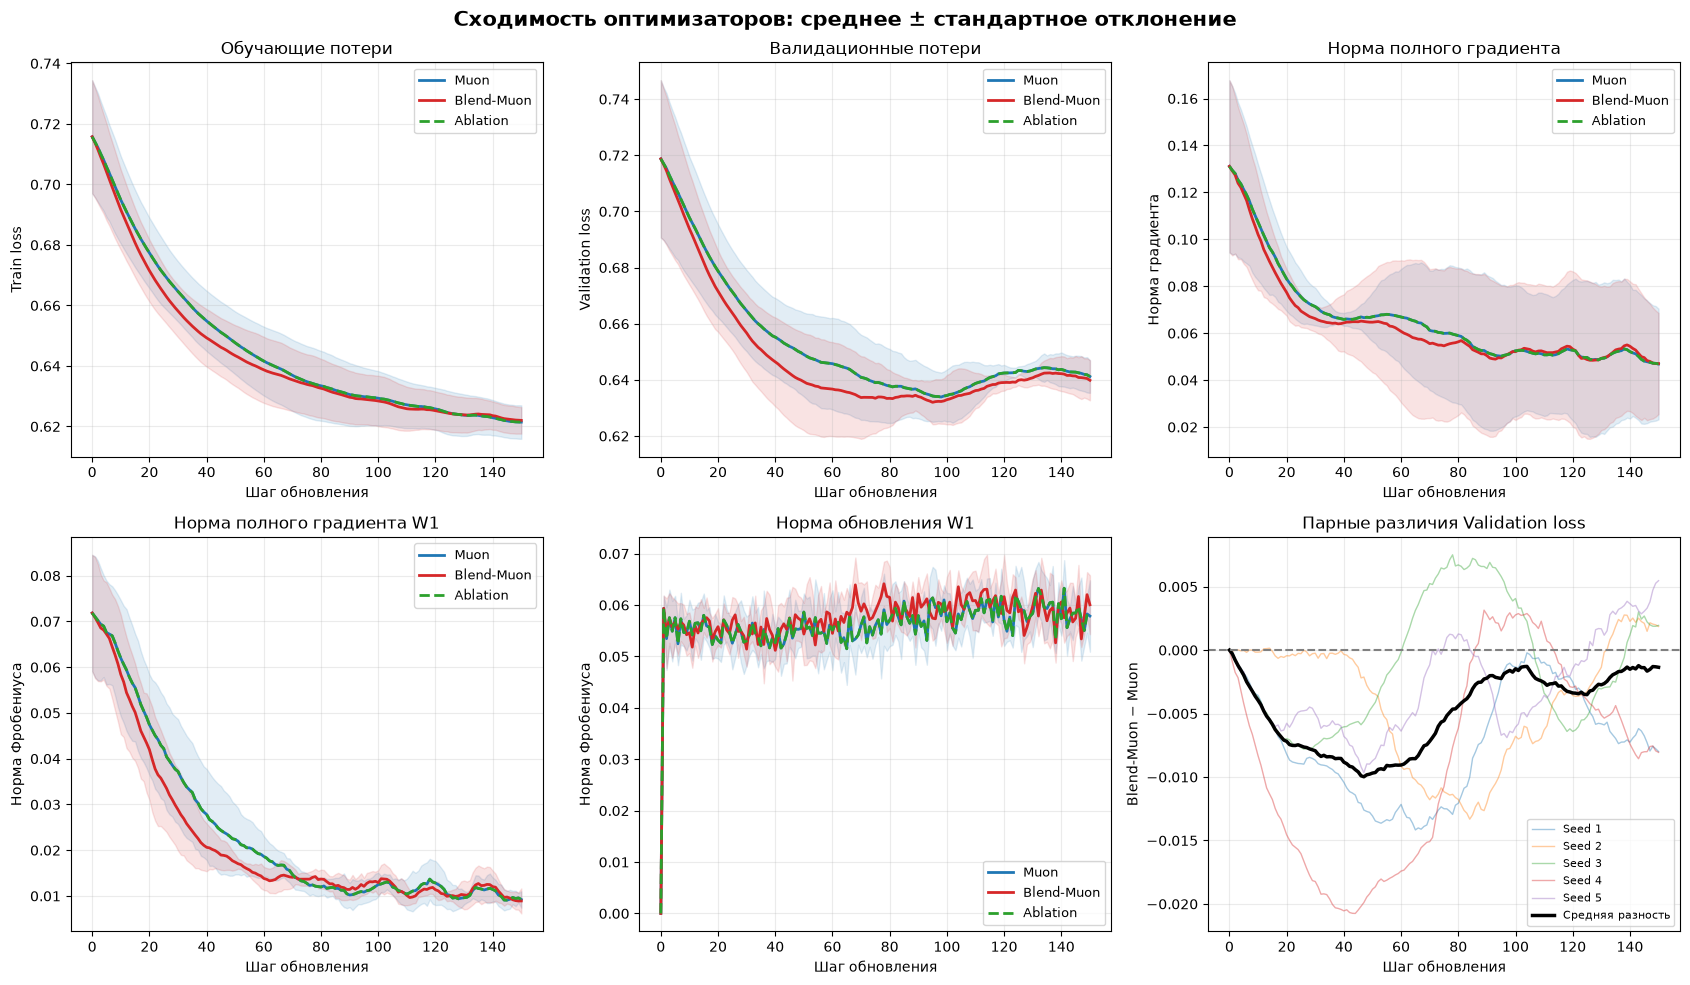

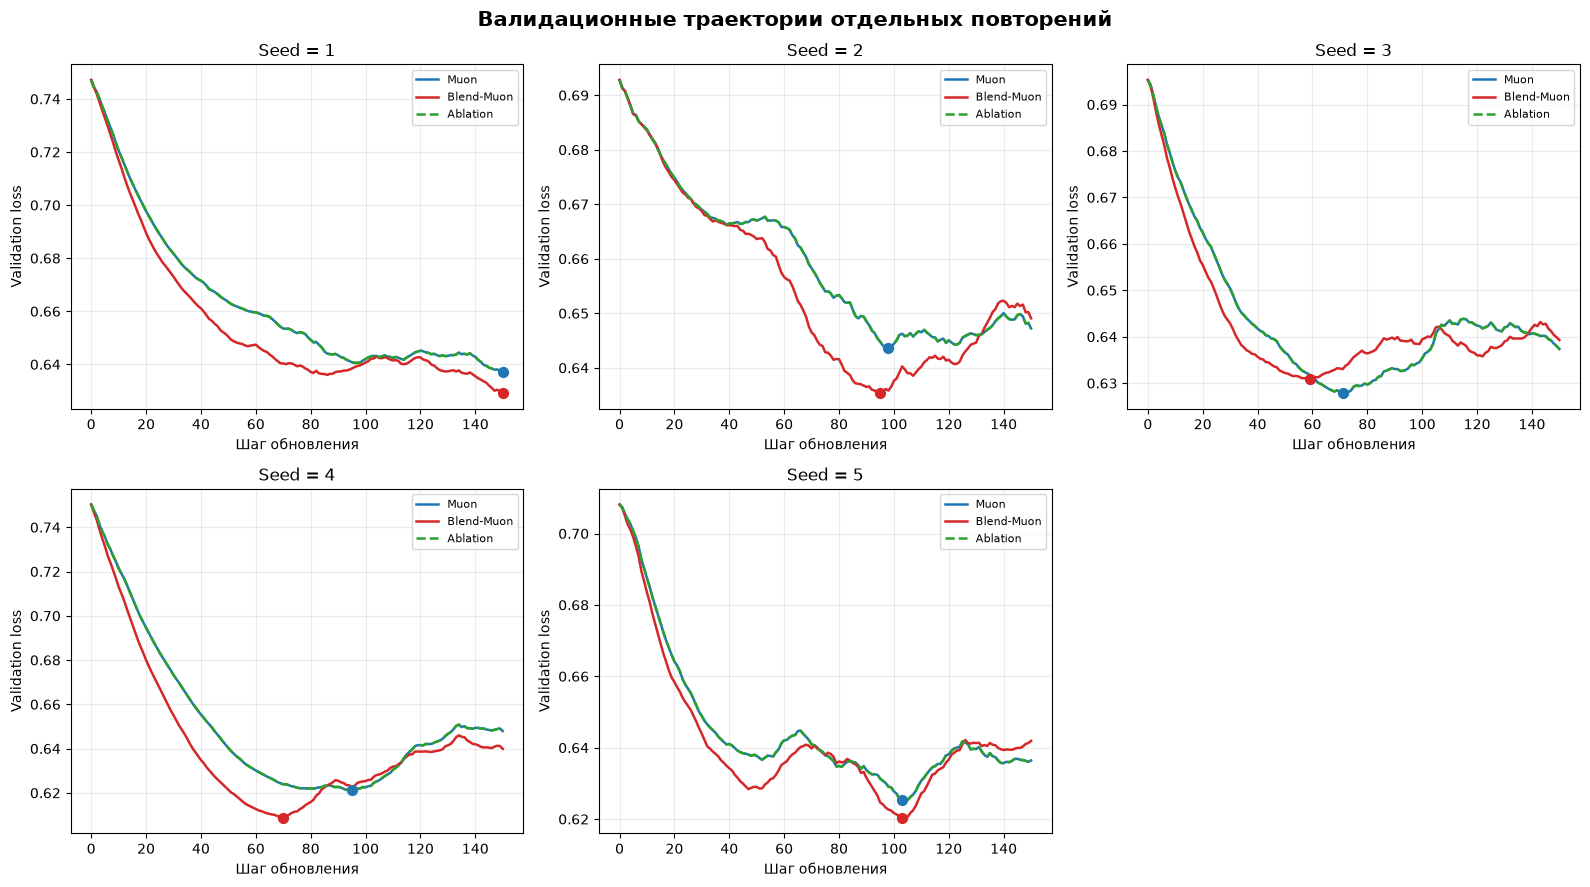

Парное сравнение минимальных Validation loss:


method,Muon,Blend-Muon,Ablation,Blend - Muon,"Улучшение, %"
seed,,,,,
1,0.63712094,0.62913093,0.63712094,-0.00799001,1.25408034
2,0.64357781,0.63534217,0.64357781,-0.00823564,1.27966466
3,0.62783953,0.63099347,0.62783953,0.00315394,-0.50234745
4,0.62109611,0.60877627,0.62109611,-0.01231984,1.98356359
5,0.62531313,0.62038405,0.62531313,-0.00492908,0.78825804


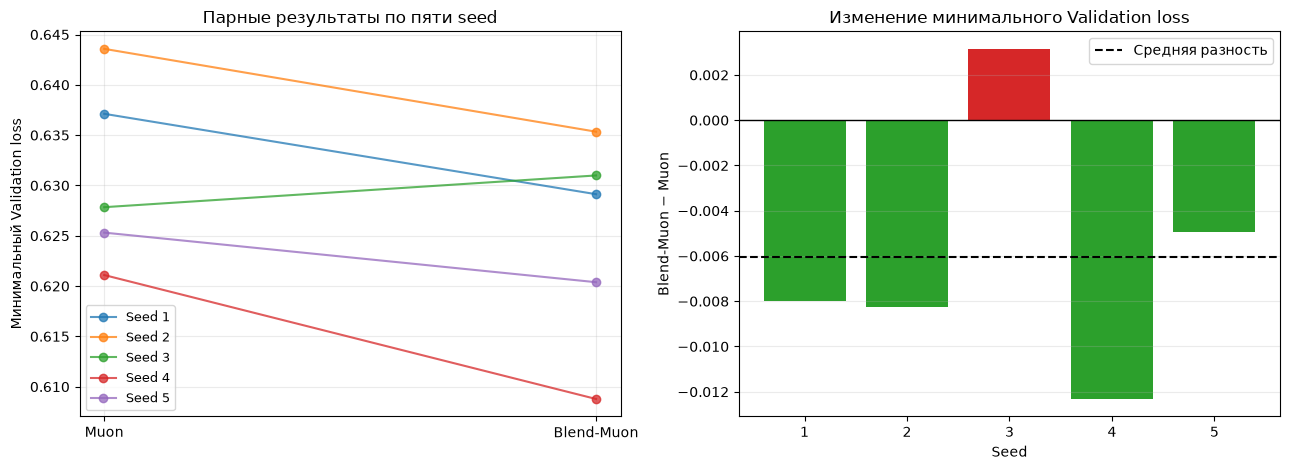


Устойчивость оптимизации: среднее ± std


Показатель,Muon,Blend-Muon,Ablation
Доля направлений спуска всех параметров,0.93733333 ± 0.05046451,0.92533333 ± 0.04356349,0.93733333 ± 0.05046451
Доля направлений спуска W1,0.93333333 ± 0.04988877,0.92133333 ± 0.04253103,0.93333333 ± 0.04988877
Сходство обновления с полным антиградиентом,0.16613014 ± 0.04391379,0.16968906 ± 0.05280342,0.16613014 ± 0.04391379
Сходство обновления W1 с антиградиентом W1,0.42760465 ± 0.07176666,0.42626047 ± 0.05065696,0.42760465 ± 0.07176666
Количество увеличений Train loss,12.80000000 ± 9.57601170,16.20000000 ± 9.70566845,12.80000000 ± 9.57601170
Количество увеличений Validation loss,44.40000000 ± 8.87693641,50.20000000 ± 9.25742945,44.40000000 ± 8.87693641
Среднее абсолютное изменение Train loss,0.00064486 ± 0.00012884,0.00064930 ± 0.00011876,0.00064486 ± 0.00012884
Среднее абсолютное изменение Validation loss,0.00081903 ± 0.00023205,0.00091213 ± 0.00027581,0.00081903 ± 0.00023205
Разброс изменений Train loss,0.00063904 ± 0.00014352,0.00073846 ± 0.00018883,0.00063904 ± 0.00014352
Разброс изменений Validation loss,0.00090992 ± 0.00027382,0.00106432 ± 0.00033030,0.00090992 ± 0.00027382



Суммарное количество увеличений функции потерь:


,train_loss_increases,validation_loss_increases
method,,
Muon,64,222
Blend-Muon,81,251
Ablation,64,222



Устойчивость для разных размеров мини-батчей:



Парные различия устойчивости Blend-Muon и Muon:


Показатель,Средняя разность,Std разности,Blend больше,Blend меньше,Совпадений
Доля направлений спуска всех параметров,-0.01200000,0.03379678,2,2,1
Доля направлений спуска W1,-0.01200000,0.03033150,1,2,2
Сходство обновления с полным антиградиентом,0.00355892,0.01086690,3,2,0
Сходство обновления W1 с антиградиентом W1,-0.00134417,0.04074130,3,2,0
Количество увеличений Train loss,3.40000000,5.31977443,3,2,0
Количество увеличений Validation loss,5.80000000,5.06951674,4,1,0
Разброс изменений Train loss,0.00009942,0.00004677,5,0,0
Разброс изменений Validation loss,0.00015440,0.00006399,5,0,0


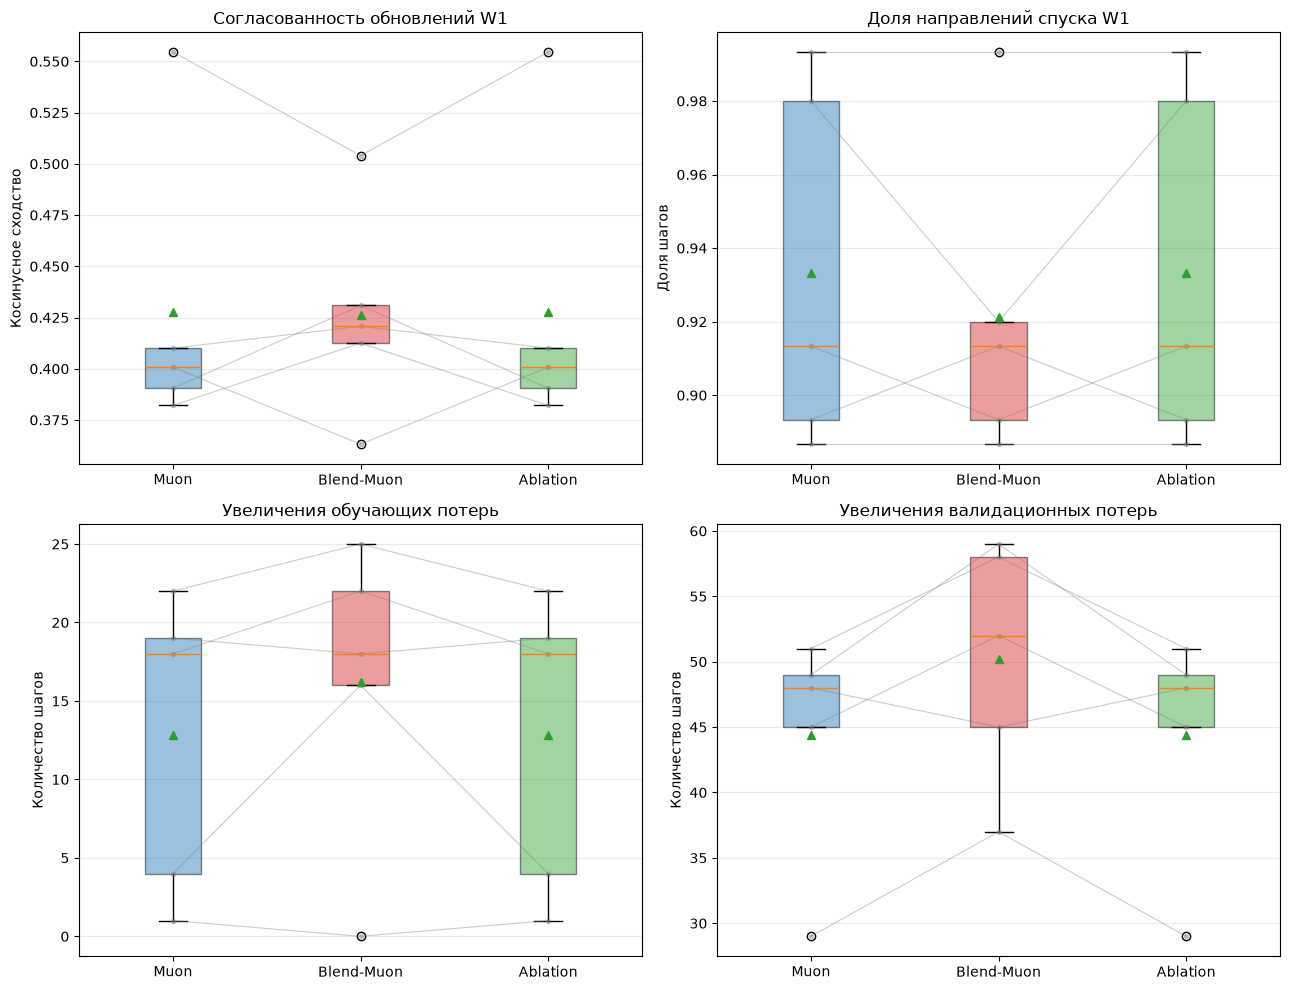

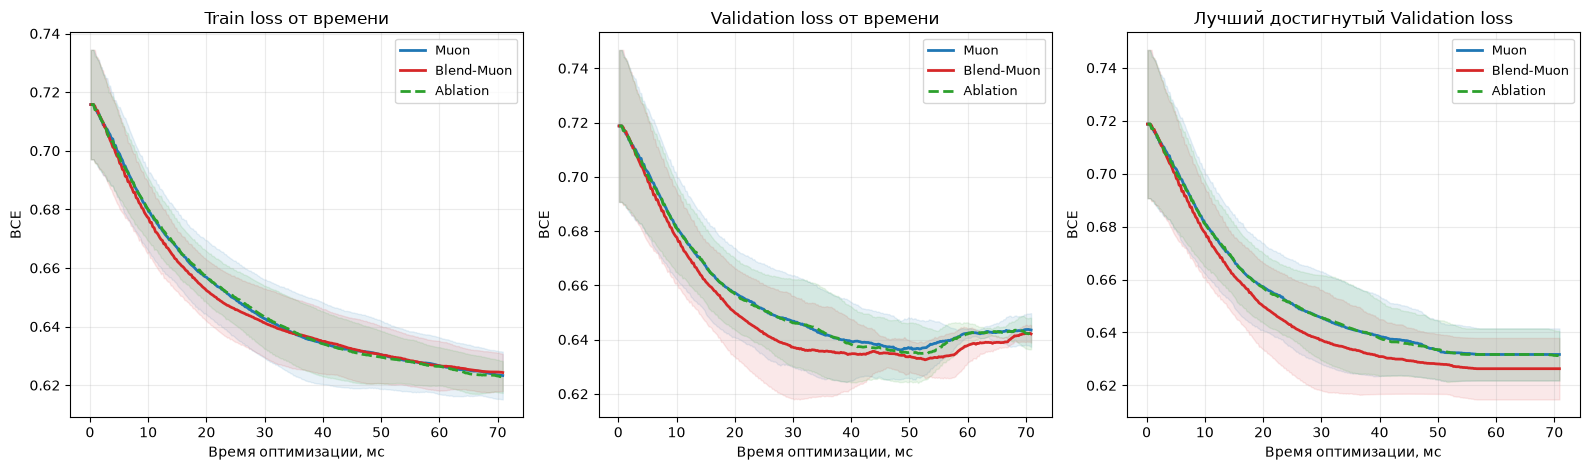


Сравнение при общем времени оптимизации: 70.880599 мс



Время достижения собственного лучшего состояния:



Итоги анализа траекторий:
Blend-Muon лучше по минимальному Validation loss: 4 из 5 повторений
Средняя парная разность Validation loss: -0.00606413
Относительное улучшение основного критерия: 0.9611%

Средняя доля направлений спуска W1:
Muon: 93.33%
Blend-Muon: 92.13%
Ablation: 93.33%

Среднее сходство обновлений W1 с антиградиентом:
Muon: 0.42760465
Blend-Muon: 0.42626047
Ablation: 0.42760465

Muon и Ablation совпадают по всем характеристикам траекторий.
Дополнительные обратные проходы для анализа не выполнялись.
Использованы сохранённые градиенты и параметры.
Тестовая выборка для оценки моделей не использовалась.


In [10]:
# =============================================
# Формирование общей истории эксперимента
# =============================================

history_records = []

for (method, network_seed), result in experiment_results.items():

    history = result["iteration_history"]

    measured_times = measurement_results[
        (method, network_seed)
    ]["timing"]["core_time_history_ms"]

    assert len(history) == len(measured_times)

    for record, measured_time in zip(history, measured_times):

        history_records.append({
            "method": method,
            "seed": network_seed,
            "iteration": record["iteration"],
            "train_loss": record["train_loss"],
            "validation_loss": record["validation_loss"],
            "gradient_norm": record["gradient_norm"],
            "matrix_gradient_norm": record["matrix_gradient_norm"],
            "step_norm": record["step_norm"],
            "matrix_update_norm": record["matrix_update_norm"],
            "auxiliary_update_norm": record["auxiliary_update_norm"],
            "core_time_ms": measured_time,
            "accepted": record["accepted"]
        })

history_df = pd.DataFrame(history_records)

assert len(history_df) == 2265


# =============================================
# Средние траектории и стандартные отклонения
# =============================================

trajectory_metrics = [
    "train_loss",
    "validation_loss",
    "gradient_norm",
    "matrix_gradient_norm",
    "matrix_update_norm",
    "core_time_ms"
]

trajectory_stats = (
    history_df
    .groupby(["method", "iteration"])[trajectory_metrics]
    .agg(["mean", "std"])
)


# =============================================
# Парные различия траекторий
# =============================================

paired_trajectory_records = []

for network_seed in network_seeds:

    muon_history = experiment_results[
        ("Muon", network_seed)
    ]["iteration_history"]

    blend_history = experiment_results[
        ("Blend-Muon", network_seed)
    ]["iteration_history"]

    for original, modified in zip(muon_history, blend_history):

        paired_trajectory_records.append({
            "seed": network_seed,
            "iteration": original["iteration"],

            "train_loss_difference": (
                modified["train_loss"]
                - original["train_loss"]
            ),

            "validation_loss_difference": (
                modified["validation_loss"]
                - original["validation_loss"]
            ),

            "gradient_norm_difference": (
                modified["gradient_norm"]
                - original["gradient_norm"]
            )
        })

paired_trajectory_df = pd.DataFrame(
    paired_trajectory_records
)

paired_trajectory_stats = (
    paired_trajectory_df
    .groupby("iteration")[
        [
            "train_loss_difference",
            "validation_loss_difference",
            "gradient_norm_difference"
        ]
    ]
    .agg(["mean", "std"])
)


# =============================================
# Графики сходимости
# =============================================

fig, axes = plt.subplots(
    2, 3,
    figsize=(17, 10)
)

plot_settings = [
    (
        axes[0, 0],
        "train_loss",
        "Обучающие потери",
        "Train loss"
    ),
    (
        axes[0, 1],
        "validation_loss",
        "Валидационные потери",
        "Validation loss"
    ),
    (
        axes[0, 2],
        "gradient_norm",
        "Норма полного градиента",
        "Норма градиента"
    ),
    (
        axes[1, 0],
        "matrix_gradient_norm",
        "Норма полного градиента W1",
        "Норма Фробениуса"
    ),
    (
        axes[1, 1],
        "matrix_update_norm",
        "Норма обновления W1",
        "Норма Фробениуса"
    )
]

for ax, metric, title, ylabel in plot_settings:

    for method in methods:

        stats = trajectory_stats.loc[method]

        steps = stats.index.to_numpy()

        mean_values = stats[
            (metric, "mean")
        ].to_numpy()

        std_values = stats[
            (metric, "std")
        ].to_numpy()

        color = method_colors[method]

        ax.plot(
            steps,
            mean_values,
            color=color,
            linestyle="--" if method == "Ablation" else "-",
            linewidth=2,
            label=method
        )

        # Muon и Ablation совпадают,
        # поэтому повторно область разброса не строится
        if method != "Ablation":

            ax.fill_between(
                steps,
                mean_values - std_values,
                mean_values + std_values,
                color=color,
                alpha=0.13
            )

    ax.set_title(title)
    ax.set_xlabel("Шаг обновления")
    ax.set_ylabel(ylabel)
    ax.grid(alpha=0.25)
    ax.legend(fontsize=9)


# Парные различия валидационных потерь

ax = axes[1, 2]

for network_seed in network_seeds:

    subset = paired_trajectory_df[
        paired_trajectory_df["seed"] == network_seed
    ]

    ax.plot(
        subset["iteration"],
        subset["validation_loss_difference"],
        alpha=0.4,
        linewidth=1,
        label=f"Seed {network_seed}"
    )

mean_difference = paired_trajectory_stats[
    ("validation_loss_difference", "mean")
]

ax.plot(
    mean_difference.index,
    mean_difference,
    color="black",
    linewidth=2.5,
    label="Средняя разность"
)

ax.axhline(
    0,
    color="gray",
    linestyle="--"
)

ax.set_title("Парные различия Validation loss")
ax.set_xlabel("Шаг обновления")
ax.set_ylabel("Blend-Muon − Muon")
ax.grid(alpha=0.25)
ax.legend(fontsize=8)

fig.suptitle(
    "Сходимость оптимизаторов: среднее ± стандартное отклонение",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()
plt.show()


# =============================================
# Индивидуальные валидационные траектории
# =============================================

fig, axes = plt.subplots(
    2, 3,
    figsize=(16, 9)
)

for ax, network_seed in zip(
    axes.flat,
    network_seeds
):

    for method in methods:

        result = experiment_results[
            (method, network_seed)
        ]

        history = result["iteration_history"]

        best = result["best_record"]

        ax.plot(
            [record["iteration"] for record in history],
            [record["validation_loss"] for record in history],
            color=method_colors[method],
            linestyle="--" if method == "Ablation" else "-",
            linewidth=1.8,
            label=method
        )

        if method != "Ablation":

            ax.scatter(
                best["iteration"],
                best["validation_loss"],
                color=method_colors[method],
                s=50,
                zorder=5
            )

    ax.set_title(f"Seed = {network_seed}")
    ax.set_xlabel("Шаг обновления")
    ax.set_ylabel("Validation loss")
    ax.grid(alpha=0.25)
    ax.legend(fontsize=8)

axes.flat[-1].axis("off")

fig.suptitle(
    "Валидационные траектории отдельных повторений",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()
plt.show()


# =============================================
# Сравнение минимальных Validation loss
# =============================================

best_loss_pairs = experiment_df.pivot(
    index="seed",
    columns="method",
    values="best_validation_loss"
)

best_loss_pairs["Blend - Muon"] = (
    best_loss_pairs["Blend-Muon"]
    - best_loss_pairs["Muon"]
)

best_loss_pairs["Улучшение, %"] = (
    (
        best_loss_pairs["Muon"]
        - best_loss_pairs["Blend-Muon"]
    )
    / best_loss_pairs["Muon"]
    * 100
)

print("Парное сравнение минимальных Validation loss:")

display(
    best_loss_pairs.style.format(precision=8)
)


fig, axes = plt.subplots(
    1, 2,
    figsize=(13, 4.8)
)

for network_seed in network_seeds:

    values = best_loss_pairs.loc[
        network_seed,
        ["Muon", "Blend-Muon"]
    ]

    axes[0].plot(
        ["Muon", "Blend-Muon"],
        values,
        marker="o",
        linewidth=1.5,
        alpha=0.75,
        label=f"Seed {network_seed}"
    )

axes[0].set_title("Парные результаты по пяти seed")
axes[0].set_ylabel("Минимальный Validation loss")
axes[0].legend(fontsize=9)
axes[0].grid(alpha=0.25)

differences = best_loss_pairs["Blend - Muon"]

axes[1].bar(
    network_seeds,
    differences,
    color=[
        "#2ca02c" if value < 0 else "#d62728"
        for value in differences
    ]
)

axes[1].axhline(0, color="black", linewidth=1)

axes[1].axhline(
    differences.mean(),
    color="black",
    linestyle="--",
    label="Средняя разность"
)

axes[1].set_title("Изменение минимального Validation loss")
axes[1].set_xlabel("Seed")
axes[1].set_ylabel("Blend-Muon − Muon")
axes[1].set_xticks(network_seeds)
axes[1].legend()
axes[1].grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.show()


# =============================================
# Согласованность обновления с антиградиентом
# =============================================

alignment_records = []

for (method, network_seed), result in experiment_results.items():

    history = result["iteration_history"]

    for previous, current in zip(
        history[:-1],
        history[1:]
    ):

        # Градиент до обновления параметров
        full_gradient = previous["full_gradient"]

        # Фактическое обновление параметров
        delta = current["theta"] - previous["theta"]

        # Отдельно рассматриваем матрицу W1
        full_G = full_gradient[muon_slice].reshape(
            hidden_size,
            input_size
        )

        delta_W1 = delta[muon_slice].reshape(
            hidden_size,
            input_size
        )

        full_dot = torch.dot(
            full_gradient,
            delta
        ).item()

        matrix_dot = torch.sum(
            full_G * delta_W1
        ).item()

        full_cosine = matrix_cosine(
            -full_gradient.reshape(-1, 1),
            delta.reshape(-1, 1)
        )

        matrix_alignment = matrix_cosine(
            -full_G,
            delta_W1
        )

        alignment_records.append({
            "method": method,
            "seed": network_seed,
            "iteration": current["iteration"],
            "batch_size": current["batch_size"],
            "accepted": current["accepted"],

            "full_directional_derivative": full_dot,

            "matrix_directional_derivative": matrix_dot,

            "full_descent": full_dot < 0,

            "matrix_descent": matrix_dot < 0,

            "full_update_cosine": full_cosine,

            "matrix_update_cosine": matrix_alignment,

            "matrix_update_norm": (
                current["matrix_update_norm"]
            ),

            "train_loss_change": (
                current["train_loss"]
                - previous["train_loss"]
            ),

            "validation_loss_change": (
                current["validation_loss"]
                - previous["validation_loss"]
            )
        })


alignment_df = pd.DataFrame(alignment_records)

assert len(alignment_df) == 2250


# =============================================
# Устойчивость по отдельным повторениям
# =============================================

stability_records = []

for (method, network_seed), subset in (
    alignment_df.groupby(["method", "seed"])
):

    accepted = subset[
        subset["accepted"] == True
    ]

    stability_records.append({
        "method": method,
        "seed": network_seed,

        "full_descent_share": (
            accepted["full_descent"].mean()
        ),

        "matrix_descent_share": (
            accepted["matrix_descent"].mean()
        ),

        "mean_full_cosine": (
            accepted["full_update_cosine"].mean()
        ),

        "mean_matrix_cosine": (
            accepted["matrix_update_cosine"].mean()
        ),

        "train_loss_increases": int(
            (subset["train_loss_change"] > 0).sum()
        ),

        "validation_loss_increases": int(
            (subset["validation_loss_change"] > 0).sum()
        ),

        "mean_absolute_train_change": (
            subset["train_loss_change"].abs().mean()
        ),

        "mean_absolute_validation_change": (
            subset["validation_loss_change"].abs().mean()
        ),

        "std_train_change": (
            subset["train_loss_change"].std(ddof=1)
        ),

        "std_validation_change": (
            subset["validation_loss_change"].std(ddof=1)
        ),

        "max_train_increase": max(
            0.0,
            subset["train_loss_change"].max()
        ),

        "max_validation_increase": max(
            0.0,
            subset["validation_loss_change"].max()
        ),

        "mean_matrix_update_norm": (
            subset["matrix_update_norm"].mean()
        ),

        "std_matrix_update_norm": (
            subset["matrix_update_norm"].std(ddof=1)
        )
    })


stability_df = pd.DataFrame(stability_records)

stability_metrics = {
    "full_descent_share": "Доля направлений спуска всех параметров",
    "matrix_descent_share": "Доля направлений спуска W1",
    "mean_full_cosine": "Сходство обновления с полным антиградиентом",
    "mean_matrix_cosine": "Сходство обновления W1 с антиградиентом W1",
    "train_loss_increases": "Количество увеличений Train loss",
    "validation_loss_increases": "Количество увеличений Validation loss",
    "mean_absolute_train_change": "Среднее абсолютное изменение Train loss",
    "mean_absolute_validation_change": "Среднее абсолютное изменение Validation loss",
    "std_train_change": "Разброс изменений Train loss",
    "std_validation_change": "Разброс изменений Validation loss",
    "max_train_increase": "Максимальное увеличение Train loss",
    "max_validation_increase": "Максимальное увеличение Validation loss",
    "mean_matrix_update_norm": "Средняя норма обновления W1",
    "std_matrix_update_norm": "Разброс нормы обновления W1"
}

stability_summary = (
    stability_df
    .groupby("method")[list(stability_metrics)]
    .agg(["mean", "std"])
    .reindex(methods)
)

stability_summary_records = []

for metric, label in stability_metrics.items():

    row = {"Показатель": label}

    for method in methods:

        mean = stability_summary.loc[
            method, (metric, "mean")
        ]

        std = stability_summary.loc[
            method, (metric, "std")
        ]

        row[method] = (
            f"{mean:.8f} ± {std:.8f}"
        )

    stability_summary_records.append(row)

stability_summary_df = pd.DataFrame(
    stability_summary_records
)

print("\nУстойчивость оптимизации: среднее ± std")

display(
    stability_summary_df.style.hide(axis="index")
)


# =============================================
# Суммарное количество увеличений потерь
# =============================================

loss_increase_totals = (
    stability_df
    .groupby("method")[
        [
            "train_loss_increases",
            "validation_loss_increases"
        ]
    ]
    .sum()
    .reindex(methods)
)

print("\nСуммарное количество увеличений функции потерь:")

display(loss_increase_totals)


# =============================================
# Влияние размера мини-батча
# =============================================

batch_alignment_stats = (
    alignment_df
    .groupby(["method", "batch_size"])
    .agg(
        count=("iteration", "count"),

        mean_matrix_cosine=(
            "matrix_update_cosine", "mean"
        ),

        matrix_descent_share=(
            "matrix_descent", "mean"
        ),

        full_descent_share=(
            "full_descent", "mean"
        ),

        mean_train_change=(
            "train_loss_change", "mean"
        ),

        mean_validation_change=(
            "validation_loss_change", "mean"
        )
    )
)

print("\nУстойчивость для разных размеров мини-батчей:")

display(
    batch_alignment_stats.style.format(precision=8)
)


# =============================================
# Парное сравнение характеристик устойчивости
# =============================================

stability_pair_records = []

for metric in [
    "full_descent_share",
    "matrix_descent_share",
    "mean_full_cosine",
    "mean_matrix_cosine",
    "train_loss_increases",
    "validation_loss_increases",
    "std_train_change",
    "std_validation_change"
]:

    paired = stability_df.pivot(
        index="seed",
        columns="method",
        values=metric
    )

    differences = (
        paired["Blend-Muon"]
        - paired["Muon"]
    )

    stability_pair_records.append({
        "Показатель": stability_metrics[metric],

        "Средняя разность": differences.mean(),

        "Std разности": differences.std(ddof=1),

        "Blend больше": int((differences > 0).sum()),

        "Blend меньше": int((differences < 0).sum()),

        "Совпадений": int((differences == 0).sum())
    })

stability_pair_df = pd.DataFrame(
    stability_pair_records
)

print("\nПарные различия устойчивости Blend-Muon и Muon:")

display(
    stability_pair_df.style
    .hide(axis="index")
    .format(precision=8)
)


# =============================================
# Графики устойчивости
# =============================================

fig, axes = plt.subplots(
    2, 2,
    figsize=(13, 10)
)

stability_plot_settings = [
    (
        axes[0, 0],
        "mean_matrix_cosine",
        "Согласованность обновлений W1",
        "Косинусное сходство"
    ),
    (
        axes[0, 1],
        "matrix_descent_share",
        "Доля направлений спуска W1",
        "Доля шагов"
    ),
    (
        axes[1, 0],
        "train_loss_increases",
        "Увеличения обучающих потерь",
        "Количество шагов"
    ),
    (
        axes[1, 1],
        "validation_loss_increases",
        "Увеличения валидационных потерь",
        "Количество шагов"
    )
]

for ax, metric, title, ylabel in stability_plot_settings:

    values = [
        stability_df.loc[
            stability_df["method"] == method,
            metric
        ].to_numpy()

        for method in methods
    ]

    boxplot = ax.boxplot(
        values,
        tick_labels=methods,
        patch_artist=True,
        showmeans=True
    )

    for patch, method in zip(
        boxplot["boxes"],
        methods
    ):

        patch.set_facecolor(
            method_colors[method]
        )

        patch.set_alpha(0.45)

    # Соединяем результаты одинаковых seed
    paired = stability_df.pivot(
        index="seed",
        columns="method",
        values=metric
    )

    for network_seed in network_seeds:

        ax.plot(
            [1, 2, 3],
            paired.loc[
                network_seed, methods
            ].to_numpy(dtype=float),
            color="gray",
            alpha=0.4,
            marker=".",
            linewidth=0.8
        )

    ax.set_title(title)
    ax.set_ylabel(ylabel)
    ax.grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.show()


# =============================================
# Сравнение качества при одинаковом времени
# =============================================
# Используется общая временная сетка.
# На каждом моменте берётся последнее завершённое
# обновление. Экстраполяция не применяется.

time_start = max(
    measurement_results[key]["timing"][
        "core_time_history_ms"
    ][0]

    for key in experiment_results
)

time_end = min(
    measurement_results[key]["timing"][
        "core_time_history_ms"
    ][-1]

    for key in experiment_results
)

common_time_grid = np.linspace(
    time_start,
    time_end,
    300
)

time_quality_records = []

for (method, network_seed), result in experiment_results.items():

    times = np.array(
        measurement_results[
            (method, network_seed)
        ]["timing"]["core_time_history_ms"]
    )

    history = result["iteration_history"]

    positions = np.searchsorted(
        times,
        common_time_grid,
        side="right"
    ) - 1

    assert np.all(positions >= 0)
    assert np.all(positions <= iterations)

    validation_losses = np.array([
        record["validation_loss"]
        for record in history
    ])

    best_so_far = np.minimum.accumulate(
        validation_losses
    )

    for time_ms, position in zip(
        common_time_grid,
        positions
    ):

        time_quality_records.append({
            "method": method,
            "seed": network_seed,
            "time_ms": time_ms,
            "iteration": position,

            "train_loss": history[position]["train_loss"],

            "validation_loss": (
                validation_losses[position]
            ),

            "best_validation_loss": (
                best_so_far[position]
            )
        })

time_quality_df = pd.DataFrame(
    time_quality_records
)

time_quality_stats = (
    time_quality_df
    .groupby(["method", "time_ms"])[
        [
            "train_loss",
            "validation_loss",
            "best_validation_loss"
        ]
    ]
    .agg(["mean", "std"])
)


fig, axes = plt.subplots(
    1, 3,
    figsize=(16, 4.8)
)

for ax, metric, title in zip(
    axes,

    [
        "train_loss",
        "validation_loss",
        "best_validation_loss"
    ],

    [
        "Train loss от времени",
        "Validation loss от времени",
        "Лучший достигнутый Validation loss"
    ]
):

    for method in methods:

        stats = time_quality_stats.loc[method]

        times = stats.index.to_numpy()

        mean_values = stats[
            (metric, "mean")
        ].to_numpy()

        std_values = stats[
            (metric, "std")
        ].to_numpy()

        ax.plot(
            times,
            mean_values,
            color=method_colors[method],
            linestyle="--" if method == "Ablation" else "-",
            linewidth=2,
            label=method
        )

        ax.fill_between(
            times,
            mean_values - std_values,
            mean_values + std_values,
            color=method_colors[method],
            alpha=0.10
        )

    ax.set_title(title)
    ax.set_xlabel("Время оптимизации, мс")
    ax.set_ylabel("BCE")
    ax.grid(alpha=0.25)
    ax.legend(fontsize=9)

plt.tight_layout()
plt.show()


# =============================================
# Качество на общей временной границе
# =============================================

equal_time_summary = (
    time_quality_df[
        time_quality_df["time_ms"] == common_time_grid[-1]
    ]
    .groupby("method")[
        [
            "iteration",
            "train_loss",
            "validation_loss",
            "best_validation_loss"
        ]
    ]
    .agg(["mean", "std"])
    .reindex(methods)
)

print(
    "\nСравнение при общем времени оптимизации:",
    f"{time_end:.6f} мс"
)

display(
    equal_time_summary.style.format(precision=8)
)


# =============================================
# Время достижения лучшего состояния
# =============================================

best_time_records = []

for (method, network_seed), result in experiment_results.items():

    best_iteration = result[
        "best_record"
    ]["iteration"]

    measured_time = measurement_results[
        (method, network_seed)
    ]["timing"]["core_time_history_ms"][
        best_iteration
    ]

    best_time_records.append({
        "method": method,
        "seed": network_seed,
        "best_iteration": best_iteration,
        "best_time_ms": measured_time,

        "best_validation_loss": (
            result["best_record"]["validation_loss"]
        )
    })

best_time_df = pd.DataFrame(best_time_records)

best_time_summary = (
    best_time_df
    .groupby("method")[
        [
            "best_iteration",
            "best_time_ms",
            "best_validation_loss"
        ]
    ]
    .agg(["mean", "std"])
    .reindex(methods)
)

print("\nВремя достижения собственного лучшего состояния:")

display(
    best_time_summary.style.format(precision=8)
)


# =============================================
# Проверка Ablation
# =============================================

for metric in stability_metrics:

    paired = stability_df.pivot(
        index="seed",
        columns="method",
        values=metric
    )

    assert np.array_equal(
        paired["Muon"].to_numpy(),
        paired["Ablation"].to_numpy(),
        equal_nan=True
    )

assert len(stability_df) == 15

assert len(time_quality_df) == (
    main_runs * len(common_time_grid)
)


# =============================================
# Итоговые количественные результаты
# =============================================

print("\nИтоги анализа траекторий:")

print(
    "Blend-Muon лучше по минимальному Validation loss:",
    int((best_loss_pairs["Blend - Muon"] < 0).sum()),
    "из 5 повторений"
)

print(
    "Средняя парная разность Validation loss:",
    f"{best_loss_pairs['Blend - Muon'].mean():+.8f}"
)

print(
    "Относительное улучшение основного критерия:",
    f"{relative_validation_improvement:.4f}%"
)

print("\nСредняя доля направлений спуска W1:")

for method in methods:

    value = stability_summary.loc[
        method,
        ("matrix_descent_share", "mean")
    ]

    print(f"{method}: {value:.2%}")

print("\nСреднее сходство обновлений W1 с антиградиентом:")

for method in methods:

    value = stability_summary.loc[
        method,
        ("mean_matrix_cosine", "mean")
    ]

    print(f"{method}: {value:.8f}")

print("\nMuon и Ablation совпадают по всем характеристикам траекторий.")

print("Дополнительные обратные проходы для анализа не выполнялись.")

print("Использованы сохранённые градиенты и параметры.")

print("Тестовая выборка для оценки моделей не использовалась.")

Проверка спектральных свойств:
Максимальная ошибка спектральной формулы: 1.33226763e-15
Максимальная ошибка сохранения нормы: 8.88178420e-16
Максимальная ошибка восстановления Q: 6.12010442e-15
Максимальная ошибка восстановления D: 6.12010442e-15

Влияние смешивания при одинаковом входном направлении M:


,Среднее,Стандартное отклонение
Стабильный ранг M,1.42558084,0.06535231
Стабильный ранг Q,2.87290246,0.02914087
Стабильный ранг D,2.65593877,0.02436674
Изменение стабильного ранга,-0.21696369,0.04620027
Доля энергии слабых компонент M,0.09023602,0.01454888
Доля энергии слабых компонент Q,0.47601404,0.02126446
Доля энергии слабых компонент D,0.36909227,0.01565629
Изменение доли слабых компонент,-0.10692177,0.00816722
Сходство Q с накопленным направлением,0.80548889,0.02703514
Сходство D с накопленным направлением,0.88573879,0.01642181



Частота проявления эффектов по пяти повторам:


,Среднее,Стандартное отклонение
Уменьшение стабильного ранга,64.93%,6.58%
Уменьшение энергии слабых компонент,100.00%,0.00%
Улучшение сходства с накопленным направлением,100.00%,0.00%
Улучшение сходства с полным градиентом,76.53%,5.00%
Ухудшение сходства с полным градиентом,23.47%,5.00%
Доля направлений спуска Q,92.67%,4.27%
Доля направлений спуска D,92.13%,4.25%



Спектральные характеристики фактических траекторий:



Влияние размера батча на механизм смешивания:


,count,rank_change,weak_share_change,momentum_alignment_change,full_alignment_change
batch_size,,,,,
16,40,-0.28234338,-0.10551581,0.07556430,0.05007804
32,710,-0.21328033,-0.10700098,0.08051387,0.04428133


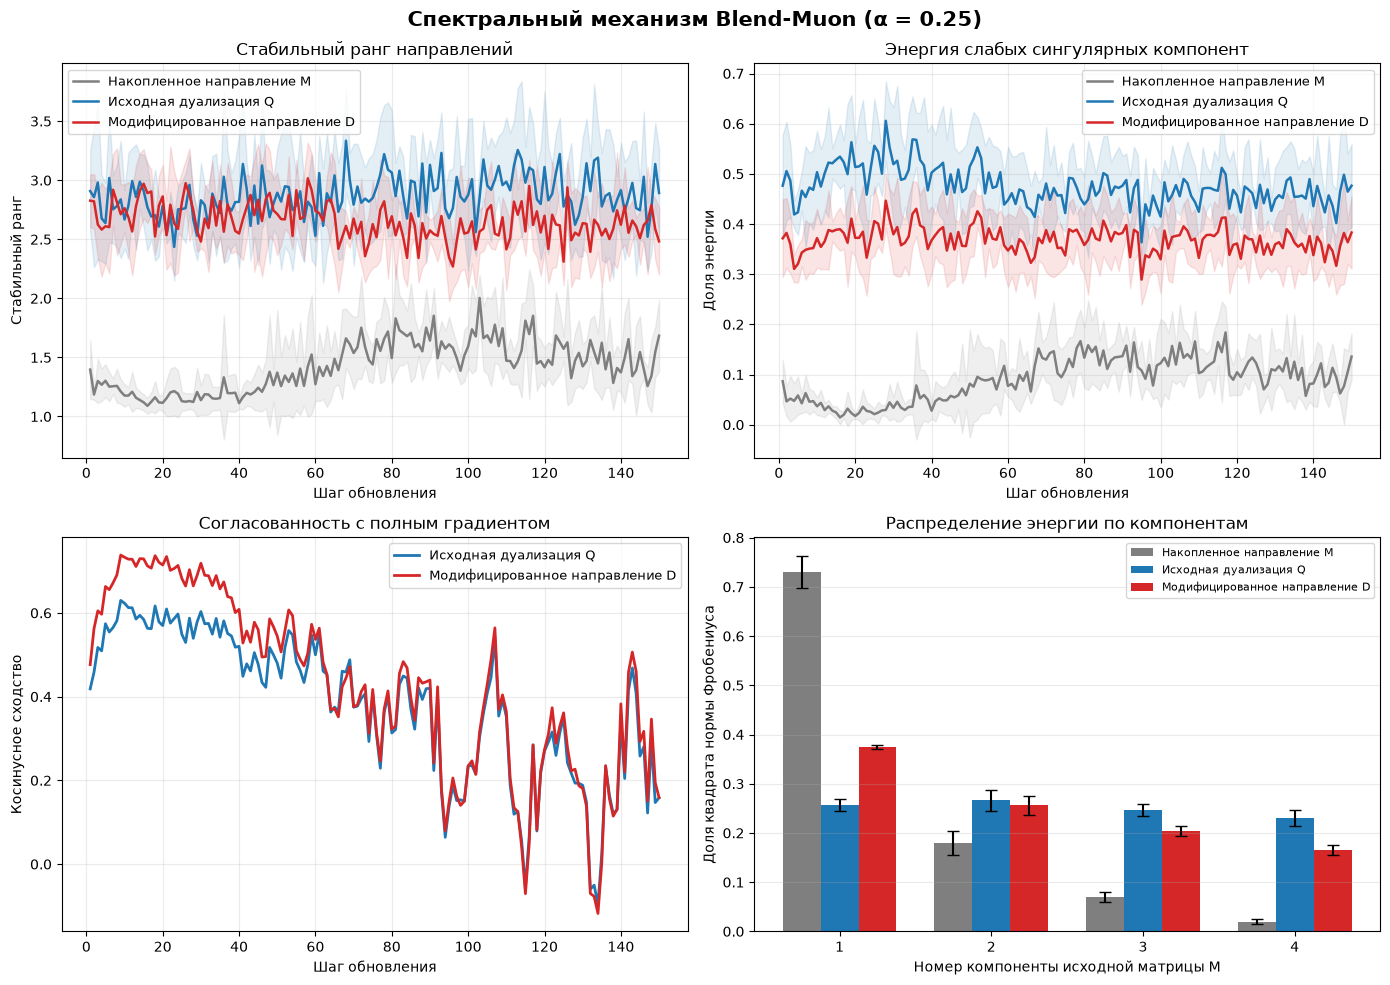


Распределение энергии по сингулярным компонентам:



Итоги исследования механизма Blend-Muon:
Выбранный alpha: 0.25
Средний стабильный ранг M: 1.42558084
Средний стабильный ранг Q: 2.87290246
Средний стабильный ранг D: 2.65593877
Относительное уменьшение стабильного ранга: 7.5521%
Энергия слабых компонент Q: 47.6014%
Энергия слабых компонент D: 36.9092%
Относительное уменьшение энергии слабых компонент: 22.4619%
Изменение сходства с накопленным направлением: +0.08024990
Изменение сходства с полным градиентом: +0.04459049
Доля шагов с улучшением сходства с полным градиентом: 76.53%
Доля шагов с ухудшением сходства с полным градиентом: 23.47%

Вычислительные затраты спектрального анализа:
Исследовано обновлений Muon: 750
Исследовано обновлений Blend-Muon: 750
Диагностических SVD: 4500
Дополнительных обратных проходов: 0
Вычислений функции потерь: 0
Обновлений параметров: 0
SVD выполнялось после завершения обучения.
Диагностические SVD не входят в стоимость оптимизаторов.
Тестовая выборка для оценки моделей не использовалась.


In [11]:
# =============================================
# Анализ спектрального механизма Blend-Muon
# =============================================

spectral_analysis_records = []

spectral_component_records = []

diagnostic_svd_calls = 0


def stable_rank_from_spectrum(singular_values):

    maximum = singular_values.max().item()

    if maximum == 0:
        return 0.0

    return (
        singular_values.square().sum()
        / maximum ** 2
    ).item()


def weak_component_share(coefficients):

    energy = coefficients.square().sum().item()

    if energy == 0:
        return np.nan

    # Доля энергии двух слабейших компонент
    # исходного накопленного направления
    return (
        coefficients[-2:].square().sum().item()
        / energy
    )


# Ablation отдельно не анализируется:
# его матричные направления совпадают с Muon.

for method in ["Muon", "Blend-Muon"]:

    for network_seed in network_seeds:

        history = experiment_results[
            (method, network_seed)
        ]["iteration_history"]

        for previous, current in zip(
            history[:-1],
            history[1:]
        ):

            if not current["accepted"]:
                continue

            M = current["momentum_direction"]

            Q = current["dual_direction"]

            D = current["used_direction"]

            # =================================
            # Спектральные разложения
            # =================================

            U, s_M, Vh = torch.linalg.svd(
                M,
                full_matrices=False
            )

            s_Q = torch.linalg.svdvals(Q)

            s_D = torch.linalg.svdvals(D)

            diagnostic_svd_calls += 3

            # Представление Q и D в сингулярном
            # базисе исходного направления M

            Q_basis = U.T @ Q @ Vh.T

            D_basis = U.T @ D @ Vh.T

            q_coefficients = torch.diag(Q_basis)

            d_coefficients = torch.diag(D_basis)

            # Восстановление матриц в общем базисе

            Q_reconstructed = (
                U * q_coefficients
            ) @ Vh

            D_reconstructed = (
                U * d_coefficients
            ) @ Vh

            reconstruction_error_Q = torch.max(
                torch.abs(Q - Q_reconstructed)
            ).item()

            reconstruction_error_D = torch.max(
                torch.abs(D - D_reconstructed)
            ).item()

            assert reconstruction_error_Q < 1e-10

            assert reconstruction_error_D < 1e-10

            # =================================
            # Проверка формулы смешивания
            # =================================

            alpha = current["alpha"]

            norm_M = torch.linalg.matrix_norm(M)

            norm_Q = torch.linalg.matrix_norm(Q)

            norm_D = torch.linalg.matrix_norm(D)

            if alpha == 0:

                expected_coefficients = q_coefficients

            elif (
                current["blend_status"] == "Applied"
            ):

                h_coefficients = (
                    (1 - alpha) * q_coefficients
                    + alpha * (norm_Q / norm_M) * s_M
                )

                expected_coefficients = (
                    norm_Q
                    / torch.linalg.vector_norm(
                        h_coefficients
                    )
                ) * h_coefficients

            else:

                expected_coefficients = d_coefficients

            spectral_formula_error = torch.max(
                torch.abs(
                    d_coefficients
                    - expected_coefficients
                )
            ).item()

            assert spectral_formula_error < 1e-10

            norm_error = abs(
                norm_D.item() - norm_Q.item()
            )

            assert norm_error < 1e-10

            # =================================
            # Стабильный ранг
            # =================================

            rank_M = stable_rank_from_spectrum(s_M)

            rank_Q = stable_rank_from_spectrum(s_Q)

            rank_D = stable_rank_from_spectrum(s_D)

            # =================================
            # Энергия слабых компонент
            # =================================

            weak_M = weak_component_share(s_M)

            weak_Q = weak_component_share(
                q_coefficients
            )

            weak_D = weak_component_share(
                d_coefficients
            )

            # =================================
            # Согласованность направлений
            # при одинаковом входе
            # =================================

            full_G = previous[
                "full_gradient"
            ][muon_slice].reshape(
                hidden_size,
                input_size
            )

            cosine_Q_M = matrix_cosine(Q, M)

            cosine_D_M = matrix_cosine(D, M)

            cosine_Q_G = matrix_cosine(Q, full_G)

            cosine_D_G = matrix_cosine(D, full_G)

            spectral_analysis_records.append({
                "method": method,
                "seed": network_seed,
                "iteration": current["iteration"],
                "batch_size": current["batch_size"],

                "rank_M": rank_M,
                "rank_Q": rank_Q,
                "rank_D": rank_D,

                "rank_change": rank_D - rank_Q,

                "weak_M": weak_M,
                "weak_Q": weak_Q,
                "weak_D": weak_D,

                "weak_share_change": weak_D - weak_Q,

                "cosine_Q_M": cosine_Q_M,
                "cosine_D_M": cosine_D_M,

                "momentum_alignment_change": (
                    cosine_D_M - cosine_Q_M
                ),

                "cosine_Q_G": cosine_Q_G,
                "cosine_D_G": cosine_D_G,

                "full_alignment_change": (
                    cosine_D_G - cosine_Q_G
                ),

                "cosine_Q_D": matrix_cosine(Q, D),

                "norm_Q": norm_Q.item(),
                "norm_D": norm_D.item(),

                "norm_error": norm_error,

                "spectral_formula_error": (
                    spectral_formula_error
                ),

                "reconstruction_error_Q": (
                    reconstruction_error_Q
                ),

                "reconstruction_error_D": (
                    reconstruction_error_D
                )
            })

            # Сохраняем компоненты в порядке
            # сингулярных значений исходной M

            for j in range(input_size):

                spectral_component_records.append({
                    "method": method,
                    "seed": network_seed,
                    "iteration": current["iteration"],
                    "component": j + 1,

                    "M": (
                        s_M[j].square()
                        / s_M.square().sum()
                    ).item(),

                    "Q": (
                        q_coefficients[j].square()
                        / q_coefficients.square().sum()
                    ).item(),

                    "D": (
                        d_coefficients[j].square()
                        / d_coefficients.square().sum()
                    ).item()
                })


spectral_analysis_df = pd.DataFrame(
    spectral_analysis_records
)

spectral_component_df = pd.DataFrame(
    spectral_component_records
)

blend_spectral_df = spectral_analysis_df[
    spectral_analysis_df["method"] == "Blend-Muon"
].copy()

muon_spectral_df = spectral_analysis_df[
    spectral_analysis_df["method"] == "Muon"
].copy()

assert len(blend_spectral_df) == 750

assert len(muon_spectral_df) == 750

assert len(spectral_component_df) == 6000

assert diagnostic_svd_calls == 4500


# =============================================
# Проверка математических свойств
# =============================================

assert (
    muon_spectral_df["rank_change"] == 0
).all()

assert (
    muon_spectral_df["weak_share_change"] == 0
).all()

assert (
    muon_spectral_df["full_alignment_change"] == 0
).all()

# Смешивание приближает направление D
# к исходному накопленному направлению M

assert (
    blend_spectral_df["momentum_alignment_change"]
    >= -1e-12
).all()

print("Проверка спектральных свойств:")

print(
    "Максимальная ошибка спектральной формулы:",
    f"{spectral_analysis_df['spectral_formula_error'].max():.8e}"
)

print(
    "Максимальная ошибка сохранения нормы:",
    f"{spectral_analysis_df['norm_error'].max():.8e}"
)

print(
    "Максимальная ошибка восстановления Q:",
    f"{spectral_analysis_df['reconstruction_error_Q'].max():.8e}"
)

print(
    "Максимальная ошибка восстановления D:",
    f"{spectral_analysis_df['reconstruction_error_D'].max():.8e}"
)


# =============================================
# Сравнение направлений при одинаковой M
# =============================================

mechanism_metrics = {
    "rank_M": "Стабильный ранг M",

    "rank_Q": "Стабильный ранг Q",

    "rank_D": "Стабильный ранг D",

    "rank_change": "Изменение стабильного ранга",

    "weak_M": "Доля энергии слабых компонент M",

    "weak_Q": "Доля энергии слабых компонент Q",

    "weak_D": "Доля энергии слабых компонент D",

    "weak_share_change": "Изменение доли слабых компонент",

    "cosine_Q_M": "Сходство Q с накопленным направлением",

    "cosine_D_M": "Сходство D с накопленным направлением",

    "momentum_alignment_change": (
        "Изменение сходства с накопленным направлением"
    ),

    "cosine_Q_G": "Сходство Q с полным градиентом",

    "cosine_D_G": "Сходство D с полным градиентом",

    "full_alignment_change": (
        "Изменение сходства с полным градиентом"
    ),

    "cosine_Q_D": "Сходство Q и D",

    "norm_Q": "Норма Q",

    "norm_D": "Норма D"
}

# Сначала усреднение внутри каждого повтора,
# затем среднее и std по пяти повторам

mechanism_per_seed = (
    blend_spectral_df
    .groupby("seed")[list(mechanism_metrics)]
    .mean()
)

mechanism_summary = (
    mechanism_per_seed
    .agg(["mean", "std"])
    .T
    .rename(index=mechanism_metrics)
)

print(
    "\nВлияние смешивания при одинаковом "
    "входном направлении M:"
)

display(
    mechanism_summary
    .rename(columns={
        "mean": "Среднее",
        "std": "Стандартное отклонение"
    })
    .style.format(precision=8)
)


# =============================================
# Частота проявления эффектов модификации
# =============================================

tolerance = 1e-12

effect_records = []

for network_seed, subset in (
    blend_spectral_df.groupby("seed")
):

    effect_records.append({
        "seed": network_seed,

        "rank_reduction_share": (
            subset["rank_change"] < -tolerance
        ).mean(),

        "weak_share_reduction": (
            subset["weak_share_change"] < -tolerance
        ).mean(),

        "momentum_alignment_improvement": (
            subset["momentum_alignment_change"] > tolerance
        ).mean(),

        "full_alignment_improvement": (
            subset["full_alignment_change"] > tolerance
        ).mean(),

        "full_alignment_deterioration": (
            subset["full_alignment_change"] < -tolerance
        ).mean(),

        "full_descent_Q": (
            subset["cosine_Q_G"] > 0
        ).mean(),

        "full_descent_D": (
            subset["cosine_D_G"] > 0
        ).mean()
    })

mechanism_effect_df = pd.DataFrame(effect_records)

effect_labels = {
    "rank_reduction_share": "Уменьшение стабильного ранга",

    "weak_share_reduction": "Уменьшение энергии слабых компонент",

    "momentum_alignment_improvement": (
        "Улучшение сходства с накопленным направлением"
    ),

    "full_alignment_improvement": (
        "Улучшение сходства с полным градиентом"
    ),

    "full_alignment_deterioration": (
        "Ухудшение сходства с полным градиентом"
    ),

    "full_descent_Q": "Доля направлений спуска Q",

    "full_descent_D": "Доля направлений спуска D"
}

print("\nЧастота проявления эффектов по пяти повторам:")

display(
    mechanism_effect_df
    .drop(columns="seed")
    .agg(["mean", "std"])
    .T
    .rename(index=effect_labels)
    .rename(columns={
        "mean": "Среднее",
        "std": "Стандартное отклонение"
    })
    .style.format("{:.2%}")
)


# =============================================
# Сравнение фактических траекторий
# =============================================

trajectory_spectral_per_seed = (
    spectral_analysis_df
    .groupby(["method", "seed"])[
        [
            "rank_M",
            "rank_Q",
            "rank_D",
            "weak_D",
            "cosine_D_M",
            "cosine_D_G"
        ]
    ]
    .mean()
    .reset_index()
)

trajectory_spectral_summary = (
    trajectory_spectral_per_seed
    .groupby("method")[
        [
            "rank_M",
            "rank_Q",
            "rank_D",
            "weak_D",
            "cosine_D_M",
            "cosine_D_G"
        ]
    ]
    .agg(["mean", "std"])
)

print("\nСпектральные характеристики фактических траекторий:")

display(
    trajectory_spectral_summary
    .style.format(precision=8)
)


# =============================================
# Влияние размера мини-батча
# =============================================

batch_mechanism_stats = (
    blend_spectral_df
    .groupby("batch_size")
    .agg(
        count=("iteration", "count"),

        rank_change=("rank_change", "mean"),

        weak_share_change=(
            "weak_share_change", "mean"
        ),

        momentum_alignment_change=(
            "momentum_alignment_change", "mean"
        ),

        full_alignment_change=(
            "full_alignment_change", "mean"
        )
    )
)

print("\nВлияние размера батча на механизм смешивания:")

display(
    batch_mechanism_stats
    .style.format(precision=8)
)


# =============================================
# Динамика матричных характеристик
# =============================================

mechanism_trajectory = (
    blend_spectral_df
    .groupby("iteration")[
        [
            "rank_M",
            "rank_Q",
            "rank_D",
            "weak_M",
            "weak_Q",
            "weak_D",
            "cosine_Q_G",
            "cosine_D_G"
        ]
    ]
    .agg(["mean", "std"])
)

direction_colors = {
    "M": "#7f7f7f",
    "Q": "#1f77b4",
    "D": "#d62728"
}

direction_labels = {
    "M": "Накопленное направление M",
    "Q": "Исходная дуализация Q",
    "D": "Модифицированное направление D"
}


fig, axes = plt.subplots(
    2, 2,
    figsize=(14, 10)
)

plot_settings = [
    (
        axes[0, 0],
        "rank",
        "Стабильный ранг направлений",
        "Стабильный ранг"
    ),

    (
        axes[0, 1],
        "weak",
        "Энергия слабых сингулярных компонент",
        "Доля энергии"
    )
]

for ax, prefix, title, ylabel in plot_settings:

    for direction in ["M", "Q", "D"]:

        metric = f"{prefix}_{direction}"

        stats = mechanism_trajectory[metric]

        steps = stats.index.to_numpy()

        mean = stats["mean"].to_numpy()

        std = stats["std"].to_numpy()

        ax.plot(
            steps,
            mean,
            color=direction_colors[direction],
            linewidth=1.8,
            label=direction_labels[direction]
        )

        ax.fill_between(
            steps,
            mean - std,
            mean + std,
            color=direction_colors[direction],
            alpha=0.12
        )

    ax.set_title(title)
    ax.set_xlabel("Шаг обновления")
    ax.set_ylabel(ylabel)
    ax.grid(alpha=0.25)
    ax.legend(fontsize=9)


# Согласованность Q и D с полным градиентом

for direction in ["Q", "D"]:

    metric = f"cosine_{direction}_G"

    stats = mechanism_trajectory[metric]

    axes[1, 0].plot(
        stats.index,
        stats["mean"],
        color=direction_colors[direction],
        linewidth=2,
        label=direction_labels[direction]
    )

axes[1, 0].set_title(
    "Согласованность с полным градиентом"
)

axes[1, 0].set_xlabel("Шаг обновления")

axes[1, 0].set_ylabel("Косинусное сходство")

axes[1, 0].grid(alpha=0.25)

axes[1, 0].legend(fontsize=9)


# =============================================
# Распределение энергии по компонентам
# =============================================

component_per_seed = (
    spectral_component_df[
        spectral_component_df["method"] == "Blend-Muon"
    ]
    .groupby(["seed", "component"])[
        ["M", "Q", "D"]
    ]
    .mean()
    .reset_index()
)

component_stats = (
    component_per_seed
    .groupby("component")[["M", "Q", "D"]]
    .agg(["mean", "std"])
)

positions = np.arange(1, input_size + 1)

width = 0.25

for offset, direction in zip(
    [-width, 0, width],
    ["M", "Q", "D"]
):

    axes[1, 1].bar(
        positions + offset,

        component_stats[(direction, "mean")],

        width=width,

        yerr=component_stats[(direction, "std")],

        capsize=4,

        color=direction_colors[direction],

        label=direction_labels[direction]
    )

axes[1, 1].set_title(
    "Распределение энергии по компонентам"
)

axes[1, 1].set_xlabel(
    "Номер компоненты исходной матрицы M"
)

axes[1, 1].set_ylabel(
    "Доля квадрата нормы Фробениуса"
)

axes[1, 1].set_xticks(positions)

axes[1, 1].legend(fontsize=8)

axes[1, 1].grid(axis="y", alpha=0.25)

fig.suptitle(
    f"Спектральный механизм Blend-Muon (α = {selected_alpha})",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()
plt.show()


print("\nРаспределение энергии по сингулярным компонентам:")

display(
    component_stats.style.format(precision=8)
)


# =============================================
# Итоговые количественные характеристики
# =============================================

rank_reduction = (
    (
        mechanism_per_seed["rank_Q"].mean()
        - mechanism_per_seed["rank_D"].mean()
    )
    / mechanism_per_seed["rank_Q"].mean()
    * 100
)

weak_energy_reduction = (
    (
        mechanism_per_seed["weak_Q"].mean()
        - mechanism_per_seed["weak_D"].mean()
    )
    / mechanism_per_seed["weak_Q"].mean()
    * 100
)

print("\nИтоги исследования механизма Blend-Muon:")

print(f"Выбранный alpha: {selected_alpha:.2f}")

print(
    "Средний стабильный ранг M:",
    f"{mechanism_per_seed['rank_M'].mean():.8f}"
)

print(
    "Средний стабильный ранг Q:",
    f"{mechanism_per_seed['rank_Q'].mean():.8f}"
)

print(
    "Средний стабильный ранг D:",
    f"{mechanism_per_seed['rank_D'].mean():.8f}"
)

print(
    "Относительное уменьшение стабильного ранга:",
    f"{rank_reduction:.4f}%"
)

print(
    "Энергия слабых компонент Q:",
    f"{mechanism_per_seed['weak_Q'].mean():.4%}"
)

print(
    "Энергия слабых компонент D:",
    f"{mechanism_per_seed['weak_D'].mean():.4%}"
)

print(
    "Относительное уменьшение энергии слабых компонент:",
    f"{weak_energy_reduction:.4f}%"
)

print(
    "Изменение сходства с накопленным направлением:",
    f"{mechanism_per_seed['momentum_alignment_change'].mean():+.8f}"
)

print(
    "Изменение сходства с полным градиентом:",
    f"{mechanism_per_seed['full_alignment_change'].mean():+.8f}"
)

print(
    "Доля шагов с улучшением сходства с полным градиентом:",
    f"{mechanism_effect_df['full_alignment_improvement'].mean():.2%}"
)

print(
    "Доля шагов с ухудшением сходства с полным градиентом:",
    f"{mechanism_effect_df['full_alignment_deterioration'].mean():.2%}"
)


# =============================================
# Стоимость дополнительного анализа
# =============================================

print("\nВычислительные затраты спектрального анализа:")

print(
    "Исследовано обновлений Muon:",
    len(muon_spectral_df)
)

print(
    "Исследовано обновлений Blend-Muon:",
    len(blend_spectral_df)
)

print(
    "Диагностических SVD:",
    diagnostic_svd_calls
)

print("Дополнительных обратных проходов: 0")

print("Вычислений функции потерь: 0")

print("Обновлений параметров: 0")

print("SVD выполнялось после завершения обучения.")

print("Диагностические SVD не входят в стоимость оптимизаторов.")

print("Тестовая выборка для оценки моделей не использовалась.")

Средняя вычислительная стоимость одного запуска:


method,Muon,Blend-Muon,Ablation
Основные вычисления функции потерь,150,150,150
Основные обратные проходы,150,150,150
Диагностические обратные проходы,151,151,151
Вычисления Validation loss,151,151,151
Всего вычислений функции потерь,452,452,452
Всего обратных проходов,301,301,301
Обработано обучающих наблюдений,4672,4672,4672
Вызовы матричной дуализации,150,150,150
Итерации Ньютона — Шульца,750,750,750
Матричные умножения NS,2250,2250,2250



Аналитическое количество скалярных операций
на одно матричное преобразование:


Операция,Muon,Blend-Muon,Ablation
Умножения,2320,2600,2320
Сложения,1880,2037,1880
Вычитания,0,1,0
Деления,40,42,40
Квадратные корни,1,4,1
Всего,4241,4684,4241


Дополнительных скалярных операций Blend-Muon: 443
Дополнительных операций за 150 шагов: 66450
Относительное увеличение числа операций: 10.4456%
Оценка не включает обратное распространение, обновление импульса и AdamW.

Измеренные ресурсы: среднее ± std


Показатель,Muon,Blend-Muon,Ablation
"Время оптимизации, мс",76.381679 ± 6.778245,81.351240 ± 2.336922,76.316860 ± 2.903365
"Время с диагностикой, мс",151.802480 ± 8.346127,168.294280 ± 7.411779,154.221340 ± 4.475615
"Пиковая память PyTorch, КиБ",11.398438 ± 0.000000,11.398438 ± 0.000000,11.398438 ± 0.000000
"Пиковая память Python, КиБ",37.902930 ± 0.087381,37.839844 ± 0.057617,37.718555 ± 0.063116
Количество выделений памяти PyTorch,21159.000000 ± 0.000000,25209.000000 ± 0.000000,21159.000000 ± 0.000000
"Суммарно выделено PyTorch, байт",4940862.000000 ± 0.000000,5197812.000000 ± 0.000000,4940862.000000 ± 0.000000
"Постоянное числовое состояние, байт",656.000000 ± 0.000000,656.000000 ± 0.000000,656.000000 ± 0.000000



Дополнительная стоимость Blend-Muon:


Показатель,Muon,Blend-Muon,Абсолютная разность,"Относительная разность, %"
"Время оптимизации, мс",76.381679,81.351240,4.969561,6.506221
"Время с диагностикой, мс",151.802480,168.294280,16.491800,10.863986
"Пиковая память PyTorch, КиБ",11.398438,11.398438,0.000000,0.000000
"Пиковая память Python, КиБ",37.902930,37.839844,-0.063086,-0.166441
Количество выделений памяти PyTorch,21159.000000,25209.000000,4050.000000,19.140791
"Суммарно выделено PyTorch, байт",4940862.000000,5197812.000000,256950.000000,5.200510
"Постоянное числовое состояние, байт",656.000000,656.000000,0.000000,0.000000



Среднее время одного обновления, мс:


,mean,std
method,,
Muon,0.50921120,0.04518830
Blend-Muon,0.54234160,0.01557948
Ablation,0.50877907,0.01935577


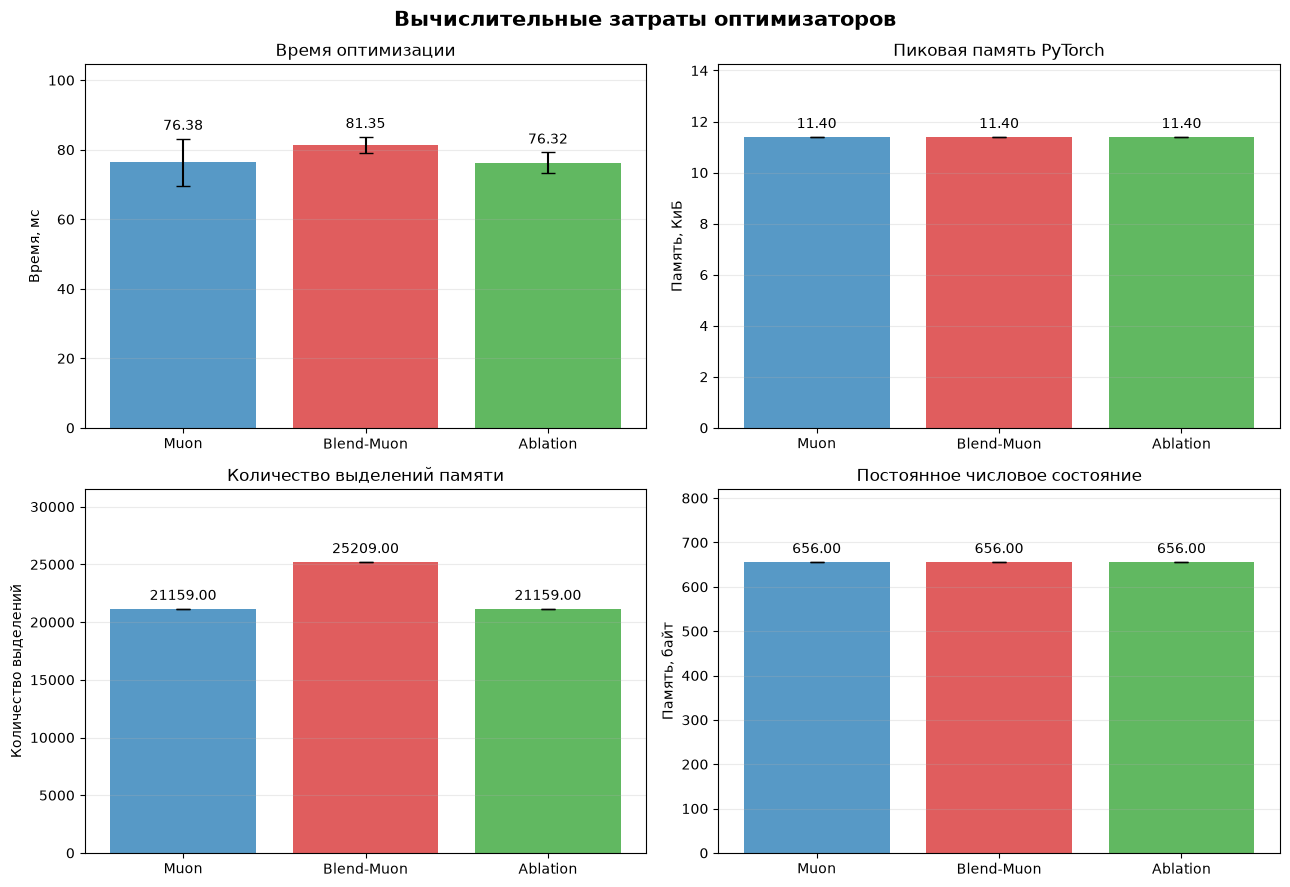

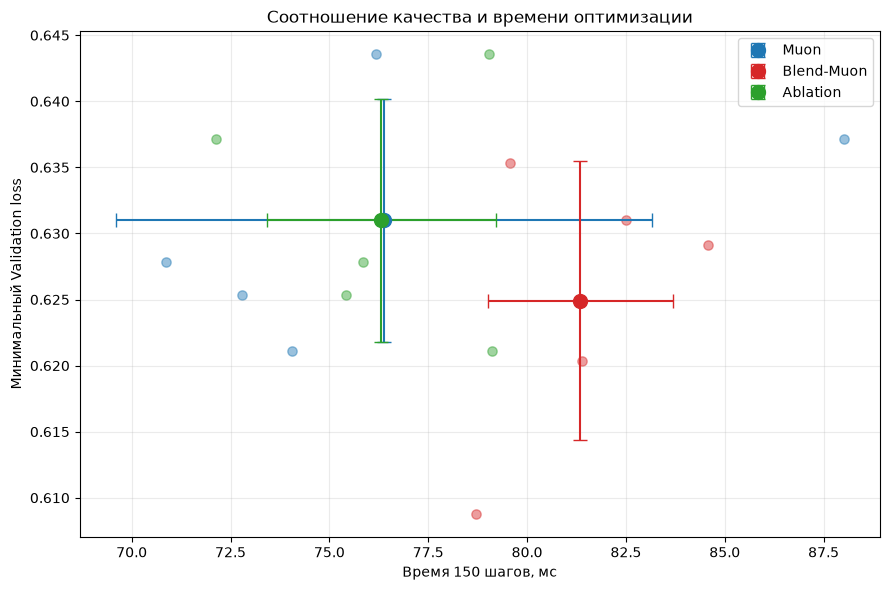


Вычислительный бюджет исследования:


Этап,Запусков,Попыток обновления,Основных обратных проходов,Диагностических обратных проходов,Диагностических SVD
Подбор alpha,15,2250,2250,2265,0
Основной эксперимент,15,2250,2250,2265,0
Измерительные воспроизведения,90,13500,13500,0,0
Спектральный анализ,0,0,0,0,4500
Всего без предварительных проверок,120,18000,18000,4530,4500



Итоги вычислительного анализа:
Увеличение среднего времени оптимизации: 6.5062%
Увеличение количества выделений памяти: 19.1408%
Дополнительное постоянное состояние: 0 байт
Дополнительные матричные умножения: 0
Дополнительные обратные проходы: 0
Дополнительные SVD внутри алгоритма: 0
Относительное улучшение основного валидационного критерия: 0.9611%

Все проверки вычислительных затрат пройдены.
Стоимость подбора alpha учтена отдельно.
Диагностические операции не включены в стоимость обновлений.
Тестовая выборка для оценки моделей не использовалась.


In [12]:
# =============================================
# Вычислительная стоимость одного запуска
# =============================================

cost_metrics = {
    "batch_loss_calls": "Основные вычисления функции потерь",
    "batch_gradient_calls": "Основные обратные проходы",
    "full_gradient_calls": "Диагностические обратные проходы",
    "validation_loss_calls": "Вычисления Validation loss",
    "total_loss_calls": "Всего вычислений функции потерь",
    "total_backward_calls": "Всего обратных проходов",
    "processed_samples": "Обработано обучающих наблюдений",
    "ns_calls": "Вызовы матричной дуализации",
    "ns_iterations": "Итерации Ньютона — Шульца",
    "ns_matmuls": "Матричные умножения NS",
    "ns_norm_calls": "Нормы при дуализации",
    "blend_calls": "Дополнительные смешивания",
    "blend_norm_calls": "Дополнительные нормы",
    "blend_matrix_scales": "Дополнительные масштабирования",
    "blend_matrix_additions": "Дополнительные сложения",
    "blend_fallbacks": "Резервные переходы",
    "hessian_calls": "Вычисления гессиана",
    "jacobian_calls": "Вычисления матрицы Якоби",
    "curvature_builds": "Построения матриц кривизны",
    "factorizations": "Матричные факторизации",
    "linear_system_solves": "Решения линейных систем",
    "svd_calls": "SVD при обучении"
}

operation_summary = (
    experiment_df
    .groupby("method", observed=True)[list(cost_metrics)]
    .mean()
    .reindex(methods)
    .T
    .rename(index=cost_metrics)
)

print("Средняя вычислительная стоимость одного запуска:")

display(
    operation_summary.style.format("{:.0f}")
)


# =============================================
# Аналитическая оценка сложности
# =============================================

# После транспонирования M имеет размерность 4×10.
# Промежуточная матрица A имеет размерность 4×4.

r = min(hidden_size, input_size)
c = max(hidden_size, input_size)

matrix_elements = r * c

# Одно матричное умножение X @ X.T
xx_multiplications = r * r * c
xx_additions = r * r * (c - 1)

# Одно матричное умножение A @ A
aa_multiplications = r * r * r
aa_additions = r * r * (r - 1)

# Одно матричное умножение B @ X
bx_multiplications = r * c * r
bx_additions = r * c * (r - 1)

# Скалярные операции внутри одной итерации NS
ns_matmul_multiplications = (
    xx_multiplications
    + aa_multiplications
    + bx_multiplications
)

ns_matmul_additions = (
    xx_additions
    + aa_additions
    + bx_additions
)

# B = b*A + c*A²
# X_new = a*X + B@X

ns_elementwise_multiplications = (
    2 * r * r + r * c
)

ns_elementwise_additions = (
    r * r + r * c
)

ns_steps = muon_config["ns_steps"]

ns_multiplications = ns_steps * (
    ns_matmul_multiplications
    + ns_elementwise_multiplications
)

ns_additions = ns_steps * (
    ns_matmul_additions
    + ns_elementwise_additions
)

# Нормализация X / (||X||_F + eps)

ns_multiplications += matrix_elements

ns_additions += matrix_elements - 1

ns_additions += 1

ns_divisions = matrix_elements

ns_square_roots = 1


# =============================================
# Дополнительные операции Blend-Muon
# =============================================

# Три нормы Фробениуса:
# ||M||_F, ||Q||_F, ||H||_F

blend_norm_multiplications = 3 * matrix_elements

blend_norm_additions = 3 * (
    matrix_elements - 1
)

# Четыре масштабирования матриц
blend_scaling_multiplications = (
    4 * matrix_elements
)

# Одно сложение матриц
blend_matrix_additions = matrix_elements

blend_multiplications = (
    blend_norm_multiplications
    + blend_scaling_multiplications
)

blend_additions = (
    blend_norm_additions
    + blend_matrix_additions
)

blend_subtractions = 1

blend_divisions = 2

blend_square_roots = 3

# Суммарная аналитическая оценка
# операций только матричного преобразования

ns_total_operations = (
    ns_multiplications
    + ns_additions
    + ns_divisions
    + ns_square_roots
)

blend_extra_operations = (
    blend_multiplications
    + blend_additions
    + blend_subtractions
    + blend_divisions
    + blend_square_roots
)

analytical_cost_df = pd.DataFrame({
    "Операция": [
        "Умножения",
        "Сложения",
        "Вычитания",
        "Деления",
        "Квадратные корни",
        "Всего"
    ],

    "Muon": [
        ns_multiplications,
        ns_additions,
        0,
        ns_divisions,
        ns_square_roots,
        ns_total_operations
    ],

    "Blend-Muon": [
        ns_multiplications + blend_multiplications,
        ns_additions + blend_additions,
        blend_subtractions,
        ns_divisions + blend_divisions,
        ns_square_roots + blend_square_roots,
        ns_total_operations + blend_extra_operations
    ],

    "Ablation": [
        ns_multiplications,
        ns_additions,
        0,
        ns_divisions,
        ns_square_roots,
        ns_total_operations
    ]
})

print("\nАналитическое количество скалярных операций")
print("на одно матричное преобразование:")

display(
    analytical_cost_df.style.hide(axis="index")
)

analytical_overhead = (
    blend_extra_operations
    / ns_total_operations
    * 100
)

print(
    "Дополнительных скалярных операций Blend-Muon:",
    blend_extra_operations
)

print(
    "Дополнительных операций за 150 шагов:",
    blend_extra_operations * iterations
)

print(
    "Относительное увеличение числа операций:",
    f"{analytical_overhead:.4f}%"
)

print(
    "Оценка не включает обратное распространение, "
    "обновление импульса и AdamW."
)


# =============================================
# Измеренные время и память
# =============================================

resource_metrics = {
    "core_time_ms": "Время оптимизации, мс",
    "total_time_ms": "Время с диагностикой, мс",
    "torch_peak_memory_kib": "Пиковая память PyTorch, КиБ",
    "python_peak_memory_kib": "Пиковая память Python, КиБ",
    "torch_allocations": "Количество выделений памяти PyTorch",
    "torch_total_allocated_bytes": "Суммарно выделено PyTorch, байт",
    "state_bytes": "Постоянное числовое состояние, байт"
}

resource_summary = (
    experiment_df
    .groupby("method", observed=True)[
        list(resource_metrics)
    ]
    .agg(["mean", "std"])
    .reindex(methods)
)

resource_records = []

for metric, label in resource_metrics.items():

    row = {"Показатель": label}

    for method in methods:

        mean = resource_summary.loc[
            method, (metric, "mean")
        ]

        std = resource_summary.loc[
            method, (metric, "std")
        ]

        row[method] = f"{mean:.6f} ± {std:.6f}"

    resource_records.append(row)

resource_summary_df = pd.DataFrame(
    resource_records
)

print("\nИзмеренные ресурсы: среднее ± std")

display(
    resource_summary_df.style.hide(axis="index")
)


# =============================================
# Относительная стоимость модификации
# =============================================

resource_difference_records = []

for metric, label in resource_metrics.items():

    original = resource_summary.loc[
        "Muon", (metric, "mean")
    ]

    modified = resource_summary.loc[
        "Blend-Muon", (metric, "mean")
    ]

    relative_difference = (
        (modified - original)
        / original * 100
        if original != 0
        else np.nan
    )

    resource_difference_records.append({
        "Показатель": label,
        "Muon": original,
        "Blend-Muon": modified,
        "Абсолютная разность": modified - original,
        "Относительная разность, %": relative_difference
    })

resource_difference_df = pd.DataFrame(
    resource_difference_records
)

print("\nДополнительная стоимость Blend-Muon:")

display(
    resource_difference_df.style
    .hide(axis="index")
    .format(precision=6)
)


# =============================================
# Время одного обновления
# =============================================

experiment_df["time_per_step_ms"] = (
    experiment_df["core_time_ms"] / iterations
)

step_time_summary = (
    experiment_df
    .groupby("method", observed=True)[
        "time_per_step_ms"
    ]
    .agg(["mean", "std"])
    .reindex(methods)
)

print("\nСреднее время одного обновления, мс:")

display(
    step_time_summary.style.format(precision=8)
)


# =============================================
# Визуализация вычислительных затрат
# =============================================

fig, axes = plt.subplots(
    2, 2,
    figsize=(13, 9)
)

resource_plots = [
    (
        "core_time_ms",
        "Время оптимизации",
        "Время, мс"
    ),
    (
        "torch_peak_memory_kib",
        "Пиковая память PyTorch",
        "Память, КиБ"
    ),
    (
        "torch_allocations",
        "Количество выделений памяти",
        "Количество выделений"
    ),
    (
        "state_bytes",
        "Постоянное числовое состояние",
        "Память, байт"
    )
]

for ax, (metric, title, ylabel) in zip(
    axes.flat, resource_plots
):

    means = [
        resource_summary.loc[
            method, (metric, "mean")
        ]
        for method in methods
    ]

    stds = [
        resource_summary.loc[
            method, (metric, "std")
        ]
        for method in methods
    ]

    bars = ax.bar(
        methods,
        means,
        yerr=stds,
        capsize=5,
        color=[
            method_colors[method]
            for method in methods
        ],
        alpha=0.75
    )

    ax.bar_label(
        bars,
        fmt="%.2f",
        padding=4
    )

    ax.set_title(title)
    ax.set_ylabel(ylabel)
    ax.set_ylim(0, max(
        mean + std
        for mean, std in zip(means, stds)
    ) * 1.25)

    ax.grid(axis="y", alpha=0.25)

fig.suptitle(
    "Вычислительные затраты оптимизаторов",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()
plt.show()


# =============================================
# Соотношение качества и времени
# =============================================

fig, ax = plt.subplots(figsize=(9, 6))

for method in methods:

    subset = experiment_df[
        experiment_df["method"] == method
    ]

    ax.scatter(
        subset["core_time_ms"],
        subset["best_validation_loss"],
        color=method_colors[method],
        alpha=0.45,
        s=45
    )

    mean_time = subset["core_time_ms"].mean()

    mean_loss = subset["best_validation_loss"].mean()

    ax.errorbar(
        mean_time,
        mean_loss,
        xerr=subset["core_time_ms"].std(ddof=1),
        yerr=subset["best_validation_loss"].std(ddof=1),
        fmt="o",
        markersize=10,
        capsize=5,
        color=method_colors[method],
        label=method
    )

ax.set_title("Соотношение качества и времени оптимизации")

ax.set_xlabel("Время 150 шагов, мс")

ax.set_ylabel("Минимальный Validation loss")

ax.legend()
ax.grid(alpha=0.25)

plt.tight_layout()
plt.show()


# =============================================
# Итоговый бюджет исследования
# =============================================

research_budget_df = pd.DataFrame([
    {
        "Этап": "Подбор alpha",
        "Запусков": tuning_runs,
        "Попыток обновления": tuning_updates,
        "Основных обратных проходов": tuning_updates,
        "Диагностических обратных проходов": (
            tuning_total_counters["full_gradient_calls"]
        ),
        "Диагностических SVD": 0
    },
    {
        "Этап": "Основной эксперимент",
        "Запусков": main_runs,
        "Попыток обновления": main_updates,
        "Основных обратных проходов": main_updates,
        "Диагностических обратных проходов": (
            main_total_counters["full_gradient_calls"]
        ),
        "Диагностических SVD": 0
    },
    {
        "Этап": "Измерительные воспроизведения",
        "Запусков": measurement_runs,
        "Попыток обновления": measurement_updates,
        "Основных обратных проходов": measurement_updates,
        "Диагностических обратных проходов": 0,
        "Диагностических SVD": 0
    },
    {
        "Этап": "Спектральный анализ",
        "Запусков": 0,
        "Попыток обновления": 0,
        "Основных обратных проходов": 0,
        "Диагностических обратных проходов": 0,
        "Диагностических SVD": diagnostic_svd_calls
    }
])

budget_total = {
    "Этап": "Всего без предварительных проверок"
}

for column in research_budget_df.columns[1:]:

    budget_total[column] = research_budget_df[
        column
    ].sum()

research_budget_df = pd.concat(
    [
        research_budget_df,
        pd.DataFrame([budget_total])
    ],
    ignore_index=True
)

print("\nВычислительный бюджет исследования:")

display(
    research_budget_df.style.hide(axis="index")
)


# =============================================
# Итоговые показатели стоимости
# =============================================

muon_time = resource_summary.loc[
    "Muon", ("core_time_ms", "mean")
]

blend_time = resource_summary.loc[
    "Blend-Muon", ("core_time_ms", "mean")
]

time_overhead = (
    (blend_time - muon_time)
    / muon_time * 100
)

muon_allocations = resource_summary.loc[
    "Muon", ("torch_allocations", "mean")
]

blend_allocations = resource_summary.loc[
    "Blend-Muon", ("torch_allocations", "mean")
]

allocation_overhead = (
    (blend_allocations - muon_allocations)
    / muon_allocations * 100
)

print("\nИтоги вычислительного анализа:")

print(
    "Увеличение среднего времени оптимизации:",
    f"{time_overhead:.4f}%"
)

print(
    "Увеличение количества выделений памяти:",
    f"{allocation_overhead:.4f}%"
)

print(
    "Дополнительное постоянное состояние: 0 байт"
)

print(
    "Дополнительные матричные умножения: 0"
)

print(
    "Дополнительные обратные проходы: 0"
)

print(
    "Дополнительные SVD внутри алгоритма: 0"
)

print(
    "Относительное улучшение основного "
    "валидационного критерия:",
    f"{relative_validation_improvement:.4f}%"
)

assert (
    experiment_df["batch_gradient_calls"] == 150
).all()

assert (
    experiment_df["ns_matmuls"] == 2250
).all()

assert (
    experiment_df["state_bytes"] == 656
).all()

assert (
    experiment_df["svd_calls"] == 0
).all()

assert budget_total["Попыток обновления"] == 18000

assert budget_total["Диагностических SVD"] == 4500

print("\nВсе проверки вычислительных затрат пройдены.")

print("Стоимость подбора alpha учтена отдельно.")

print("Диагностические операции не включены в стоимость обновлений.")

print("Тестовая выборка для оценки моделей не использовалась.")

Состояния, выбранные по валидационной выборке:


Метод,Seed,Alpha,Выбранная итерация,Train loss,Validation loss
Muon,1,0.00000000,150,0.62892759,0.63712094
Muon,2,0.00000000,98,0.63450446,0.64357781
Muon,3,0.00000000,71,0.62496645,0.62783953
Muon,4,0.00000000,95,0.62218445,0.62109611
Muon,5,0.00000000,103,0.62722611,0.62531313
Blend-Muon,1,0.25000000,150,0.62782868,0.62913093
Blend-Muon,2,0.25000000,95,0.63237542,0.63534217
Blend-Muon,3,0.25000000,59,0.62928496,0.63099347
Blend-Muon,4,0.25000000,70,0.62679069,0.60877627
Blend-Muon,5,0.25000000,103,0.62796273,0.62038405



Итоговые результаты на тестовой выборке:


Метод,Seed,Alpha,Выбранный шаг,Validation loss,Test BCE,Accuracy,F1-macro,ROC-AUC,TN,FP,FN,TP
Muon,1,0.00000000,150,0.63712094,0.62182486,0.67500000,0.67443478,0.72027778,38,22,17,43
Muon,2,0.00000000,98,0.64357781,0.64096194,0.66666667,0.66629588,0.70583333,42,18,22,38
Muon,3,0.00000000,71,0.62783953,0.62867982,0.65833333,0.65773913,0.70500000,37,23,18,42
Muon,4,0.00000000,95,0.62109611,0.62982375,0.65833333,0.65811966,0.70194444,38,22,19,41
Muon,5,0.00000000,103,0.62531313,0.63337683,0.64166667,0.64144257,0.70944444,37,23,20,40
Blend-Muon,1,0.25000000,150,0.62913093,0.63219966,0.65000000,0.64961068,0.70416667,37,23,19,41
Blend-Muon,2,0.25000000,95,0.63534217,0.64013069,0.65833333,0.65773913,0.69027778,42,18,23,37
Blend-Muon,3,0.25000000,59,0.63099347,0.63383379,0.66666667,0.66517857,0.70638889,36,24,16,44
Blend-Muon,4,0.25000000,70,0.60877627,0.63063828,0.64166667,0.64164178,0.69722222,38,22,21,39
Blend-Muon,5,0.25000000,103,0.62038405,0.62437278,0.65833333,0.65773913,0.72333333,42,18,23,37



Тестовые метрики: среднее ± выборочное std


Показатель,Muon,Blend-Muon,Ablation
Test BCE,0.63093344 ± 0.00699674,0.63223504 ± 0.00568470,0.63093344 ± 0.00699674
Accuracy,0.66000000 ± 0.01236033,0.65500000 ± 0.00950146,0.66000000 ± 0.01236033
F1-macro,0.65960640 ± 0.01225002,0.65438186 ± 0.00900257,0.65960640 ± 0.01225002
ROC-AUC,0.70850000 ± 0.00710536,0.70427778 ± 0.01238310,0.70850000 ± 0.00710536



Парные различия тестовых метрик:


Показатель,Среднее Blend - Muon,Std разности,Blend лучше,Blend хуже,Совпадений
Test BCE,0.00130160,0.00721381,2,3,0
Accuracy,-0.00500000,0.01728037,2,3,0
F1-macro,-0.00522455,0.01692202,2,3,0
ROC-AUC,-0.00422222,0.01254529,2,3,0



Muon и Ablation полностью совпадают на Test.

Ориентиры качества на тестовой выборке:


Показатель,Значение
BCE при постоянной вероятности 0.5,0.69314718
Минимальная ожидаемая BCE,0.63935844
Ожидаемая байесовская Accuracy,0.63565587
Эмпирическая BCE истинной функции,0.61508272
Эмпирическая Accuracy истинной функции,0.66666667
Эмпирическая F1-macro истинной функции,0.66666667
Эмпирическая ROC-AUC истинной функции,0.72583333


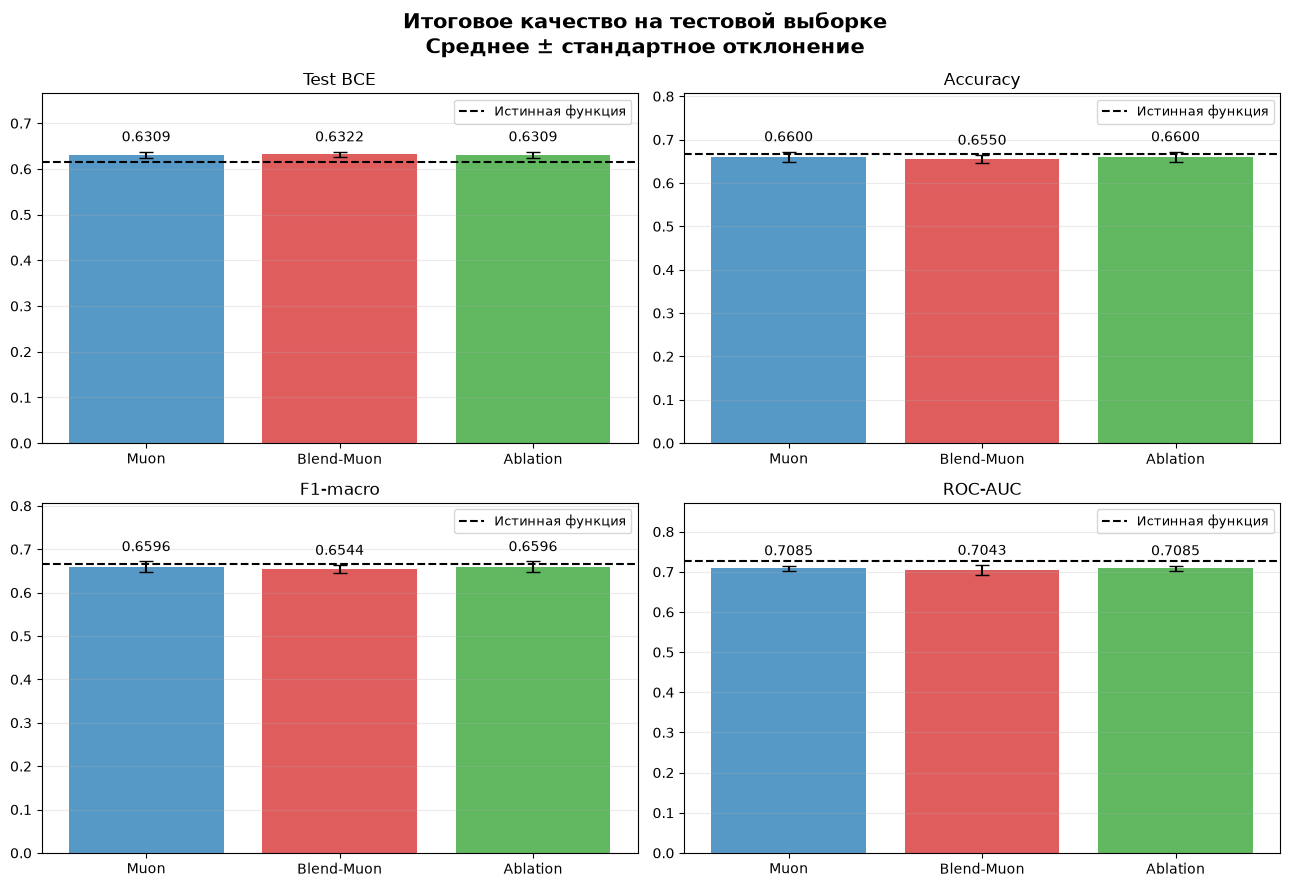


Тестовая BCE по общим seed:


method,Ablation,Blend-Muon,Muon,Blend - Muon
seed,,,,
1,0.62182486,0.63219966,0.62182486,0.01037480
2,0.64096194,0.64013069,0.64096194,-0.00083125
3,0.62867982,0.63383379,0.62867982,0.00515397
4,0.62982375,0.63063828,0.62982375,0.00081453
5,0.63337683,0.62437278,0.63337683,-0.00900404


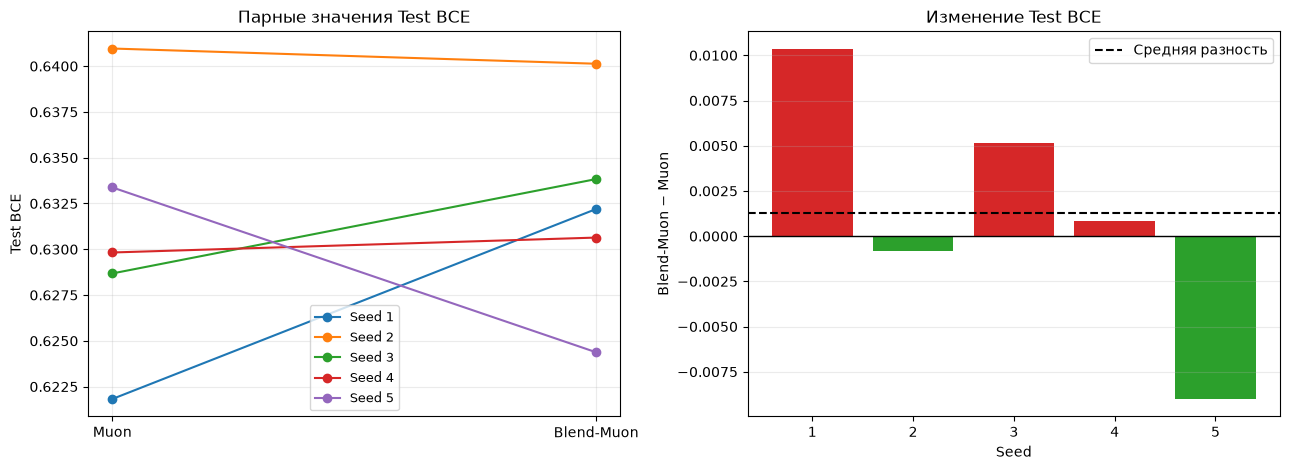

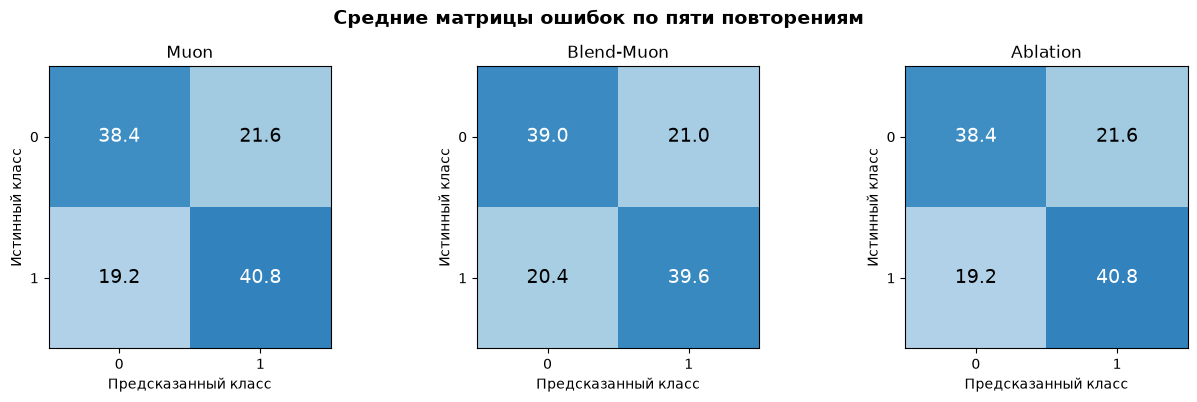


Итоговая сравнительная таблица:


Метод,Alpha,Средний выбранный шаг,Validation BCE,Test BCE,Test Accuracy,Test F1-macro,Test ROC-AUC,"Время оптимизации, мс","Память состояния, байт"
Muon,0.00000000,103.40000000,0.63098950,0.63093344,0.66000000,0.65960640,0.70850000,76.38167939,656
Blend-Muon,0.25000000,95.40000000,0.62492538,0.63223504,0.65500000,0.65438186,0.70427778,81.35123998,656
Ablation,0.00000000,103.40000000,0.63098950,0.63093344,0.66000000,0.65960640,0.70850000,76.31685990,656



Итоговые результаты исследования:
Улучшение минимального Validation loss: +0.9611%
Улучшение Test BCE: -0.2063%
Blend-Muon лучше по Test BCE: 2 из 5 повторений
Дополнительное время оптимизации: 6.5062%
Уменьшение энергии слабых компонент: 22.4619%
Дополнительное постоянное состояние: 0 байт

Валидационное преимущество по BCE не воспроизвелось на тестовой выборке.

Все итоговые проверки пройдены.
Выполнено 15 итоговых оценок моделей на Test.
Дополнительных обратных проходов: 0.
Дополнительных обновлений параметров: 0.
Все состояния выбраны до тестовой оценки.
Коэффициент alpha после тестирования не изменялся.
Исследовательский эксперимент завершён.


In [13]:
# =============================================
# Фиксация выбранных состояний
# =============================================

selected_checkpoints = {}

checkpoint_records = []

for method in methods:

    for network_seed in network_seeds:

        result = experiment_results[
            (method, network_seed)
        ]

        history = result["iteration_history"]

        best = result["best_record"]

        assert best is not None

        # Проверка выбора исключительно по Validation
        finite_validation_losses = [
            record["validation_loss"]
            for record in history
            if record["diagnostics_finite"]
        ]

        assert (
            best["validation_loss"]
            == min(finite_validation_losses)
        )

        assert torch.equal(
            result["best_theta"],
            best["theta"]
        )

        selected_checkpoints[
            (method, network_seed)
        ] = {
            "theta": best["theta"].clone(),
            "iteration": best["iteration"],
            "validation_loss": best["validation_loss"],
            "train_loss": best["train_loss"],
            "alpha": result["alpha"]
        }

        checkpoint_records.append({
            "Метод": method,
            "Seed": network_seed,
            "Alpha": result["alpha"],
            "Выбранная итерация": best["iteration"],
            "Train loss": best["train_loss"],
            "Validation loss": best["validation_loss"]
        })

checkpoint_df = pd.DataFrame(checkpoint_records)

assert len(selected_checkpoints) == 15

print("Состояния, выбранные по валидационной выборке:")

display(
    checkpoint_df.style
    .hide(axis="index")
    .format(precision=8)
)


# =============================================
# Функция итоговой оценки классификации
# =============================================

@torch.no_grad()
def evaluate_classification(theta, X_data, y_data):

    logits = forward_logits(theta, X_data)

    probabilities = torch.sigmoid(logits)

    predictions = (
        probabilities >= classification_threshold
    ).to(torch.int64)

    targets = (
        y_data.numpy()
        .ravel()
        .astype(int)
    )

    probabilities_np = (
        probabilities.numpy().ravel()
    )

    predictions_np = (
        predictions.numpy().ravel()
    )

    assert np.isfinite(probabilities_np).all()

    assert np.all(
        (probabilities_np >= 0)
        & (probabilities_np <= 1)
    )

    loss = loss_function(
        logits,
        y_data
    ).item()

    accuracy = accuracy_score(
        targets,
        predictions_np
    )

    f1_macro = f1_score(
        targets,
        predictions_np,
        average="macro",
        zero_division=0
    )

    roc_auc = roc_auc_score(
        targets,
        probabilities_np
    )

    cm = confusion_matrix(
        targets,
        predictions_np,
        labels=[0, 1]
    )

    tn, fp, fn, tp = cm.ravel()

    assert cm.sum() == len(targets)

    assert np.isclose(
        accuracy,
        (tn + tp) / len(targets)
    )

    return {
        "loss": loss,
        "accuracy": accuracy,
        "f1_macro": f1_macro,
        "roc_auc": roc_auc,
        "confusion_matrix": cm,
        "probabilities": probabilities_np,
        "predictions": predictions_np,
        "tn": int(tn),
        "fp": int(fp),
        "fn": int(fn),
        "tp": int(tp)
    }


# =============================================
# Итоговая оценка на Test
# =============================================

test_results = {}

test_records = []

for method in methods:

    for network_seed in network_seeds:

        checkpoint = selected_checkpoints[
            (method, network_seed)
        ]

        theta = checkpoint["theta"]

        metrics = evaluate_classification(
            theta,
            X_test,
            y_test
        )

        test_results[
            (method, network_seed)
        ] = metrics

        test_records.append({
            "method": method,
            "seed": network_seed,
            "alpha": checkpoint["alpha"],

            "selected_iteration": (
                checkpoint["iteration"]
            ),

            "validation_loss": (
                checkpoint["validation_loss"]
            ),

            "test_loss": metrics["loss"],
            "test_accuracy": metrics["accuracy"],
            "test_f1_macro": metrics["f1_macro"],
            "test_roc_auc": metrics["roc_auc"],

            "tn": metrics["tn"],
            "fp": metrics["fp"],
            "fn": metrics["fn"],
            "tp": metrics["tp"]
        })

test_df = pd.DataFrame(test_records)

assert len(test_df) == 15

assert len(test_results) == 15

assert (
    test_df["tn"]
    + test_df["fp"]
    + test_df["fn"]
    + test_df["tp"]
    == len(X_test)
).all()

print("\nИтоговые результаты на тестовой выборке:")

display(
    test_df.rename(columns={
        "method": "Метод",
        "seed": "Seed",
        "alpha": "Alpha",
        "selected_iteration": "Выбранный шаг",
        "validation_loss": "Validation loss",
        "test_loss": "Test BCE",
        "test_accuracy": "Accuracy",
        "test_f1_macro": "F1-macro",
        "test_roc_auc": "ROC-AUC",
        "tn": "TN",
        "fp": "FP",
        "fn": "FN",
        "tp": "TP"
    })
    .style.hide(axis="index")
    .format(precision=8)
)


# =============================================
# Среднее и стандартное отклонение
# =============================================

test_metrics = {
    "test_loss": "Test BCE",
    "test_accuracy": "Accuracy",
    "test_f1_macro": "F1-macro",
    "test_roc_auc": "ROC-AUC"
}

test_summary = (
    test_df
    .groupby("method")[list(test_metrics)]
    .agg(["mean", "std"])
    .reindex(methods)
)

test_summary_records = []

for metric, label in test_metrics.items():

    row = {"Показатель": label}

    for method in methods:

        mean = test_summary.loc[
            method, (metric, "mean")
        ]

        std = test_summary.loc[
            method, (metric, "std")
        ]

        row[method] = f"{mean:.8f} ± {std:.8f}"

    test_summary_records.append(row)

test_summary_df = pd.DataFrame(
    test_summary_records
)

print("\nТестовые метрики: среднее ± выборочное std")

display(
    test_summary_df.style.hide(axis="index")
)


# =============================================
# Парное сравнение тестовых результатов
# =============================================

test_pair_records = []

for metric, label in test_metrics.items():

    paired = test_df.pivot(
        index="seed",
        columns="method",
        values=metric
    )

    differences = (
        paired["Blend-Muon"] - paired["Muon"]
    )

    tolerance = 1e-12

    # Для BCE меньше означает лучше.
    # Для остальных метрик больше означает лучше.
    if metric == "test_loss":

        better = differences < -tolerance

        worse = differences > tolerance

    else:

        better = differences > tolerance

        worse = differences < -tolerance

    test_pair_records.append({
        "Показатель": label,

        "Среднее Blend - Muon": (
            differences.mean()
        ),

        "Std разности": (
            differences.std(ddof=1)
        ),

        "Blend лучше": int(better.sum()),

        "Blend хуже": int(worse.sum()),

        "Совпадений": int(
            (differences.abs() <= tolerance).sum()
        )
    })

test_pair_df = pd.DataFrame(
    test_pair_records
)

print("\nПарные различия тестовых метрик:")

display(
    test_pair_df.style
    .hide(axis="index")
    .format(precision=8)
)


# =============================================
# Проверка ablation на тестовой выборке
# =============================================

for network_seed in network_seeds:

    original = test_results[
        ("Muon", network_seed)
    ]

    ablation = test_results[
        ("Ablation", network_seed)
    ]

    assert torch.equal(
        selected_checkpoints[
            ("Muon", network_seed)
        ]["theta"],

        selected_checkpoints[
            ("Ablation", network_seed)
        ]["theta"]
    )

    assert np.array_equal(
        original["probabilities"],
        ablation["probabilities"]
    )

    assert np.array_equal(
        original["predictions"],
        ablation["predictions"]
    )

    assert np.array_equal(
        original["confusion_matrix"],
        ablation["confusion_matrix"]
    )

    for metric in [
        "loss",
        "accuracy",
        "f1_macro",
        "roc_auc"
    ]:

        assert original[metric] == ablation[metric]

print("\nMuon и Ablation полностью совпадают на Test.")


# =============================================
# Теоретический ориентир на тестовой выборке
# =============================================
# Истинные вероятности известны благодаря
# синтетическому способу генерации данных.

p_test_true = p_true[test_idx]

y_test_numpy = (
    y_test.numpy()
    .ravel()
    .astype(int)
)

true_test_predictions = (
    p_test_true >= classification_threshold
).astype(int)

test_reference_loss = -np.mean(
    y_test_numpy * np.log(p_test_true)
    + (1 - y_test_numpy) * np.log(1 - p_test_true)
)

test_expected_bayes_loss = -np.mean(
    p_test_true * np.log(p_test_true)
    + (1 - p_test_true) * np.log(1 - p_test_true)
)

test_expected_bayes_accuracy = np.mean(
    np.maximum(
        p_test_true,
        1 - p_test_true
    )
)

test_reference_accuracy = accuracy_score(
    y_test_numpy,
    true_test_predictions
)

test_reference_f1 = f1_score(
    y_test_numpy,
    true_test_predictions,
    average="macro",
    zero_division=0
)

test_reference_auc = roc_auc_score(
    y_test_numpy,
    p_test_true
)

reference_df = pd.DataFrame({
    "Показатель": [
        "BCE при постоянной вероятности 0.5",
        "Минимальная ожидаемая BCE",
        "Ожидаемая байесовская Accuracy",
        "Эмпирическая BCE истинной функции",
        "Эмпирическая Accuracy истинной функции",
        "Эмпирическая F1-macro истинной функции",
        "Эмпирическая ROC-AUC истинной функции"
    ],

    "Значение": [
        constant_loss,
        test_expected_bayes_loss,
        test_expected_bayes_accuracy,
        test_reference_loss,
        test_reference_accuracy,
        test_reference_f1,
        test_reference_auc
    ]
})

print("\nОриентиры качества на тестовой выборке:")

display(
    reference_df.style
    .hide(axis="index")
    .format(precision=8)
)


# =============================================
# Сравнение итоговых тестовых метрик
# =============================================

reference_values = {
    "test_loss": test_reference_loss,
    "test_accuracy": test_reference_accuracy,
    "test_f1_macro": test_reference_f1,
    "test_roc_auc": test_reference_auc
}

fig, axes = plt.subplots(
    2, 2,
    figsize=(13, 9)
)

for ax, (metric, label) in zip(
    axes.flat,
    test_metrics.items()
):

    means = [
        test_summary.loc[
            method, (metric, "mean")
        ]
        for method in methods
    ]

    stds = [
        test_summary.loc[
            method, (metric, "std")
        ]
        for method in methods
    ]

    bars = ax.bar(
        methods,
        means,
        yerr=stds,
        capsize=5,
        color=[
            method_colors[method]
            for method in methods
        ],
        alpha=0.75
    )

    ax.bar_label(
        bars,
        fmt="%.4f",
        padding=5
    )

    ax.axhline(
        reference_values[metric],
        color="black",
        linestyle="--",
        label="Истинная функция"
    )

    ax.set_title(label)

    ax.set_ylim(
        0,
        max(
            max(
                mean + std
                for mean, std in zip(means, stds)
            ),
            reference_values[metric]
        ) * 1.2
    )

    ax.grid(axis="y", alpha=0.25)

    ax.legend(fontsize=9)

fig.suptitle(
    "Итоговое качество на тестовой выборке\n"
    "Среднее ± стандартное отклонение",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()
plt.show()


# =============================================
# Парное сравнение тестовых потерь
# =============================================

test_loss_pairs = test_df.pivot(
    index="seed",
    columns="method",
    values="test_loss"
)

test_loss_pairs["Blend - Muon"] = (
    test_loss_pairs["Blend-Muon"]
    - test_loss_pairs["Muon"]
)

print("\nТестовая BCE по общим seed:")

display(
    test_loss_pairs.style.format(precision=8)
)


fig, axes = plt.subplots(
    1, 2,
    figsize=(13, 4.8)
)

for network_seed in network_seeds:

    axes[0].plot(
        ["Muon", "Blend-Muon"],
        test_loss_pairs.loc[
            network_seed,
            ["Muon", "Blend-Muon"]
        ],
        marker="o",
        linewidth=1.5,
        label=f"Seed {network_seed}"
    )

axes[0].set_title("Парные значения Test BCE")

axes[0].set_ylabel("Test BCE")

axes[0].legend(fontsize=9)

axes[0].grid(alpha=0.25)

test_differences = (
    test_loss_pairs["Blend - Muon"]
)

axes[1].bar(
    network_seeds,
    test_differences,
    color=[
        "#2ca02c" if value < 0 else "#d62728"
        for value in test_differences
    ]
)

axes[1].axhline(
    0,
    color="black",
    linewidth=1
)

axes[1].axhline(
    test_differences.mean(),
    color="black",
    linestyle="--",
    label="Средняя разность"
)

axes[1].set_title("Изменение Test BCE")

axes[1].set_xlabel("Seed")

axes[1].set_ylabel("Blend-Muon − Muon")

axes[1].set_xticks(network_seeds)

axes[1].legend()

axes[1].grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.show()


# =============================================
# Средние матрицы ошибок
# =============================================

mean_confusion_matrices = {}

for method in methods:

    matrices = np.stack([
        test_results[
            (method, network_seed)
        ]["confusion_matrix"]

        for network_seed in network_seeds
    ])

    mean_confusion_matrices[method] = (
        matrices.mean(axis=0)
    )

    assert np.isclose(
        mean_confusion_matrices[method].sum(),
        len(X_test)
    )

fig, axes = plt.subplots(
    1, 3,
    figsize=(13, 4)
)

for ax, method in zip(axes, methods):

    cm = mean_confusion_matrices[method]

    image = ax.imshow(
        cm,
        cmap="Blues",
        vmin=0,
        vmax=60
    )

    for i in range(2):

        for j in range(2):

            ax.text(
                j,
                i,
                f"{cm[i, j]:.1f}",
                ha="center",
                va="center",
                fontsize=14,
                color=(
                    "white"
                    if cm[i, j] > 30
                    else "black"
                )
            )

    ax.set_title(method)

    ax.set_xticks([0, 1])

    ax.set_yticks([0, 1])

    ax.set_xlabel("Предсказанный класс")

    ax.set_ylabel("Истинный класс")

fig.suptitle(
    "Средние матрицы ошибок по пяти повторениям",
    fontsize=14,
    fontweight="bold"
)

plt.tight_layout()
plt.show()


# =============================================
# Итоговое сравнение валидационного
# и тестового качества
# =============================================

final_quality_records = []

for method in methods:

    final_quality_records.append({
        "Метод": method,

        "Alpha": (
            selected_alpha
            if method == "Blend-Muon"
            else 0.0
        ),

        "Средний выбранный шаг": (
            experiment_summary.loc[
                method,
                ("best_iteration", "mean")
            ]
        ),

        "Validation BCE": (
            experiment_summary.loc[
                method,
                ("best_validation_loss", "mean")
            ]
        ),

        "Test BCE": (
            test_summary.loc[
                method,
                ("test_loss", "mean")
            ]
        ),

        "Test Accuracy": (
            test_summary.loc[
                method,
                ("test_accuracy", "mean")
            ]
        ),

        "Test F1-macro": (
            test_summary.loc[
                method,
                ("test_f1_macro", "mean")
            ]
        ),

        "Test ROC-AUC": (
            test_summary.loc[
                method,
                ("test_roc_auc", "mean")
            ]
        ),

        "Время оптимизации, мс": (
            resource_summary.loc[
                method,
                ("core_time_ms", "mean")
            ]
        ),

        "Память состояния, байт": (
            expected_state_bytes
        )
    })

final_quality_df = pd.DataFrame(
    final_quality_records
)

print("\nИтоговая сравнительная таблица:")

display(
    final_quality_df.style
    .hide(axis="index")
    .format(precision=8)
)


# =============================================
# Относительное изменение тестовой BCE
# =============================================

muon_test_loss = test_summary.loc[
    "Muon",
    ("test_loss", "mean")
]

blend_test_loss = test_summary.loc[
    "Blend-Muon",
    ("test_loss", "mean")
]

relative_test_improvement = (
    (muon_test_loss - blend_test_loss)
    / muon_test_loss * 100
)

print("\nИтоговые результаты исследования:")

print(
    "Улучшение минимального Validation loss:",
    f"{relative_validation_improvement:+.4f}%"
)

print(
    "Улучшение Test BCE:",
    f"{relative_test_improvement:+.4f}%"
)

print(
    "Blend-Muon лучше по Test BCE:",
    int((test_differences < -1e-12).sum()),
    "из 5 повторений"
)

print(
    "Дополнительное время оптимизации:",
    f"{time_overhead:.4f}%"
)

print(
    "Уменьшение энергии слабых компонент:",
    f"{weak_energy_reduction:.4f}%"
)

print(
    "Дополнительное постоянное состояние: 0 байт"
)

if relative_test_improvement > 0:

    print(
        "\nПреимущество по BCE наблюдается "
        "и на тестовой выборке."
    )

elif relative_test_improvement < 0:

    print(
        "\nВалидационное преимущество по BCE "
        "не воспроизвелось на тестовой выборке."
    )

else:

    print(
        "\nРазличий средней тестовой BCE "
        "не обнаружено."
    )


# =============================================
# Итоговые проверки
# =============================================

assert test_df[
    list(test_metrics)
].notna().all().all()

assert np.isfinite(
    test_df[list(test_metrics)].to_numpy()
).all()

assert test_df["test_loss"].ge(0).all()

for metric in [
    "test_accuracy",
    "test_f1_macro",
    "test_roc_auc"
]:

    assert test_df[metric].between(0, 1).all()

for method in methods:

    assert len(
        test_df[test_df["method"] == method]
    ) == n_repeats

print("\nВсе итоговые проверки пройдены.")

print("Выполнено 15 итоговых оценок моделей на Test.")

print("Дополнительных обратных проходов: 0.")

print("Дополнительных обновлений параметров: 0.")

print("Все состояния выбраны до тестовой оценки.")

print("Коэффициент alpha после тестирования не изменялся.")

print("Исследовательский эксперимент завершён.")

## Итоговые результаты и вывод

В ходе работы была разработана собственная модификация оптимизатора Muon — Blend-Muon. Основная идея заключается в смешивании результата матричной дуализации с исходным накопленным направлением при сохранении нормы Фробениуса:

$$
R_t=\frac{\|Q_t\|_F}{\|M_t\|_F}M_t,
$$

$$
H_t=(1-\alpha)Q_t+\alpha R_t,
$$

$$
D_t=\frac{\|Q_t\|_F}{\|H_t\|_F}H_t.
$$

Предложенная модификация изменяет структуру матричного направления, а не только величину шага обучения. При $\alpha=0$ происходит возврат к исходному алгоритму Muon, что позволяет провести ablation study и проверить влияние нового компонента.

Для сравнения использовалась нейронная сеть архитектуры 4 → 10 → 1 с функциями активации ReLU и Sigmoid. Все методы обучались на одинаковых данных в течение 150 шагов с общими начальными параметрами и последовательностями мини-батчей. Для каждого метода выполнено пять повторений с seed от 1 до 5.

### Подбор коэффициента смешивания

Коэффициент $\alpha$ выбирался исключительно по валидационной выборке из заранее установленной сетки.

| Коэффициент $\alpha$ | Минимальный Validation loss, среднее ± std |
|---|---:|
| **0.25** | **0.62492538 ± 0.01054082** |
| 0.50 | 0.62555942 ± 0.01184162 |
| 0.75 | 0.62729242 ± 0.00996840 |

Наилучший средний результат получен при $\alpha=0.25$. Увеличение коэффициента смешивания не привело к дальнейшему улучшению валидационного качества. Выбранное значение было зафиксировано до итоговой тестовой оценки.

### Сравнение качества оптимизации

В таблице представлены средние значения и выборочные стандартные отклонения по пяти повторениям.

| Показатель | Muon | Blend-Muon | Ablation |
|---|---:|---:|---:|
| Конечный Train loss | **0.621449 ± 0.005540** | 0.622019 ± 0.004380 | 0.621449 ± 0.005540 |
| Конечный Validation loss | 0.641209 ± 0.005821 | **0.639855 ± 0.007151** | 0.641209 ± 0.005821 |
| Минимальный Validation loss | 0.630990 ± 0.009166 | **0.624925 ± 0.010541** | 0.630990 ± 0.009166 |
| Лучшая итерация | 103.40 ± 28.81 | 95.40 ± 35.39 | 103.40 ± 28.81 |
| Конечная норма полного градиента | 0.046865 ± 0.023608 | 0.047062 ± 0.021546 | 0.046865 ± 0.023608 |

Blend-Muon показал улучшение основного валидационного критерия на 0.9611%. В четырёх из пяти парных повторений модифицированный метод достиг меньшего минимального значения функции потерь на валидационной выборке.

На начальном этапе обучения Blend-Muon быстрее уменьшал валидационные потери. К завершению обучения различия между методами сократились. Исходный Muon показал немного меньшие обучающие потери, поэтому преимущество модификации по минимизации обучающей функции не обнаружено.

### Исследование математического механизма

Для проверки действия модификации сравнивались накопленное направление $M_t$, результат исходной матричной дуализации $Q_t$ и модифицированное направление $D_t$ при одинаковой входной матрице.

| Показатель | Накопленное направление M | Исходная дуализация Q | Blend-Muon D |
|---|---:|---:|---:|
| Средний стабильный ранг | 1.425581 | 2.872902 | 2.655939 |
| Доля энергии слабых компонент | 9.02% | 47.60% | 36.91% |
| Сходство с накопленным направлением | 1.000000 | 0.805489 | 0.885739 |
| Норма Фробениуса после дуализации и смешивания | — | 1.829946 | 1.829946 |

Исходная дуализация Muon перераспределяет энергию между сингулярными компонентами, повышая вклад компонент, которым соответствовали небольшие сингулярные значения исходной матрицы.

Предложенное смешивание частично сохраняет первоначальное распределение энергии. Средний стабильный ранг уменьшился на 7.5521%, а доля энергии двух слабейших компонент исходного направления — на 22.4619% относительно исходной дуализации.

Уменьшение энергии слабых компонент наблюдалось во всех 750 исследованных обновлениях Blend-Muon. При этом уменьшение стабильного ранга наблюдалось в 64.93% случаев, поэтому данный эффект не является обязательным для каждого обновления.

При одинаковом входном направлении согласованность с полным градиентом увеличилась с 0.381670 до 0.426260. Улучшение косинусного сходства наблюдалось в 76.53% обновлений.

Максимальная ошибка сохранения нормы Фробениуса составила $8.88\cdot10^{-16}$, а ошибка соответствия спектральной формуле — $1.33\cdot10^{-15}$.

Таким образом, математический механизм модификации подтверждён численно. Однако уменьшение вклада слабых компонент само по себе не доказывает подавление шума, поскольку эти компоненты также могут содержать полезную информацию о функции потерь.

### Устойчивость оптимизации

| Показатель | Muon | Blend-Muon | Ablation |
|---|---:|---:|---:|
| Доля направлений спуска всех параметров | 93.73% | 92.53% | 93.73% |
| Доля направлений спуска W1 | 93.33% | 92.13% | 93.33% |
| Сходство обновления W1 с антиградиентом | 0.427605 | 0.426260 | 0.427605 |
| Количество увеличений Train loss | 64 | 81 | 64 |
| Количество увеличений Validation loss | 222 | 251 | 222 |
| Отклонённые обновления | 0 | 0 | 0 |

Несмотря на улучшение согласованности направлений при одинаковой входной матрице, на фактических траекториях обучения Blend-Muon не показал преимущества по устойчивости.

Количество увеличений обучающих и валидационных потерь возросло, а доля направлений спуска немного уменьшилась. Это связано с тем, что изменение направления на каждом шаге приводит к формированию другой траектории параметров и накопленных градиентов.

Все три метода сохраняли численную устойчивость. В основном эксперименте выполнено 2250 обновлений без отклонённых шагов, нечисловых значений и резервных переходов.

### Результаты на тестовой выборке

Итоговые состояния моделей выбирались по минимальному значению функции потерь на валидационной выборке. Тестовая выборка не использовалась при подборе коэффициента смешивания и выборе итерации.

| Метрика | Muon | Blend-Muon | Ablation |
|---|---:|---:|---:|
| Test BCE | **0.630933 ± 0.006997** | 0.632235 ± 0.005685 | 0.630933 ± 0.006997 |
| Accuracy | **0.660000 ± 0.012360** | 0.655000 ± 0.009501 | 0.660000 ± 0.012360 |
| F1-macro | **0.659606 ± 0.012250** | 0.654382 ± 0.009003 | 0.659606 ± 0.012250 |
| ROC-AUC | **0.708500 ± 0.007105** | 0.704278 ± 0.012383 | 0.708500 ± 0.007105 |

По всем средним тестовым метрикам исходный Muon показал немного лучший результат. Тестовая BCE модифицированного метода увеличилась приблизительно на 0.2063%, а точность классификации уменьшилась с 66.0% до 65.5%.

По каждой тестовой метрике Blend-Muon превосходил Muon в двух из пяти повторений. Следовательно, полученное на валидационной выборке преимущество не подтвердилось на тестовых данных.

При этом различия между методами невелики относительно наблюдаемого разброса результатов. На основании пяти повторений нельзя утверждать о статистически подтверждённом превосходстве одного метода над другим.

### Вычислительные затраты

| Показатель за 150 шагов | Muon | Blend-Muon | Ablation |
|---|---:|---:|---:|
| Основные обратные проходы | 150 | 150 | 150 |
| Диагностические обратные проходы | 151 | 151 | 151 |
| Итерации Ньютона — Шульца | 750 | 750 | 750 |
| Матричные умножения NS | 2250 | 2250 | 2250 |
| Дополнительные вычисления норм | 0 | 450 | 0 |
| Дополнительные масштабирования | 0 | 600 | 0 |
| Дополнительные сложения матриц | 0 | 150 | 0 |
| SVD внутри алгоритма | 0 | 0 | 0 |
| Время оптимизации, мс | 76.382 ± 6.778 | 81.351 ± 2.337 | 76.317 ± 2.903 |
| Пиковая память PyTorch, КиБ | 11.398438 | 11.398438 | 11.398438 |
| Количество выделений памяти PyTorch | 21159 | 25209 | 21159 |
| Постоянное числовое состояние, байт | 656 | 656 | 656 |

Предложенная модификация требует дополнительных операций вычисления норм, масштабирования и сложения матриц. Аналитическая оценка показала увеличение количества скалярных операций матричного преобразования с 4241 до 4684, что соответствует 10.4456%.

Среднее измеренное время оптимизации увеличилось на 6.5062%, а количество выделений памяти — на 19.1408%. При этом измеренная пиковая память PyTorch и размер постоянного числового состояния оптимизатора не изменились.

Для матрицы размерности $m\times n$ при $r=\min(m,n)$ вычислительная сложность исходной матричной дуализации составляет

$$
O\left(k(mnr+r^3)\right),
$$

где $k$ — количество итераций Ньютона — Шульца.

Дополнительные операции Blend-Muon имеют сложность

$$
O(mn).
$$

Следовательно, модификация не изменяет асимптотическую сложность исходного алгоритма и не требует дополнительного постоянного состояния.

Отдельно учитывались 2250 обновлений при подборе коэффициента смешивания, 13500 обновлений при измерительных воспроизведениях и 4500 диагностических сингулярных разложений. Эти операции не входят в вычислительную стоимость одного основного запуска.

Подбор нового гиперпараметра создаёт дополнительные затраты по сравнению с исходным Muon, параметры которого были заранее зафиксированы.

### Результаты ablation study

При отключении механизма смешивания, то есть при $\alpha=0$, контрольный вариант полностью воспроизвёл исходный Muon.

Во всех пяти повторениях совпали начальные и конечные параметры, накопленные состояния оптимизатора, траектории функции потерь, полные градиенты, выбранные итерации и тестовые предсказания. Максимальное различие параметров составило ровно ноль.

Незначительные различия измеренного времени связаны с вариативностью выполнения программного кода, а не с изменением математического правила обновления.

Результаты ablation study подтверждают, что различия между Muon и Blend-Muon обусловлены введённым механизмом смешивания. Контрольный вариант не рассматривается как независимый алгоритм, поскольку математически совпадает с исходным методом.

### Ограничения исследования

Эксперимент проводился на одной синтетической выборке из 800 наблюдений и нейронной сети, содержащей 61 параметр. Поэтому полученные результаты нельзя непосредственно переносить на крупные нейронные сети, другие архитектуры и реальные наборы данных.

Пять повторений характеризуют чувствительность методов к начальной инициализации и последовательности мини-батчей, но не к изменению исходного набора данных.

Для выбора коэффициента смешивания и оценки валидационного преимущества использовалась одна валидационная выборка. Повторное обучение с выбранным коэффициентом воспроизводит результаты подбора, но не является их независимой проверкой.

Исходный Muon реализован на основе авторского кода репозитория KellerJordan/Muon, коммит f90a42b28e00b8d9d2d05865fe90d9f39abcbcbd. Для вычислительного эксперимента использовалась самостоятельная адаптация алгоритма к CPU и точности float64. Основные формулы обновления и коэффициенты полинома соответствуют указанной версии авторской реализации. Настройки оптимизаторов зафиксированы в соответствии с условиями эксперимента.

Измерения времени и памяти относятся к использованной программной реализации и вычислительной среде. Измеренная память не характеризует полный объём памяти процесса, а аналитическое число скалярных операций не является точным количеством процессорных инструкций.

## Вывод

В результате работы была предложена и реализована собственная модификация современного оптимизатора Muon, основанная на смешивании дуализированного и исходного накопленного направлений с сохранением нормы Фробениуса.

Проведённые эксперименты подтвердили математическую корректность модификации. Blend-Muon уменьшает вклад слабых сингулярных компонент, частично сохраняет спектральную структуру накопленного направления и при одинаковой входной матрице в большинстве случаев улучшает согласованность с полным градиентом.

Модифицированный метод достиг меньших минимальных валидационных потерь в четырёх из пяти повторений. Однако улучшение валидационного качества не подтвердилось на тестовой выборке. Также не обнаружено общего преимущества по устойчивости оптимизации, а дополнительные операции привели к небольшому увеличению времени обучения.

Исходная гипотеза получила частичное подтверждение. Предложенное математическое преобразование обладает ожидаемыми спектральными свойствами, но его преимущество по обобщающей способности и устойчивости обучения в рамках данного эксперимента не установлено.